# M27 · Jeux et distances entre lois — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m27_jeux_distances/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M27.1 à M27.10, M27.16 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M27.19 | Les valeurs d'un jeu en stratégies pures : maximin, minimax et coups prudents, points selles compris · `pure_strategy_values` | 🔨 | ★ | 25 |
|  | M27.20 | Les stratégies optimales et la valeur d'un jeu 2 × 2, avec ou sans point selle · `mixed_strategy_value_2x2` | 🔨 | ★★ | 25 |
|  | M27.21 | Les itérés de la descente-montée simultanée ou alternée sur un jeu bilinéaire xᵀAy · `descent_ascent_iterates` | 🔨 | ★★ | 35 |
|  | M27.22 | W₂ de deux gaussiennes en dimension 1, à partir des moyennes et des écarts-types · `w2_gaussians_1d` | 🔨 | ★ | 15 |
|  | M27.23 | `scipy.optimize.linprog` : le transport optimal entre deux lois discrètes de la droite comme programme linéaire, comparé au plan monotone et à l'aire entre les fonctions de répartition | 📦 | ★★ | 35 |
| B | M27.24 | Prédire la trajectoire de la descente-montée simultanée puis alternée sur xy, puis la tracer : spirale qui s'éloigne ou courbe fermée ? | 🔮 | ★ | 25 |
|  | M27.25 | Le biais d'une distance estimée : ‖x̄₁ − x̄₂‖² entre deux échantillons d'une même loi de ℝ³, selon leurs tailles, contre tr Σ₁/n₁ + tr Σ₂/n₂ | 🔬 | ★★ | 30 |
|  | M27.26 | Deux fonctions de répartition sur une même figure : l'aire entre elles (W₁) et leur plus grand écart vertical (KS), pour une translation puis une dilatation | 🎨 | ★ | 25 |
| C | M27.27 | Chasse à l'erreur : une stratégie d'indifférence calculée sur ses propres gains, W₂ de deux gaussiennes avec des variances, des échantillons appariés sans être triés | 🐛 | ★ | 35 |
|  | M27.28 | Un test de propriété : la valeur d'un jeu 2 × 2 tiré au hasard est entre maximin et minimax, et devient v + c pour G + c et k v pour k G (k > 0) | 🛠️ | ★ | 40 |
| D | M27.29 | Défi : la gaussienne la plus proche d'une loi exponentielle au sens de W₂, et cette distance, à 10⁻³ près | 🏆 | ★★★ | 45 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : dominance et points selles, un jeu 2 × 2 par indifférence, des équilibres de Nash et des allumettes, la descente-montée sur $xy$, une probabilité a posteriori et trois log-loss, JS de deux lois uniformes, un plan de transport, $W_1$ et $W_2$ en dimension 1, une distance de Fréchet, une dérive, et un pont vers la convention des bibliothèques.
- Écrire les quatre fonctions de `mymath/distances.py` (`pure_strategy_values`, `mixed_strategy_value_2x2`, `descent_ascent_iterates`, `w2_gaussians_1d`) et les tester.
- Résoudre un transport optimal par `linprog`, prédire puis tracer une descente-montée, simuler le biais d'une distance estimée, dessiner $W_1$ et KS, corriger trois erreurs classiques, écrire un test de propriété, et relever un défi.

**Rappel express.** Maximin $\max_i\min_j g_{ij}$ $\le$ minimax $\min_j\max_i g_{ij}$, égalité si et seulement s'il y a un point selle. Jeu $2 \times 2$ sans point selle : $\kappa = a - b - c + d$, $p^\star = \frac{d - c}{\kappa}$, $q^\star = \frac{d - b}{\kappa}$, $v = \frac{ad - bc}{\kappa}$. Descente-montée sur $xy$ : simultanée, valeurs propres $1 \pm i\eta$ de module $\sqrt{1 + \eta^2}$ ; alternée, déterminant 1 et trace $2 - \eta^2$. Transport : $W_p^p = \min\sum\gamma_{ij}\lvert x_i - y_j\rvert^p$ sur les plans de marges $\mathbf{a}$ et $\mathbf{b}$ ; sur la droite, $W_1 = \int\lvert F - G\rvert$ et $W_p^p = \int_0^1\lvert F^{-1} - G^{-1}\rvert^p$ ; $W_2^2 = (\mu_1 - \mu_2)^2 + (\sigma_1 - \sigma_2)^2$ pour deux gaussiennes. Biais : $\mathbb{E}\lVert\bar{\mathbf{x}}_1 - \bar{\mathbf{x}}_2\rVert^2 = \lVert\boldsymbol{\mu}_1 - \boldsymbol{\mu}_2\rVert^2 + \frac{\operatorname{tr}\boldsymbol{\Sigma}_1}{n_1} + \frac{\operatorname{tr}\boldsymbol{\Sigma}_2}{n_2}$. Dérive : $\mathrm{KS} = \sup\lvert F - G\rvert$, sans unité ; $W_1$ dans l'unité de la variable.

## Partie 0 · Vérifier tes exercices papier (✏️ M27.1 à M27.10 ; 🔗 M27.16)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question (« exact value » ou « a number » sans décimales : tous les chiffres, ces calculs tombent juste) ;
- une liste `[0.2, -1]` ; une matrice comme la liste de ses **lignes**, `[[1, 0], [-2, 3]]` ;
- une fraction irréductible entre guillemets, `"3/7"`, quand la question le dit ;
- `True` ou `False` pour un vrai ou faux.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed from the statements (exact fractions where the calculation is exact)
import math
from fractions import Fraction as F

import numpy as np
from scipy import integrate


def exact(values):
    """Decimal numbers written in the statement (0.35), as exact fractions (7/20), in a vector or a matrix."""
    if isinstance(values, (list, tuple)):
        return [exact(v) for v in values]
    return F(str(values))


def floats(values):
    """A number, a vector or a matrix of exact values (fractions) as a float or nested lists of floats."""
    return np.asarray(values, dtype=float).tolist()


def transpose(A):
    return [list(row) for row in zip(*A)]


def columns(G):
    """The columns of a matrix, as rows."""
    return transpose(G)


def row_minima(G):
    return [min(row) for row in G]


def column_maxima(G):
    return [max(column) for column in zip(*G)]


def saddles(G, flipped=False):
    """The saddle points [row, column] numbered from 1, in the order of the rows then of the columns: the smallest of its
    row and the largest of its column (flipped: the largest of its row and the smallest of its column)."""
    out = []
    for i, row in enumerate(G):
        for j, g in enumerate(row):
            column = [r[j] for r in G]
            if (g == max(row) and g == min(column)) if flipped else (g == min(row) and g == max(column)):
                out.append([i + 1, j + 1])
    return out


def dominated_column(G, j):
    """True when the column j costs strictly more than another column on every row of G."""
    return any(all(row[l] < row[j] for row in G) for l in range(len(G[0])) if l != j)


def reduce_dominated(G, strict=True, rounds=None):
    """Successive dominances: a round strikes out the dominated rows, then the dominated columns, one at a time; the
    rounds go on until nothing changes (rounds: at most that many). strict=False also strikes out a strategy that equals
    another one."""
    rows, cols = list(range(len(G))), list(range(len(G[0])))
    below = (lambda u, v: u < v) if strict else (lambda u, v: u <= v)
    done = 0
    while rounds is None or done < rounds:
        before = (list(rows), list(cols))
        for i in list(rows):                  # a row that wins less than another row on every column left
            if any(k != i and all(below(G[i][j], G[k][j]) for j in cols) for k in rows):
                rows.remove(i)
        for j in list(cols):                  # a column that costs more than another column on every row left
            if any(l != j and all(below(G[i][l], G[i][j]) for i in rows) for l in cols):
                cols.remove(j)
        done += 1
        if (rows, cols) == before:
            break
    return [[G[i][j] for j in cols] for i in rows]


def indifferent(first, second):
    """The probability x of the first move such that x first[0] + (1 − x) first[1] = x second[0] + (1 − x) second[1]: the
    two lines (two moves of the other player) give the same expected payoff."""
    return F(second[1] - first[1], (first[0] - first[1]) - (second[0] - second[1]))


def expected(G, p, q):
    """The expected payoff p q a + p (1 − q) b + (1 − p) q c + (1 − p)(1 − q) d of a 2 × 2 game."""
    return sum(pi * qj * G[i][j] for i, pi in enumerate((p, 1 - p)) for j, qj in enumerate((q, 1 - q)))


G_1 = [[5, 2, 6, 1], [4, 3, 7, 3], [0, 1, 4, 0]]                      # M27.1: rows A1, A2, A3; columns B1 to B4
G_2 = [[55, 95], [85, 60]]                                             # M27.2: rows shot left, right; keeper left, right
P_2 = indifferent(*columns(G_2))                                       # the keeper's two dives cost the same
Q_2 = indifferent(G_2[0], G_2[1])                                      # the shooter's two shots bring the same
V_2 = expected(G_2, P_2, Q_2)
Q_D_2, P_E_2 = F(65, 100), F(55, 100)
ROWS_3 = [[7, 1], [10, 2]]                                             # M27.3: the dilemma (M, B), the row bakery
COLS_3 = transpose(ROWS_3)                                             # the column bakery, the same game seen from it


def pure_nash(A, B):
    """The pure Nash equilibria (i, j): A[i][j] is a best row against j, and B[i][j] a best column against i."""
    return [(i, j) for i in range(len(A)) for j in range(len(A[0]))
            if A[i][j] == max(A[k][j] for k in range(len(A))) and B[i][j] == max(B[i])]


TEAM_ROWS_3 = [[5, 0], [0, 3]]                                         # the coordination (X, Y): the row team
TEAM_COLS_3 = [[3, 0], [0, 4]]                                         # the column team
X_3 = indifferent(*columns(TEAM_COLS_3))                               # x makes the column team indifferent
Y_3 = indifferent(TEAM_ROWS_3[0], TEAM_ROWS_3[1])                      # y makes the row team indifferent
GAINS_3 = [sum(pi * qj * T[i][j] for i, pi in enumerate((X_3, 1 - X_3)) for j, qj in enumerate((Y_3, 1 - Y_3)))
           for T in (TEAM_ROWS_3, TEAM_COLS_3)]


def winning(n, moves, last_loses):
    """True when the player who must play with n matches left wins (backward induction)."""
    table = {0: last_loses}               # 0 left: the previous player took the last one
    for k in range(1, n + 1):
        table[k] = any(not table[k - m] for m in moves if m <= k and not (last_loses and m == k))
    return table[n]


def losing(n_max, moves, last_loses):
    return [n for n in range(1, n_max + 1) if not winning(n, moves, last_loses)]


def winning_move(n, moves, last_loses):
    """The number of matches to take from n to leave a losing position (the smallest such move)."""
    return next(m for m in moves if m < n and not winning(n - m, moves, last_loses))


ETA_4 = 0.6                                                            # M27.4


def step_matrix(a, b, alternating=False):
    """The matrix of one step on xy, steps a for x and b for y: simultaneous [[1, −a], [b, 1]], alternating
    [[1, −a], [b, 1 − ab]]."""
    return np.array([[1.0, -a], [b, 1.0 - a * b if alternating else 1.0]])


def radius(M):
    """The largest modulus of an eigenvalue."""
    return float(max(abs(np.linalg.eigvals(M))))


PI1_5 = F(32, 100)                                                     # M27.5: B (Y = 1) delivers 32 %
P0_5, P1_5 = exact([0.45, 0.30, 0.20, 0.05]), exact([0.05, 0.20, 0.30, 0.45])   # levels 0 to 3 at A, at B
OVER_5 = exact([0.02, 0.08, 0.15, 0.96])                               # the overconfident predictor
JOINT0_5 = [(1 - PI1_5) * p for p in P0_5]                             # P(X = x, Y = 0)
JOINT1_5 = [PI1_5 * p for p in P1_5]                                   # P(X = x, Y = 1)
PX_5 = [a + b for a, b in zip(JOINT0_5, JOINT1_5)]
POST_5 = [b / x for b, x in zip(JOINT1_5, PX_5)]


def risk_5(t, log=math.log, swapped=False):
    """The expected log-loss −Σ_x [P(x, 1) ln t(x) + P(x, 0) ln(1 − t(x))] (swapped: the two weights exchanged)."""
    w1, w0 = (JOINT0_5, JOINT1_5) if swapped else (JOINT1_5, JOINT0_5)
    return -sum(float(a) * log(float(tx)) + float(b) * log(float(1 - tx)) for a, b, tx in zip(w1, w0, t))


def entropy_5(t):
    """The log-loss of the prediction t when the label is 1 with the probability t (nats)."""
    t = float(t)
    return -t * math.log(t) - (1 - t) * math.log(1 - t)


WIDTH_6 = F(5)                                                         # M27.6: U[0, 5] and U[θ, θ + 5] (minutes)


def js_shifted(theta, log=math.log, half=True, capped=True):
    """JS(U[0, w], U[θ, θ + w]) from its definition, piece by piece: where only one law lives (a length min(θ, w)), its
    density is 1/w and m = 1/(2w); where both live, p = q = m. capped=False: the length θ, even beyond w."""
    alone = min(theta, WIDTH_6) if capped else theta
    kl = float(alone / WIDTH_6) * log(2)          # KL(p ‖ m) = ∫ p ln(p/m) on the piece where p lives alone
    return (kl + kl) / 2 if half else kl + kl


def w1_shifted(theta):
    """W₁ of a translation: ∫₀¹ |F⁻¹(u) − G⁻¹(u)| du, with G⁻¹ = F⁻¹ + θ."""
    return abs(theta)


X_7, A_7 = [1, 4, 6], [20, 50, 30]                                     # M27.7: depots (km), stocks (t)
Y_7, B_7 = [2, 3, 8], [40, 35, 25]                                     # stores (km), orders (t)
D_7 = [[abs(x - y) for y in Y_7] for x in X_7]
GAMMA2_7 = [[10, 10, 0], [30, 20, 0], [0, 5, 25]]
GAMMA3_7 = [[0, 20, 0], [40, 10, 0], [0, 0, 30]]


def is_plan(P, a, b):
    return [sum(row) for row in P] == list(a) and [sum(col) for col in zip(*P)] == list(b)


def cost(P, D):
    return sum(P[i][j] * D[i][j] for i in range(len(P)) for j in range(len(P[0])))


INDEPENDENT_7 = [[F(a * b, sum(A_7)) for b in B_7] for a in A_7]


def northwest(a, b):
    """The north-west corner rule: from the top left cell, the largest mass possible, then down if the row is empty,
    right if the column is full."""
    a, b = [F(x) for x in a], [F(x) for x in b]
    P = [[F(0)] * len(b) for _ in a]
    i = j = 0
    while i < len(a) and j < len(b):
        t = min(a[i], b[j])
        P[i][j], a[i], b[j] = t, a[i] - t, b[j] - t
        if a[i] == 0:
            i += 1
        else:
            j += 1
    return P


def area_between(x, a, y, b):
    """∫ |F − G| for two discrete laws (points x, y; masses a, b, each brought to a total of 1), exactly."""
    a, b = [F(m, sum(a)) for m in a], [F(m, sum(b)) for m in b]
    knots = sorted(set(x) | set(y))
    total = F(0)
    for left, right in zip(knots, knots[1:]):
        Fx = sum(m for p, m in zip(x, a) if p <= left)
        Gx = sum(m for p, m in zip(y, b) if p <= left)
        total += abs(Fx - Gx) * (right - left)
    return total


QUANTILE_GAP_8 = (F(3), F(-1))          # M27.8: F⁻¹(u) = 4u for U[0, 4], G⁻¹(u) = 1 + u for U[1, 2]: a gap 3u − 1


def abs_linear_integral(alpha, beta):
    """∫₀¹ |αu + β| du, exactly (α ≠ 0)."""
    root = -beta / alpha
    primitive = lambda u: alpha * u * u / 2 + beta * u          # noqa: E731
    if not 0 < root < 1:
        return abs(primitive(F(1)) - primitive(F(0)))
    return abs(primitive(root) - primitive(F(0))) + abs(primitive(F(1)) - primitive(root))


def square_linear_integral(alpha, beta):
    """∫₀¹ (αu + β)² du = α²/3 + αβ + β², exactly."""
    return alpha * alpha / 3 + alpha * beta + beta * beta


def cdf_uniform(x, lo, hi):
    return min(max((x - lo) / (hi - lo), 0.0), 1.0)


BAG_BEFORE_8, BAG_AFTER_8, LINE2_AFTER_8 = (20.0, 1.5), (21.2, 1.0), (21.2, 1.5)   # (mean, sd) in g
S1_9, S2_9 = [[52, 36], [36, 73]], [[145, 60], [60, 180]]             # M27.9 (hundredths of mm)
MU2_9 = [5, -2]                                                        # μ₁ = (0, 0)


def eigen_desc(S):
    """The two eigenvalues of a symmetric 2 × 2 matrix, from the largest: (tr ± √(tr² − 4 det))/2."""
    tr, det = S[0][0] + S[1][1], S[0][0] * S[1][1] - S[0][1] * S[1][0]
    root = math.sqrt(tr * tr - 4 * det)
    return [(tr + root) / 2, (tr - root) / 2]


TRACE1_9, TRACE2_9 = S1_9[0][0] + S1_9[1][1], S2_9[0][0] + S2_9[1][1]
ROOTS_9 = float(sum(np.sqrt(np.linalg.eigvals(np.array(S1_9, dtype=float) @ np.array(S2_9, dtype=float)).real)))
_, U_9 = np.linalg.eigh(np.array(S1_9, dtype=float))                  # the common eigenvectors, as columns
COMMON_9 = [(float(u @ np.array(S1_9) @ u), float(u @ np.array(S2_9) @ u)) for u in U_9.T]   # (variance 1, variance 2)
Q_10, P_10 = [0.62, 0.26, 0.12], [0.55, 0.29, 0.16]                   # M27.10: March (reference), April
JAN_10, FEB_10 = [0.7, -1.5, 3.6, -0.2, 3.2], [2.3, 4.1, 1.2, 2.8, 1.9]   # temperatures (°C)


def kl(p, q, log=math.log):
    return sum(a * log(a / b) for a, b in zip(p, q) if a > 0)


def js(p, q, log=math.log):
    m = [(a + b) / 2 for a, b in zip(p, q)]
    return (kl(p, m, log) + kl(q, m, log)) / 2


def ks_samples(x, y):
    """sup |F − G| for the empirical distribution functions: the largest gap, at the points of the two samples."""
    ecdf = lambda s, t: sum(v <= t for v in s) / len(s)          # noqa: E731
    return max(abs(ecdf(x, t) - ecdf(y, t)) for t in list(x) + list(y))


def w1_samples(x, y):
    """W₁ of two samples of the same size: the mean gap of the sorted values."""
    return sum(abs(a - b) for a, b in zip(sorted(x), sorted(y))) / len(x)


M1_16, S1_16 = F("50.30"), F("0.12")                                   # M27.16: before (mm)
M2_16, S2_16 = F("50.02"), F("0.05")                                   # after
W2SQ_16 = (M1_16 - M2_16) ** 2 + (S1_16 - S2_16) ** 2


def covariance_term(c1, c2):
    """tr(Σ₁ + Σ₂ − 2 (Σ₁Σ₂)^{1/2}) for two 1 × 1 matrices [[c1]] and [[c2]]."""
    return float(c1 + c2) - 2 * math.sqrt(float(c1 * c2))

**Ex M27.1 — Deux enseignes se partagent un marché : dominance, points selles, maximin et minimax**

In [3]:
wbm.record("M27.1a", floats([max(row_minima(G_1)), min(column_maxima(G_1))]), decimals=6,
           mistakes={"le minimax se lit sur les maximums des colonnes (le pire, pour le joueur qui paie), pas sur leurs "
                     "minimums": floats([max(row_minima(G_1)), min(min(column) for column in zip(*G_1))]),
                     "le maximin se lit sur les minimums des lignes (ce que chaque ligne garantit), pas sur leurs maximums":
                         floats([max(max(row) for row in G_1), min(column_maxima(G_1))])})
wbm.record("M27.1b", saddles(G_1), mistakes={"un point selle est le plus petit de sa ligne et le plus grand de sa colonne, pas l'inverse":
                         saddles(G_1, flipped=True),
                     "un minimum de ligne peut être atteint dans plusieurs cases : examine chacune": saddles(G_1)[:1],
                     "dans ta réponse, les lignes et les colonnes se numérotent à partir de 1":
                         [[i - 1, j - 1] for i, j in saddles(G_1)],
                     "range les points selles dans l'ordre des lignes, puis des colonnes": saddles(G_1)[::-1]})
wbm.record("M27.1c", dominated_column(G_1, 0), mistakes={"dans G, on n'a encore rien rayé : une colonne n'y est strictement dominée que si elle coûte plus "
                     "qu'une même autre colonne sur les trois lignes": True})
wbm.record("M27.1d", floats(reduce_dominated(G_1)), decimals=6,
           mistakes={"les dominances s'enchaînent : après chaque stratégie rayée, compare de nouveau toutes les lignes et "
                     "toutes les colonnes": floats(reduce_dominated(G_1, rounds=1)),
                     "la dominance stricte demande une inégalité stricte sur chaque ligne : une égalité ne suffit pas pour "
                     "rayer une colonne": floats(reduce_dominated(G_1, strict=False))})

WBM_ANSWER {"decimals": 6, "element_coarse": [["4fbc9ab8375f378abcf54bb5e753a70bd9cba0a90c220e51e9ac939db75a5b1d"], ["f9ab6ac03da6a622c2453901c4be9a7dca04117d5383798c721c0d1a61ccc2c3"]], "element_coarse_any": [["af6da385e94ff60bfaec7c5f92cf438ae5082cf0baf4fd4c1f88fc0ad968099b", "c50a12840c5522c12ef549bd06855603363c846d443bb9c24ae9d4f152fda04a", "b28786b44616443305d96ec5f31e30be442ae3fdeaf9b7afc1c16a39d6c3f6e8", "a1d3493a94cb821dc0e7ab2e483f5d1ccf453e0a716f50df6bc11057aece58d7", "86e61e1df378b4ac420acde552f9f5c12d4563e8355427d0735225c0d7342293"], ["7af948f04e9b5d21177f2686b316c5887ab24ccc841830531719290703afc9a4", "f0462efe82e50763acae8852535cc17a16ecdba3a70fca5afa80f65a6a42dfd9", "4e794544dc9e0213bc9a4b7b21c93866709a8c71192754f17501b9c1011e356b", "af91e5e84ce0142f8a656d79dbc88cadb67f3f75024872b5d3e08fd291ba9913", "9dbd64863dfb5d4dfe813076da0abb2fb42926cf7a0417f1eafd8d6044889984"]], "element_hashes": ["f64d1cb13e0cb32a4f9b123f782fa392d69b2c8fe1e6e92fa3f4df3afed86c42", "319f2bfb40e0a9054

**Ex M27.2 — Tirs au but : les stratégies d'indifférence, la valeur, et une stratégie qui s'en écarte**

In [4]:
wbm.record("M27.2a", str(P_2), kind="fraction", simplified=True,
           mistakes={"p* rend l'adversaire (le gardien) indifférent : il se calcule avec les colonnes de G":
                         str(indifferent(G_2[0], G_2[1])),
                     "p est la probabilité de la première ligne (tirer à gauche)": str(1 - P_2)})
wbm.record("M27.2b", str(Q_2), kind="fraction", simplified=True,
           mistakes={"q* rend le tireur indifférent : il se calcule avec les lignes de G":
                         str(indifferent(*columns(G_2))),
                     "q est la probabilité de la première colonne (plonger à gauche)": str(1 - Q_2)})
wbm.record("M27.2c", floats(V_2), decimals=2,
           mistakes={"la valeur n'est pas le milieu du maximin et du minimax : c'est le gain espéré quand chacun joue sa "
                     "stratégie optimale": floats((max(row_minima(G_2)) + min(column_maxima(G_2))) / 2),
                     "le gain espéré se calcule avec p* pour les lignes et q* pour les colonnes":
                         floats(expected(G_2, Q_2, P_2))})
wbm.record("M27.2d", floats(max(expected(G_2, F(1), Q_D_2), expected(G_2, F(0), Q_D_2))), decimals=2,
           mistakes={"contre une stratégie fixée du gardien, compare les gains espérés des deux tirs purs et garde le plus "
                     "grand": floats(min(expected(G_2, F(1), Q_D_2), expected(G_2, F(0), Q_D_2))),
                     "0,65 est la probabilité de plonger à gauche : elle pondère la première colonne":
                         floats(max(expected(G_2, F(1), 1 - Q_D_2), expected(G_2, F(0), 1 - Q_D_2)))})
wbm.record("M27.2e", floats(min(expected(G_2, P_E_2, F(1)), expected(G_2, P_E_2, F(0)))), decimals=2,
           mistakes={"ce que s'assure le tireur est son plus petit gain espéré sur les choix du gardien":
                         floats(max(expected(G_2, P_E_2, F(1)), expected(G_2, P_E_2, F(0)))),
                     "0,55 est la probabilité de la première ligne (tirer à gauche)":
                         floats(min(expected(G_2, 1 - P_E_2, F(1)), expected(G_2, 1 - P_E_2, F(0))))})

WBM_ANSWER {"hash": "95a010d4edc2404507f8e2bd083553bd3336e5e39d005c2c309292bf163e4afc", "id": "M27.2a", "kind": "fraction", "mistakes": {"1ba1a3bacaa67e7fdaf3c2d8a35925b51f6400dccd8bd40ab342ffb62643b70b": "p* rend l'adversaire (le gardien) indifférent : il se calcule avec les colonnes de G", "e98495d338cac80df2864c574a3fe86cf846a400860a139f2d1778a33f2df40c": "p est la probabilité de la première ligne (tirer à gauche)"}, "sign": 1, "simplified": true}
📝 Ex M27.2a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "a661a010ce02c2244e883954d84eb652deec1be57bd35434cecf99e44ba4b574", "id": "M27.2b", "kind": "fraction", "mistakes": {"3a0efabc1b5fb58aa79568fad6fdd77e7cc93032d7fab5bd654d91c525ef19a2": "q est la probabilité de la première colonne (plonger à gauche)", "fda2deeb9f6befa8433e56dd366bc298c09a1ab3da528808c79dd183faaa8c4b": "q* rend le tireur indifférent : il se calcule avec les lignes de G"}, "sign": 1, "simplified": true}
📝 Ex M27.2b : réponse enregistrée (fraction).
WBM_ANSWER {

**Ex M27.3 — Un dilemme du prisonnier, un jeu de coordination asymétrique, et des allumettes**

In [5]:
wbm.record("M27.3a", [ROWS_3[i][j] for i, j in pure_nash(ROWS_3, COLS_3)] + [COLS_3[i][j] for i, j in pure_nash(ROWS_3, COLS_3)], decimals=6,
           mistakes={"un équilibre de Nash n'est pas l'issue la meilleure pour les deux : vérifie que chaque stratégie est "
                     "une meilleure réponse à l'autre": [ROWS_3[0][0], COLS_3[0][0]]})
wbm.record("M27.3b", (0, 0) in pure_nash(ROWS_3, COLS_3), mistakes={"contre M, l'autre boulangerie a-t-elle intérêt à rester sur M ?": True})
wbm.record("M27.3c", str(X_3), kind="fraction", simplified=True,
           mistakes={"x rend l'autre équipe indifférente : il se calcule avec les gains de l'équipe des colonnes":
                         str(indifferent(TEAM_ROWS_3[0], TEAM_ROWS_3[1])),
                     "x est la probabilité de X, pas celle de Y": str(1 - X_3)})
wbm.record("M27.3d", str(Y_3), kind="fraction", simplified=True,
           mistakes={"y rend l'équipe des lignes indifférente : il se calcule avec les gains de l'équipe des lignes":
                         str(indifferent(*columns(TEAM_COLS_3))),
                     "y est la probabilité de X, pas celle de Y": str(1 - Y_3)})
wbm.record("M27.3e", floats(GAINS_3), decimals=3,
           mistakes={"le gain moyen d'une équipe dépend de la stratégie de l'autre, pas de sa propre probabilité":
                         floats([TEAM_ROWS_3[0][0] * X_3, TEAM_COLS_3[0][0] * Y_3]),
                     "le premier nombre est le gain de l'équipe des lignes": floats(GAINS_3[::-1])})
wbm.record("M27.3f", losing(12, (1, 2), last_loses=True), mistakes={"ici, celui qui prend la dernière allumette perd : avec 1 allumette, on est obligé de la prendre":
                         losing(12, (1, 2), last_loses=False),
                     "on retire 1 ou 2 allumettes, pas 3": losing(12, (1, 2, 3), last_loses=True)})
wbm.record("M27.3g", winning_move(11, (1, 2), last_loses=True), mistakes={"dans ce jeu, celui qui prend la dernière allumette perd : laisse à l'adversaire une position perdante "
                     "de ce jeu-là": winning_move(11, (1, 2), last_loses=False)})

WBM_ANSWER {"decimals": 6, "element_coarse": [["4a8d87dabdc24567d2726b834b1cce4f6f693beed1ff7f0f638b67086a457783"], ["9b7a7bfbaf07570a013545155c3eede93cff1e4a6557b399a49299d0e570d929"]], "element_coarse_any": [["de7dbd05a716a9bd859de7ec792fbe0047d38fb3e3c5cf4a22ec0ee8806f6ff3", "66926759e52453d6f959bb5dd50f6a8da39cbe774f37238d6b855d12dddffe5b", "5fb12b199e69439fe9f73528f50c18df4d8af4875d029ab1790d2819d7b35b5c", "0af6c9de16b72847d77b23042bc1d3201c9368e00f602e857648fe452addd60c", "538044048913053de7fb0e3a4a28b842462918629cad67d19e13262d07a340da"], ["a21e61010d71bb27f84af5f14f8879a3e01ce57f0f2a09e74f9dfd5cf72d1ff7", "1d4ecaf1c217b6b1a90259bff090c0dbb3cdca50ba16d4cf174d4857b6b40cda", "5f60b3ef720f25046bef6ac193d7a2e16ea7938304d84521834c9ea0348fb0a2", "0c5069703c5e9967b4e15fe631a64784812782ce88f2f502c17442f589bc2ab8", "9e05a6ce27613b594af0a8edf4f965a838655747f95936296b3b31a45ecac8a6"]], "element_hashes": ["aa0756e9d43b6b40c2c1e49c4452f1476baacdb6112e05bba5db412fc3e2f088", "08c48e1918456cc84

**Ex M27.4 — Descente-montée sur xy : modules, angles, et deux pas différents**

In [6]:
wbm.record("M27.4a", math.sqrt(1 + ETA_4 ** 2), decimals=4,
           mistakes={"le module de 1 ± iη est √(1 + η²), pas 1 + η²": 1 + ETA_4 ** 2,
                     "le module de 1 ± iη est √(1 + η²), pas 1 + η": 1 + ETA_4})
wbm.record("M27.4b", math.degrees(math.atan(ETA_4)), decimals=1,
           mistakes={"l'angle est demandé en degrés": math.atan(ETA_4),
                     "l'argument de 1 + iη est arctan η, pas η": math.degrees(ETA_4)})
wbm.record("M27.4c", math.ceil(math.log(2) / math.log(math.sqrt(1 + ETA_4 ** 2))), mistakes={"la distance est multipliée à chaque pas par le module de a), pas par son carré":
                         math.ceil(math.log(2) / math.log(1 + ETA_4 ** 2)),
                     "il faut au moins doubler : arrondis à l'entier supérieur":
                         math.floor(math.log(2) / math.log(math.sqrt(1 + ETA_4 ** 2)))})
wbm.record("M27.4d", math.degrees(math.acos((2 - ETA_4 ** 2) / 2)), decimals=1,
           mistakes={"le pas alterné n'a pas la matrice du pas simultané : cherche les valeurs propres de M_a":
                         math.degrees(math.atan(ETA_4)),
                     "l'angle est demandé en degrés, pour le pas alterné aussi": math.acos((2 - ETA_4 ** 2) / 2)})
wbm.record("M27.4e", [radius(step_matrix(1.5, 0.6)), radius(step_matrix(1.5, 0.6, True))], decimals=4,
           mistakes={"en simultané, le déterminant vaut 1 + ab : les deux pas comptent":
                         [radius(step_matrix(1.5, 1.5)), radius(step_matrix(1.5, 0.6, True))],
                     "en alterné, le déterminant reste 1 quels que soient les pas":
                         [radius(step_matrix(1.5, 0.6)), radius(step_matrix(1.5, 0.6))]})
wbm.record("M27.4f", radius(step_matrix(4, 1.5, True)), decimals=2,
           mistakes={"avec ab > 4, les deux valeurs propres sont réelles, de produit 1 : le rayon spectral est la plus "
                     "grande en valeur absolue, pas la racine du déterminant":
                         math.sqrt(abs(np.linalg.det(step_matrix(4, 1.5, True)))),
                     "la trace du pas alterné vaut 2 − ab, pas 2 − a − b": max(abs(np.roots([1, -(2 - 4 - 1.5), 1])))})

WBM_ANSWER {"coarse_any": {"0": ["5c35e340907f19a9fcb1228c59867899f1d338e8a5e998b366dcc84c74db719c"]}, "coarser": {"1": ["2b9cc2c7e18a7084a953faab2afc59b1679e33e0724e756eced2f6dfece4ebd6"], "2": ["90ffb305c8d6c2e80cfb879ee48cbb63f26cfec9de73bccd517e748e2165952a"]}, "decimals": 4, "hash": "c5198af2b4943a0ae0b45f46b8af007785f99a24152ccc23a157084d372510a1", "hash_coarse": "4af66be211537c0a9f4c500999c4063bffad1d55397a7c2d180ab63773c27533", "id": "M27.4a", "kind": "float", "magnitude": 0, "mistakes": {"cedee336e7a402017461b41503460c2b96d140009d208125177e5c2e3199d31e": "le module de 1 ± iη est √(1 + η²), pas 1 + η", "f4e5de66a7523c5c6a630cbe13c0cc49a8d369c905461dceeeae24f5508c18d0": "le module de 1 ± iη est √(1 + η²), pas 1 + η²"}, "sign": 1}
📝 Ex M27.4a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 1, "hash": "140ee32c03904ed527000dadfb506dfcd57087518e425a8df8ae2961b3b5f3f8", "hash_coarse": "3c475e955ed800d1dc6251a1a4b1b57aab59a23f87818377dc41967aa6eb74dd", "id": "M27.

**Ex M27.5 — Deux fournisseurs, un défaut sur quatre niveaux : a posteriori et log-loss de trois prédicteurs**

In [7]:
wbm.record("M27.5a", floats(PX_5[0]), decimals=3,
           mistakes={"P(X = 0) pondère chaque fournisseur par sa part des pièces": floats((P0_5[0] + P1_5[0]) / 2),
                     "les pièces des deux fournisseurs peuvent avoir le niveau 0": floats(JOINT0_5[0])})
wbm.record("M27.5b", floats(POST_5), decimals=3,
           mistakes={"t*(x) est la probabilité du fournisseur B sachant le niveau, pas celle du niveau sachant B":
                         floats(P1_5),
                     "t*(x) est la probabilité du fournisseur B (Y = 1), pas celle du fournisseur A":
                         floats([1 - t for t in POST_5])})
wbm.record("M27.5c", risk_5([PI1_5] * 4), decimals=4,
           mistakes={"−ln t est pondéré par P(Y = 1), et −ln(1 − t) par P(Y = 0)": risk_5([PI1_5] * 4, swapped=True),
                     "la log-loss se calcule avec le logarithme népérien (nats)": risk_5([PI1_5] * 4, log=math.log2)})
wbm.record("M27.5d", risk_5(POST_5), decimals=4,
           mistakes={"la moyenne porte sur les quatre niveaux pondérés par P(X = x), pas à parts égales":
                         sum(entropy_5(t) for t in POST_5) / 4,
                     "la log-loss se calcule avec le logarithme népérien (nats), pour t* aussi": risk_5(POST_5, log=math.log2)})
wbm.record("M27.5e", risk_5(OVER_5), decimals=4,
           mistakes={"la log-loss se calcule avec le logarithme népérien (nats), pour ce prédicteur aussi":
                         risk_5(OVER_5, log=math.log2),
                     "−ln t(x) est pondéré par P(X = x, Y = 1), et −ln(1 − t(x)) par P(X = x, Y = 0)":
                         risk_5(OVER_5, swapped=True)})

WBM_ANSWER {"coarse_any": {"1": ["1fa795f67df7d19a3098961b43d71b0adb16b8e076e66f0c1aca067033f606ed"]}, "decimals": 3, "hash": "e487b4970bcda59f22279210322ebdd2dbe46ceb02a3fc90750c22228f1983fe", "hash_coarse": "c77f8d156ec0545d84b6dc8be6830ef51ccb504db6bf9dd2ebb23839fabf9161", "id": "M27.5a", "kind": "float", "magnitude": -1, "mistakes": {"4ee8ece543bb6b29ffd5be1ab80aab854838f885ea3fafc72d67bffafd160b6f": "les pièces des deux fournisseurs peuvent avoir le niveau 0", "90f310ba9ad0dd7d53211a483ea904ec337bcd8361e82cf7a47d0bfa1173e19e": "P(X = 0) pondère chaque fournisseur par sa part des pièces"}, "sign": 1}
📝 Ex M27.5a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"decimals": 3, "element_coarse": [["02f3875a2182259b6e2ed99e9f17731368d60b6ebc1e681d821ec9120cf7caa7"], ["b408cb1d9f7522ce93ba823940c145729050c585f04ecbe4cf63b186205148fd"], ["37d0fd9c33ef09be0eca173485b360aa64725c70b87bf3e23c165572677db9b9"], ["53530d4f3a7bd6eeb3720b63ea81f80962b2a5c83349d81022bb9156de655c72"]], "elem

**Ex M27.6 — Deux lois uniformes de même largeur, translatées : JS, KL et W₁**

In [8]:
wbm.record("M27.6a", js_shifted(F(1)), decimals=3,
           mistakes={"JS se calcule avec le logarithme népérien (nats)": js_shifted(F(1), log=math.log2),
                     "JS = ½ KL(p ‖ m) + ½ KL(q ‖ m) : n'oublie pas les facteurs ½": js_shifted(F(1), half=False)})
wbm.record("M27.6b", js_shifted(F(3)), decimals=3,
           mistakes={"JS se calcule avec le logarithme népérien (nats), à θ = 3 aussi": js_shifted(F(3), log=math.log2),
                     "n'oublie pas les facteurs ½ de la définition (et JS ≤ ln 2)": js_shifted(F(3), half=False)})
wbm.record("M27.6c", [js_shifted(F(8)), js_shifted(F(80))], decimals=3,
           mistakes={"à θ = 8, les supports ne se recouvrent plus : refais le calcul de m sur chaque morceau":
                         [js_shifted(F(8), capped=False), js_shifted(F(80), capped=False)],
                     "JS se calcule avec le logarithme népérien (nats), pour des supports disjoints aussi":
                         [js_shifted(F(8), log=math.log2), js_shifted(F(80), log=math.log2)]})
wbm.record("M27.6d", min(F(1), WIDTH_6) == 0, mistakes={"regarde s'il existe une zone où p est positive et q nulle": True})
wbm.record("M27.6e", floats([w1_shifted(F(8)), w1_shifted(F(80))]), decimals=6,
           mistakes={"W₁ est dans l'unité de la variable : c'est le décalage lui-même, pas rapporté à la largeur":
                         floats([w1_shifted(F(8)) / WIDTH_6, w1_shifted(F(80)) / WIDTH_6])})

WBM_ANSWER {"coarse_any": {"1": ["811e65cc60a20329ac14f6eb79f8fd4b786e234494ae9f30eeeff7bcafacc38c"]}, "decimals": 3, "hash": "6154043475b5c14f238f22ae4c28c175a1e2c3f4278a966dde5cf03a994cd6d5", "hash_coarse": "4be3e7ebe86899a42e91a9a0822b6a87f287223d0d557d6f8e47882630cd724e", "id": "M27.6a", "kind": "float", "magnitude": -1, "mistakes": {"0e5ca2181ad5fa642bc16c14863e7804fa551d834726c388d59a0de099970edc": "JS = ½ KL(p ‖ m) + ½ KL(q ‖ m) : n'oublie pas les facteurs ½", "10e06c1eeb38c91b1559ef0bebee23b91ec94e84122062f8bd7ab76f8e776e24": "JS se calcule avec le logarithme népérien (nats)"}, "sign": 1}
📝 Ex M27.6a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"1": ["24959e659e0bb25f17b0e5e897470c3b7af612baeab34b524222aa6ae42d2710"]}, "decimals": 3, "hash": "027acef50ed34e70a6b709e2f259ca943c5bda255490938e43233e82835d28fd", "hash_coarse": "e4f903f4ef44c87b822835a20071ee9a1b29dcc5ef8abea84742fc04d91d7b0a", "id": "M27.6b", "kind": "float", "magnitude": -1, "mistakes": {

**Ex M27.7 — Trois dépôts et trois magasins : plans, coûts, couplage indépendant, coin nord-ouest, W₁**

In [9]:
wbm.record("M27.7a", is_plan(GAMMA3_7, A_7, B_7), mistakes={"un plan doit vider chaque dépôt et remplir chaque magasin : vérifie les sommes des lignes et des "
                     "colonnes": True})
wbm.record("M27.7b", floats(cost(GAMMA2_7, D_7)), decimals=6,
           mistakes={"γᵢⱼ va du dépôt i (ligne) au magasin j (colonne) : la distance est |xᵢ − yⱼ|":
                         floats(cost(GAMMA2_7, transpose(D_7))),
                     "chaque masse est multipliée par la distance de son trajet": floats(sum(map(sum, GAMMA2_7)))})
wbm.record("M27.7c", floats(cost(INDEPENDENT_7, D_7)), decimals=6,
           mistakes={"un couplage doit avoir les marges a et b : vérifie les sommes des lignes de ton plan":
                         floats(cost([[a * b for b in B_7] for a in A_7], D_7))})
wbm.record("M27.7d", floats(northwest(A_7, B_7)), decimals=6,
           mistakes={"les lignes sont les dépôts (marges 20, 50, 30), les colonnes les magasins (40, 35, 25)":
                         floats(northwest(B_7, A_7))})
wbm.record("M27.7e", floats(area_between(X_7, A_7, Y_7, B_7)), decimals=2,
           mistakes={"W₁ est une distance entre deux lois de probabilité (des masses de somme 1), et elle s'exprime en km":
                         floats(area_between(X_7, A_7, Y_7, B_7) * sum(A_7)),
                     "W₁ est le coût minimal, pas celui du couplage indépendant":
                         floats(cost(INDEPENDENT_7, D_7) / sum(A_7))})

WBM_ANSWER {"hash": "550dfa2d525fa6beddc59bc1dc52dd9748e8a2800c152c93bf213304047ef9ef", "id": "M27.7a", "kind": "bool", "mistakes": {"80a1448b48dc469a2c456cb468bc2b61267adad07f358b5fd38db7082abca07e": "un plan doit vider chaque dépôt et remplir chaque magasin : vérifie les sommes des lignes et des colonnes"}}
📝 Ex M27.7a : réponse enregistrée (bool).
WBM_ANSWER {"coarse_any": {"0": ["c9625032ebc0a022db8f914dee8010adb87b56f30828a5effaf5cd1199bbb2d1"]}, "coarser": {"1": ["efe8e48f2e018eefb6c72b04c1a2333943b6287f77775a9b14941c20fb25238e"], "2": ["5c4c9559e310f61b4bc8084140e469b346ec4a8aa8092b75f463004e68c89730"], "3": ["3b9af44cf71be24c7a9c3a6b90e08317f31951946e3d5a65a0cd14407439ab86"], "4": ["b177acb9d7d7fe6b32cafb74789cffd8ead6b1cc971e4063b09ec9ed13f9ef53"]}, "decimals": 6, "hash": "1a55ce736ca1572a3f66b29303af6a89a247bc7a3577106ead656bdc86a8056b", "hash_coarse": "bd65df8e79e90da626055f4ed5105d23ecc29a8dc97ba80604746c696c3607df", "id": "M27.7b", "kind": "float", "magnitude": 2, "mistake

**Ex M27.8 — W₁ et W₂ de deux lois uniformes, puis W₂ de deux gaussiennes**

In [10]:
wbm.record("M27.8a", str(abs_linear_integral(*QUANTILE_GAP_8)), kind="fraction", simplified=True,
           mistakes={"l'écart des moyennes ne fait que minorer W₁ : l'aire se prend en valeur absolue":
                         str(abs(sum(QUANTILE_GAP_8[:1]) / 2 + QUANTILE_GAP_8[1]))})
wbm.record("M27.8b", math.sqrt(square_linear_integral(*QUANTILE_GAP_8)), decimals=4,
           mistakes={"W₂ se calcule par les fonctions quantiles : ∫₀¹ (F⁻¹ − G⁻¹)² du, pas par l'aire du carré de F − G":
                         math.sqrt(integrate.quad(lambda x: (cdf_uniform(x, 0, 4) - cdf_uniform(x, 1, 2)) ** 2, -1, 5,
                                                  points=[0, 1, 4 / 3, 2, 4])[0])})
wbm.record("M27.8c", math.hypot(BAG_AFTER_8[0] - BAG_BEFORE_8[0], BAG_AFTER_8[1] - BAG_BEFORE_8[1]), decimals=4,
           mistakes={"des écarts-types, pas des variances : (σ₁ − σ₂)²":
                         math.hypot(BAG_AFTER_8[0] - BAG_BEFORE_8[0], BAG_AFTER_8[1] ** 2 - BAG_BEFORE_8[1] ** 2),
                     "la distance est W₂, la racine de la somme des deux carrés":
                         (BAG_AFTER_8[0] - BAG_BEFORE_8[0]) ** 2 + (BAG_AFTER_8[1] - BAG_BEFORE_8[1]) ** 2,
                     "W₂ est la racine d'une somme de carrés, pas |Δμ| + |Δσ|":
                         abs(BAG_AFTER_8[0] - BAG_BEFORE_8[0]) + abs(BAG_AFTER_8[1] - BAG_BEFORE_8[1])})
wbm.record("M27.8d", abs(LINE2_AFTER_8[0] - BAG_BEFORE_8[0]), decimals=4,
           mistakes={"les deux lois ont le même écart-type : il n'entre pas dans la distance d'une translation":
                         math.hypot(LINE2_AFTER_8[0] - BAG_BEFORE_8[0], LINE2_AFTER_8[1])})

WBM_ANSWER {"hash": "ba6da4b29aba4d756916037e0ec38b686de0c8a42d860677a96a10284e5b4554", "id": "M27.8a", "kind": "fraction", "mistakes": {"385309e9242b5e94dd6bd5c2d9e321ab79752fd52287a1fc58c6c35d52d225f3": "l'écart des moyennes ne fait que minorer W₁ : l'aire se prend en valeur absolue"}, "sign": 1, "simplified": true}
📝 Ex M27.8a : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["7298cba9d65d93fbf1b044975356893891cfbdc4f5b7af96299fa20c6aea3294"]}, "coarser": {"1": ["a54c783823f835de9e0ab45b55a8d2635e7b07bfee1754c10bd23d5625798655"], "2": ["72fcc195d3c869525f92c78804cb5f0afb03a7fbefa15fc1f589228c29d3bb25"]}, "decimals": 4, "hash": "fc0e12ffb1210fe28c05e57478a5247b6384ab7afd440bec7abb9f787da0967c", "hash_coarse": "98395e397ea3607a024dcbfffcedb87d18662675f614436f86a1cb1a2230a517", "id": "M27.8b", "kind": "float", "magnitude": 0, "mistakes": {"f5d0577c1e02074db8b3899ea579da146ee3b771cab0018de2c879573c9e5a51": "W₂ se calcule par les fonctions quantiles : ∫₀¹ (F⁻¹ − G⁻¹)² du

**Ex M27.9 — La distance de Fréchet de deux gaussiennes du plan aux vecteurs propres communs**

In [11]:
wbm.record("M27.9a", floats([eigen_desc(S1_9), eigen_desc(S2_9)]), decimals=6,
           mistakes={"les valeurs propres annulent det(Σ − λI) = λ² − (tr Σ)λ + det Σ ; ce ne sont pas les coefficients "
                     "de la diagonale": floats([sorted([S1_9[0][0], S1_9[1][1]], reverse=True),
                                               sorted([S2_9[0][0], S2_9[1][1]], reverse=True)]),
                     "les valeurs propres de Σ sont des variances : ne prends pas leurs racines":
                         [[math.sqrt(x) for x in eigen_desc(S)] for S in (S1_9, S2_9)],
                     "chaque liste dans l'ordre décroissant : la plus grande valeur propre d'abord":
                         floats([sorted(eigen_desc(S1_9)), sorted(eigen_desc(S2_9))])})
wbm.record("M27.9b", ROOTS_9, decimals=6,
           mistakes={"Σ₁Σ₂ a pour valeurs propres les produits des valeurs propres de Σ₁ et de Σ₂ associées au même "
                     "vecteur propre": sum(math.sqrt(a * b) for a, b in zip(eigen_desc(S1_9), eigen_desc(S2_9)[::-1])),
                     "la somme des racines, pas la racine de la somme":
                         math.sqrt(sum(np.linalg.eigvals(np.array(S1_9) @ np.array(S2_9)).real))})
wbm.record("M27.9c", TRACE1_9 + TRACE2_9 - 2 * ROOTS_9, decimals=6,
           mistakes={"n'oublie pas le terme croisé de la formule": TRACE1_9 + TRACE2_9,
                     "dans le cas commutatif, ce sont les écarts-types qui se soustraient, pas les variances":
                         sum((a - b) ** 2 for a, b in COMMON_9)})
wbm.record("M27.9d", float(sum(x ** 2 for x in MU2_9)), decimals=6,
           mistakes={"la part des moyennes est ‖Δμ‖², la somme des carrés des coordonnées de Δμ":
                         float(sum(abs(x) for x in MU2_9)),
                     "la part des moyennes dans W₂² est un carré, ‖Δμ‖²": math.sqrt(sum(x ** 2 for x in MU2_9))})
wbm.record("M27.9e", math.sqrt(sum(x ** 2 for x in MU2_9) + TRACE1_9 + TRACE2_9 - 2 * ROOTS_9), decimals=2,
           mistakes={"la distance de Fréchet est W₂ (fiche §9) ; la formule en donne le carré":
                         sum(x ** 2 for x in MU2_9) + TRACE1_9 + TRACE2_9 - 2 * ROOTS_9,
                     "W₂² = ‖Δμ‖² + tr Σ₁ + tr Σ₂ − 2 Σ √λᵢ : n'oublie pas le terme croisé":
                         math.sqrt(sum(x ** 2 for x in MU2_9) + TRACE1_9 + TRACE2_9)})

WBM_ANSWER {"decimals": 6, "element_coarse": [["d908b071554024b7aac30608db8515d57ecde0ae3c060d115871fc0c84dbc019"], ["fb260573d65824b2eb1a487ed410971cf9daf609a7c1f6fed834ac0ca6dd874b"], ["fb8dd28c27d6af08e9adc028de4e16a4bb74948ae0b42f12c9b2c20bc0e6431a"], ["d50ad867d9e4d254652a8c12dd9bc91427fbac854dee1c04e186ca962c7a2a85"]], "element_coarse_any": [["e175deae5b60174e01d9642641f9b906bbe59fe739803d0d453184ff6af0b396", "c22687d6c7ae03e4892b1c2f6e94a656bfceece0f2fe551ec582fc40b58916d7", "7853ca115fefc8312dfde470bb494962273a4166eb3fea88054ff883e5b39aed", "d6c32586b51d07b465b22ccae4cc527383de38b2017fe4497c3688d89117c09e", "4d14ccc3730303584f1203cb27a9ee11a7a8f47866241a43e72faa176a417801"], ["4a660e8a761b7e32ba2ebd98bb871d056f06e1cb2c23b865ef3907bde215c458", "7740ab9c5f9435a538b9d2dd1caa5bb8a0e58745e750ad28c34ee8251ce33bc2", "2201439a2a12c5476092713269560ab2649b55ca646a5b1632f41e0822145f6a", "c7d264dc0347d3f1a5ed55a6d32037d4770dbb7ffc33551ec006f3643e415f56", "f93ac9fe9ee1311728ab7cf7dd29984caf

**Ex M27.10 — Une dérive : PSI, JS et leur approximation, puis KS et W₁ entre deux petits échantillons**

In [12]:
wbm.record("M27.10a", sum((p - q) * math.log(p / q) for p, q in zip(P_10, Q_10)), decimals=4,
           mistakes={"le PSI pondère ln(p_k/q_k) par la différence p_k − q_k, pas par p_k":
                         sum(p * math.log(p / q) for p, q in zip(P_10, Q_10)),
                     "le logarithme est népérien": sum((p - q) * math.log10(p / q) for p, q in zip(P_10, Q_10))})
wbm.record("M27.10b", js(P_10, Q_10), decimals=5,
           mistakes={"le logarithme est népérien (nats)": js(P_10, Q_10, log=math.log2),
                     "JS = ½ KL(p ‖ m) + ½ KL(q ‖ m) : n'oublie pas les facteurs ½": 2 * js(P_10, Q_10)})
wbm.record("M27.10c", sum((p - q) ** 2 / q for p, q in zip(P_10, Q_10)), decimals=4,
           mistakes={"on divise par q_k, la proportion de la référence": sum((p - q) ** 2 / p for p, q in zip(P_10, Q_10)),
                     "les écarts p_k − q_k sont élevés au carré": sum(abs(p - q) / q for p, q in zip(P_10, Q_10))})
wbm.record("M27.10d", ks_samples(JAN_10, FEB_10), decimals=2,
           mistakes={"KS est le plus grand écart vertical entre les deux fonctions de répartition, pas entre des valeurs":
                         max(abs(a - b) for a, b in zip(sorted(JAN_10), sorted(FEB_10)))})
wbm.record("M27.10e", w1_samples(JAN_10, FEB_10), decimals=2,
           mistakes={"W₁ apparie les valeurs triées : la plus petite avec la plus petite":
                         sum(abs(a - b) for a, b in zip(JAN_10, FEB_10)) / len(JAN_10),
                     "l'écart des moyennes ne fait que minorer W₁": abs(sum(FEB_10) - sum(JAN_10)) / len(JAN_10)})

WBM_ANSWER {"coarse_any": {"2": ["f469c07ae77a15e62ebc328b66c83ad8f5e9e300f8f7c41a209c7e1309d6a260"]}, "decimals": 4, "hash": "1284059bb2e9a3e897e336f1e4e74be0d8c4a926f23b406c87e9ab79d4fe3e98", "hash_coarse": "345351e2a193c35e116cb59b7a5e992e47ba10e7259780d34a59cad6f99e21a5", "id": "M27.10a", "kind": "float", "magnitude": -2, "mistakes": {"6526f02e0521614f12f3dd458b9219a1863263a6a15cb37b9ea6ee362be6c3f2": "le PSI pondère ln(p_k/q_k) par la différence p_k − q_k, pas par p_k", "a5341634575d18ada97eca8015dacf22155ba2bb933d8b1afc3f7b189d0a5ff6": "le logarithme est népérien"}, "sign": 1}
📝 Ex M27.10a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"3": ["a089caf5f3207e899f6606d2d09d38360d4d5ef6282265e40c92b02fd9395e68"]}, "decimals": 5, "hash": "418f91c8037065f104f567e019b4ad3ff257c27b5ff130e97b1f8284f9136877", "hash_coarse": "a5d7bd709d083acf5f2c286a12053f55b74d7f23de836f4ff888fd937858f387", "id": "M27.10b", "kind": "float", "magnitude": -3, "mistakes": {"2d10227b1d5

**Ex M27.16 — Pont : la distance de Fréchet en dimension 1, avec des écarts-types ou des covariances**

In [13]:
wbm.record("M27.16a", floats(W2SQ_16), decimals=6,
           mistakes={"des écarts-types, pas des variances : (σ₁ − σ₂)²":
                         floats((M1_16 - M2_16) ** 2 + (S1_16 ** 2 - S2_16 ** 2) ** 2),
                     "la question demande le carré W₂²": math.sqrt(W2SQ_16)})
wbm.record("M27.16b", math.sqrt(W2SQ_16), decimals=4,
           mistakes={"W₂ est la racine d'une somme de carrés, pas |Δμ| + |Δσ|": floats(abs(M1_16 - M2_16) + abs(S1_16 - S2_16)),
                     "des écarts-types, pas des variances":
                         math.sqrt((M1_16 - M2_16) ** 2 + (S1_16 ** 2 - S2_16 ** 2) ** 2)})
wbm.record("M27.16c", floats(100 * (M1_16 - M2_16) ** 2 / W2SQ_16), decimals=1,
           mistakes={"la part se rapporte à W₂², une somme de deux carrés, pas à W₂":
                         100 * float(abs(M1_16 - M2_16)) / math.sqrt(W2SQ_16),
                     "la question demande la part de la moyenne, pas celle de l'écart-type":
                         floats(100 * (S1_16 - S2_16) ** 2 / W2SQ_16)})
wbm.record("M27.16d", covariance_term(S1_16 ** 2, S2_16 ** 2), decimals=6,
           mistakes={"une matrice de covariance contient des variances : Σ = [[σ²]]": covariance_term(S1_16, S2_16),
                     "n'oublie pas le terme croisé −2(Σ₁Σ₂)^{1/2}": floats(S1_16 ** 2 + S2_16 ** 2)})
wbm.record("M27.16e", floats((M1_16 - M2_16) ** 2) + covariance_term(S1_16, S2_16), decimals=4,
           mistakes={"la fonction ajoute aussi ‖Δμ‖² au terme des covariances": covariance_term(S1_16, S2_16),
                     "la fonction rend un carré, sans racine":
                         math.sqrt(floats((M1_16 - M2_16) ** 2) + covariance_term(S1_16, S2_16))})

WBM_ANSWER {"coarse_any": {"1": ["cca311411366a11929ecc72236e6cb216b931e6f5833ffb647108b77561eeab0"], "2": ["fe361b6ddfb9efb37a4fc15a51c2bb9c94aad3128bbf81a11753778cef703da0"]}, "coarser": {"3": ["561e83ec4d6f267d34007126c28688480f28c65c63d562a72507f017a7bb0da1"], "4": ["1c6f7fc254d092581e60bb652eaf08f6b9f227eba108f48f3296b2b47cb8db4a"]}, "decimals": 6, "hash": "d07fc34aa11d61f1f488480c31a25e0416f94a0f77b67c69c18c2863a6c1e42f", "hash_coarse": "a0dacc0193fd9eeb44741cc7d4eae2e5cf5ebee8d99f1816b5edb456df321983", "id": "M27.16a", "kind": "float", "magnitude": -2, "mistakes": {"b13cafeabf950ea039dddd944b64abdb7950f6b6e1d31138ec62116b5b4deb30": "la question demande le carré W₂²", "ce4041dfb4f6f911cf657180b6c7b9b66aa89268ccfe21929a2504eae54ed090": "des écarts-types, pas des variances : (σ₁ − σ₂)²"}, "sign": 1}
📝 Ex M27.16a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"1": ["41bc52b235bfc02ae3645c8d0efaa16a349872f3fe2de2c4b44b43cbbb4d6c03"]}, "coarser": {"2": ["9380b3

## Partie A · Ta librairie : les valeurs d'un jeu, ses stratégies optimales, la descente-montée et W₂ ; puis le transport optimal par SciPy

Fiche §1, §2, §4, §7 et §8. Les quatre fonctions de `mymath/distances.py`, leurs tests, et un usage de chacune sur les données des exercices papier ; puis le transport optimal comme programme linéaire. La cellule de données ci-dessous recopie les données des exercices papier.

In [14]:
# Tools of the notebook (parts A to D)
import math
import numbers
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate, optimize, stats

from wbm.errors import MymathMissingError
from wbm.nbtools import StopCheck, checked, drawn, filled, fr, own_code, pair, run_pytest_group, same, verdict

TEST_M27 = "tests/test_m27_distances.py"            # the tests of mymath/distances.py
REF = wbm.load_mymath("ref", alias="mymath_ref")   # the reference: the data cells and the checks never use your code
ref_distances = REF.distances
REF_DISTANCES = {f"ref_distances.{name}": getattr(ref_distances, name)    # a check stops if your code calls one of them
                 for name in ("pure_strategy_values", "mixed_strategy_value_2x2", "descent_ascent_iterates",
                              "w2_gaussians_1d")}


def shown(value, digits=4):
    """A short text for a result of the learner's code (the check messages): numbers rounded, as lists."""
    if value is None:
        return "None"
    try:
        if isinstance(value, tuple):
            return "(" + ", ".join(str(np.round(np.asarray(v, dtype=float), digits).tolist()) for v in value) + ")"
        return str(np.round(np.asarray(value, dtype=float), digits).tolist())
    except (TypeError, ValueError):
        return repr(value)[:120]


def check_answer(ex_id, value, hint=None):
    """wbm.check(ex_id, value, computed=True). For a list that holds True or False, the message gives only how many
    elements are right, not the place of the first wrong one (it would let you guess the booleans one by one).
    hint(value), when given, may return a targeted « Piste » for a wrong answer (None otherwise)."""
    holds_bool = isinstance(value, (list, tuple)) and any(isinstance(v, (bool, np.bool_)) for v in value)
    if not holds_bool and hint is None:
        return wbm.check(ex_id, value, computed=True)
    result = wbm.check(ex_id, value, computed=True, quiet=True)
    message = result.message
    if holds_bool:
        for cut in (" Le premier faux est le ", " Premier élément faux à l'indice "):
            message = message.split(cut)[0]
    if hint is not None and result.status not in ("correct", "pending", "unknown"):
        try:
            extra = hint(value)
        except Exception:  # noqa: BLE001 - an odd answer: no targeted hint
            extra = None
        if extra:
            message = f"{message} Piste : {extra}"
    icon = {"correct": "✅", "pending": "⏳", "unknown": "❓"}.get(result.status, "❌")
    print(f"{icon} Ex {ex_id} : {message}")
    return result


def check_rounding(ex_id, label, value, limit, wrong=()):
    """A number that must be a rounding error (0 <= value < limit): ✅, ⏳ or ❌. wrong: pairs (text, number), a classic
    wrong number (to 1e-6 relative) that gets its own text."""
    if not filled(value):
        print(f"⏳ Ex {ex_id} : {label} : pas encore fait.")
        return None
    try:
        number = float(value)
    except (TypeError, ValueError):
        print(f"❌ Ex {ex_id} : {label} : attendu un nombre, reçu {value!r}.")
        return False
    if 0 <= number < limit:
        print(f"✅ Ex {ex_id} : {label} : {number:.1e}, une erreur d'arrondi.")
        return True
    for text, target in wrong:
        if math.isclose(number, target, rel_tol=1e-6):
            print(f"❌ Ex {ex_id} : {label} : {text}.")
            return False
    print(f"❌ Ex {ex_id} : {label} : attendu un écart de l'ordre des arrondis (positif, moins de {limit:.0e}), reçu "
          f"{number!r}.")
    return False


def reporter(results, stop=True):
    """A function report(ok, success, failure) that prints one ✅ or ❌ line, keeps the verdict in results, and (stop)
    ends the check at the first ❌ (StopCheck, caught by checked)."""
    def report(ok, success, failure):
        results.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok and stop:
            raise StopCheck
    return report


def matches(got, want, rtol=1e-9, atol=1e-12):
    """True when got is an array of numbers of the shape of want and equal to it up to rounding (no error for an odd
    got): to recognize a classic wrong result before the comparison."""
    try:
        arr = np.asarray(got, dtype=float)
    except (TypeError, ValueError):
        return False
    want = np.asarray(want, dtype=float)
    return arr.shape == want.shape and bool(np.allclose(arr, want, rtol=rtol, atol=atol))


def as_floats(value):
    """value as a float array, or None when it is not an array of numbers."""
    try:
        return np.asarray(value, dtype=float)
    except (TypeError, ValueError):
        return None


def line_points(line):
    """The (x, y) points of a line of matplotlib, as two float arrays."""
    return np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)


def through(ax, xs, ys, rtol=1e-7, atol=1e-12):
    """True when one line of ax passes by all the points (xs, ys), in this order."""
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    for line in ax.lines:
        x, y = line_points(line)
        if (x.shape == xs.shape and y.shape == ys.shape and np.allclose(x, xs, rtol=rtol, atol=atol)
                and np.allclose(y, ys, rtol=rtol, atol=atol)):
            return True
    return False


def drawn_points(ax, marker_only=False):
    """All the points drawn in ax: those of its lines (marker_only: lines with a marker only) and of its scatters."""
    points = []
    for line in ax.lines:
        if marker_only and line.get_marker() in (None, "", " ", "None", "none"):
            continue
        x, y = line_points(line)
        points += list(zip(x.ravel(), y.ravel()))
    for collection in ax.collections:
        offsets = np.asarray(collection.get_offsets(), dtype=float)
        if offsets.ndim == 2 and offsets.shape[1] == 2 and type(collection).__name__ == "PathCollection":
            points += [tuple(p) for p in offsets]
    return points


def points_at(ax, xs, ys, rtol=1e-7, atol=1e-12, marker_only=False):
    """True when every point (xs[k], ys[k]) is drawn in ax (a line with or without markers, or a scatter)."""
    points = np.array(drawn_points(ax, marker_only) or [(np.nan, np.nan)], dtype=float)
    return all(np.any(np.isclose(points[:, 0], x, rtol=rtol, atol=atol) & np.isclose(points[:, 1], y, rtol=rtol, atol=atol))
               for x, y in zip(np.atleast_1d(xs), np.atleast_1d(ys)))


def follows(ax, f, lo, hi, rtol=1e-6):
    """True when one line of ax has at least two points with y = f(x), its x covering [lo, hi]."""
    for line in ax.lines:
        x, y = line_points(line)
        if (x.size >= 2 and np.all(np.isfinite(x)) and x.min() <= lo * (1 + 1e-9) and x.max() >= hi * (1 - 1e-9)
                and np.allclose(y, f(x), rtol=rtol, atol=0)):
            return True
    return False


# The data of the paper exercises (02_exercices.md), the strategies numbered from 0 as in mymath
G_MARKET = np.array([[5.0, 2, 6, 1], [4, 3, 7, 3], [0, 1, 4, 0]])     # M27.1: rows A1, A2, A3; columns B1 to B4
G_PENALTY = np.array([[55.0, 95], [85, 60]])                           # M27.2: shot left, right; keeper left, right (%)
DEPOTS_KM, DEPOTS_T = np.array([1.0, 4, 6]), np.array([20.0, 50, 30])  # M27.7: the depots (km) and their stocks (t)
STORES_KM, STORES_T = np.array([2.0, 3, 8]), np.array([40.0, 35, 25])  # the stores (km) and their orders (t)
BAGS_BEFORE, BAGS_AFTER = (20.0, 1.5), (21.2, 1.0)                     # M27.8: (mean, standard deviation) in g
SHAFTS_BEFORE, SHAFTS_AFTER = (50.30, 0.12), (50.02, 0.05)             # M27.16: (mean, standard deviation) in mm

### Ex M27.19 — Les valeurs d'un jeu en stratégies pures : maximin, minimax et coups prudents, points selles compris · `pure_strategy_values` 🔨 ★ ⏱️ 25 min
**Objectif :** programmer le maximin, le minimax et les coups qui les donnent, puis voir qu'ils forment un point selle quand il en existe un, et seulement alors.  
**Prérequis :** fiche §1 ; Ex M27.1 et M27.2 · **mymath :** `distances.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M26). Ouvre ta copie `mon_travail/mymath/distances.py`, lis la docstring du module (ses conventions, et ce qui est permis) puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Dans le notebook, appelle tes fonctions par `mymath.distances.<nom>` (par exemple `mymath.distances.pure_strategy_values(G)`), ou donne-leur un nom court (`pure_strategy_values = mymath.distances.pure_strategy_values`) dans une cellule exécutée après le rechargement. ⚠️ Le squelette n'importe rien : ajoute en tête du fichier `import numpy as np` (et `import math`, `import numbers` si tu t'en sers). NumPy et le module `math` sont permis, mais rien de `np.linalg` et aucune fonction de SciPy (`scipy.optimize` résout un jeu) : les tests comparent tes résultats à ceux de `scipy.optimize.linprog`, de `np.linalg.matrix_power` et de `scipy.integrate.quad`, et un test lit ton module. Rends des nombres `float`, des indices `int` et des itérés en tableaux NumPy de flottants, et ne modifie jamais les tableaux reçus. Hors de `mymath`, le notebook peut se servir de tout NumPy et de SciPy.

Écris `pure_strategy_values(G)` (fiche §1), en suivant sa docstring : contrôle `G` (un tableau 2-D, non vide, de nombres finis ; sinon une `ValueError`) ; calcule le minimum de chaque ligne (`axis=1`) et le maximum de chaque colonne (`axis=0`), puis le maximin, le minimax, et les plus petits indices `row` et `col` où ils sont atteints (`np.argmax` et `np.argmin` rendent le premier en cas d'égalité) ; rends `(maximin, minimax, row, col)`, deux `float` et deux `int` Python.

**L'usage.** La cellule de données de la partie A donne le marché de M27.1 (`G_MARKET`) et les tirs au but de M27.2 (`G_PENALTY`). Avec ta fonction :
- a) le marché (un tuple de 4, tel que rendu), à comparer à tes réponses a) et b) de M27.1 (les indices partent de 0) ;
- b) le même jeu vu par l'enseigne B, `-G_MARKET.T` : ses lignes sont les stratégies de B, qui maximise ce que A perd (un tuple de 4, tel que rendu) ; dans ta copie, dis pourquoi le maximin de `-G.T` est l'opposé du minimax de `G` ;
- c) les tirs au but, et vrai ou faux : `(row, col)` y est un point selle (une liste de 5 : les 4 valeurs rendues, puis le booléen).

Ce qu'il faut observer : la fonction rend un point selle quand il en existe un ; sans point selle, `row` et `col` ne sont que des coups prudents, que l'adversaire exploite s'il les connaît.

In [15]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [16]:
run_pytest_group(TEST_M27, "test_pure_strategy_values_ or test_module_uses_", impl="ref")

pytest: 37 réussi(s), 173 non sélectionné(s) en 0,47 s


**L'usage** : le marché, le même jeu vu par B, et les tirs au but.

In [17]:
pure_strategy_values = mymath.distances.pure_strategy_values
answer_M27_19a = pure_strategy_values(G_MARKET)
answer_M27_19b = pure_strategy_values(-G_MARKET.T)
maximin_19, minimax_19, row_19, col_19 = pure_strategy_values(G_PENALTY)
saddle_19 = bool(G_PENALTY[row_19].min() == G_PENALTY[row_19, col_19] == G_PENALTY[:, col_19].max())
answer_M27_19c = [maximin_19, minimax_19, row_19, col_19, saddle_19]
print("a)", answer_M27_19a, " b)", answer_M27_19b, " c)", answer_M27_19c)

a) (3.0, 3.0, 1, 1)  b) (-3.0, -3.0, 1, 1)  c) [60.0, 85.0, 1, 0, False]


In [18]:
def pure_19r(G):
    """The oracle: loops over the rows and the columns, the first index of a tie."""
    rows = [min(row) for row in G]
    cols = [max(col) for col in zip(*G)]
    return [float(max(rows)), float(min(cols)), rows.index(max(rows)), cols.index(min(cols))]


market_19r = [[5, 2, 6, 1], [4, 3, 7, 3], [0, 1, 4, 0]]
seen_by_B_19r = [[-g for g in col] for col in zip(*market_19r)]      # -G.T
penalty_19r = [[55, 95], [85, 60]]
wbm.record("M27.19a", pure_19r(market_19r), decimals=6,
           mistakes={"le minimum de chaque ligne se prend le long des colonnes (axis=1), le maximum de chaque colonne le "
                     "long des lignes (axis=0)": pure_19r([list(col) for col in zip(*market_19r)]),
                     "row et col sont les plus petits indices où le maximin et le minimax sont atteints":
                         pure_19r(market_19r)[:3] + [3],
                     "dans le code, les indices partent de 0 : la ligne A1 est la ligne 0":
                         pure_19r(market_19r)[:2] + [i + 1 for i in pure_19r(market_19r)[2:]]})
wbm.record("M27.19b", pure_19r(seen_by_B_19r), decimals=6,
           mistakes={"B maximise ce que A perd : ses gains sont −G, pas G": pure_19r([list(col) for col in zip(*market_19r)]),
                     "les lignes de -G.T sont les stratégies de B (transpose aussi −G) ; si tu as bien passé -G.T, ce sont les "
                     "axes de tes minimums et de tes maximums qui sont échangés": pure_19r([[-g for g in row] for row in market_19r])})
wbm.record("M27.19c", pure_19r(penalty_19r) + [False], decimals=6,
           mistakes={"(row, col) n'est un point selle que si le maximin égale le minimax": pure_19r(penalty_19r) + [True]})

WBM_ANSWER {"decimals": 6, "element_coarse": [["3e0a6c18f00f07939d0b94ee2d6582877bb163083251a35ea8596a7557330cbf"], ["b6c1125c3fcf098680ae7586423e159004b12c2ef2705b25fd14faab02d9c041"], ["5703a02627e72d5d35eb81b73b09f7cd9b992874ce0aa0027d1964784c1753ec"], ["629f23dbb411353f6850d9c4e627c3ea86c2b740c860b6a8b4f22db262b1a673"]], "element_coarse_any": [["ccdb8f51b4dbb00cd005fce00de88ef58a43f0b7fe09b72ab9ff4ee0e0ac6d68", "75083f13b0dc53542a9fb37b6bf8a9f1092a208b6be5109b7174b96973a1ad0f", "327017e08d84d22ea6d4ab9f5d853ab6ac3423248071875da320d732d568f0dd", "cc2c6e17d34b195fd066f0cc8d994574fa690879d5a98429731ae995f257dc8b", "189db9c02808dc91397c8309c32fc95b2eec155bc641e20926b8d0d5a9e83a3c"], ["66a3f2465c13fdd88c4e710c1b3b22e4970262d3f3907578091da774416dd22e", "83ef68325598212355ab872d6cc9c73fbd3d8d0d5f5e8cf97e4a86bd89b79329", "fbdf78e5f078aa53b112a41d99b908140333b1d7ed1dfde262a25ec9da321c36", "b47e3c845e6a02bcae91741fd9b8eee3e02305a28ed68dafc9554103526d6566", "c6913443f242103232126835d6b744e2e2

💡 `G = np.array(G, dtype=float)`, les contrôles, `G.min(axis=1)`, `G.max(axis=0)`, `np.argmax`, `np.argmin`. a) `(3.0, 3.0, 1, 1)` : A2 contre B2, le premier des deux points selles. b) `(-3.0, -3.0, 1, 1)` : $\max_j\min_i(-g_{ij}) = -\min_j\max_i g_{ij}$. c) `(60.0, 85.0, 1, 0)` ; faux ($60 < 85$).

### Ex M27.20 — Les stratégies optimales et la valeur d'un jeu 2 × 2, avec ou sans point selle · `mixed_strategy_value_2x2` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer les stratégies optimales d'un jeu 2 × 2, pures s'il y a un point selle, d'indifférence sinon, et voir que p* et q* garantissent la même valeur.  
**Prérequis :** fiche §2 ; Ex M27.2 et M27.19 · **mymath :** `distances.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M27.19 : écris la fonction dans ta copie `mon_travail/mymath/distances.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `mixed_strategy_value_2x2(G)` (fiche §2), en suivant sa docstring : contrôle la forme $(2, 2)$, puis appelle ta `pure_strategy_values` ; s'il y a un point selle (`maximin == minimax`, une comparaison exacte), rends les stratégies pures, `p = 1.0` si `row == 0` et `p = 0.0` sinon, de même pour `q` avec `col`, et `value = maximin` ; sinon, rends les trois formules d'indifférence de la fiche, $p^\star = \frac{d - c}{\kappa}$, $q^\star = \frac{d - b}{\kappa}$, $v = \frac{ad - bc}{\kappa}$, en `float` Python.

**L'usage.** Avec ta fonction :
- a) les tirs au but de M27.2 (`G_PENALTY`) (un tuple de 3, tel que rendu), à comparer à tes réponses a) à c) ;
- b) pour $\mathbf{G} = \begin{pmatrix} 4 & 7 \\ 1 & 3 \end{pmatrix}$ : ce que donneraient les formules de $p^\star$ et de $q^\star$, puis ce que rend ta fonction (une liste de 5 nombres : $p$ et $q$ par les formules, puis les trois nombres rendus) ;
- c) pour les tirs au but, le plus petit gain espéré de $p^\star$ contre les deux plongeons, $\min_j(\mathbf{p}^{\star\top}\mathbf{G})_j$, puis le plus grand de $q^\star$ contre les deux tirs, $\max_i(\mathbf{G}\mathbf{q}^\star)_i$, avec $\mathbf{p}^\star = (p^\star, 1 - p^\star)$ et $\mathbf{q}^\star = (q^\star, 1 - q^\star)$ (une liste de 2 nombres).

Ce qu'il faut observer : avec un point selle, les formules d'indifférence sortent de $[0, 1]$ ; sans point selle, $p^\star$ et $q^\star$ garantissent la même valeur, chacun de son côté.

In [19]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group(TEST_M27, "test_mixed_strategy_value_2x2_", impl="ref")

pytest: 40 réussi(s), 170 non sélectionné(s) en 0,73 s


**L'usage** : les tirs au but, un jeu à point selle, et les deux garanties.

In [21]:
G_SADDLE_20 = np.array([[4.0, 7.0], [1.0, 3.0]])
mixed_strategy_value_2x2 = mymath.distances.mixed_strategy_value_2x2
answer_M27_20a = mixed_strategy_value_2x2(G_PENALTY)
(a_20, b_20), (c_20, d_20) = G_SADDLE_20.tolist()
kappa_20 = a_20 - b_20 - c_20 + d_20
answer_M27_20b = [(d_20 - c_20) / kappa_20, (d_20 - b_20) / kappa_20, *mixed_strategy_value_2x2(G_SADDLE_20)]
p_20, q_20, v_20 = answer_M27_20a
answer_M27_20c = [float((np.array([p_20, 1 - p_20]) @ G_PENALTY).min()), float((G_PENALTY @ np.array([q_20, 1 - q_20])).max())]
print("a)", answer_M27_20a, " b)", answer_M27_20b, " c)", answer_M27_20c)

a) (0.38461538461538464, 0.5384615384615384, 73.46153846153847)  b) [-2.0, 4.0, 1.0, 1.0, 4.0]  c) [73.46153846153847, 73.46153846153847]


In [22]:
from fractions import Fraction as F_20r


def strategies_20r(G):
    """The oracle: scipy.optimize.linprog on the row player's program, maximize v under (pᵀG)_j >= v, then on the
    column player's; returns (p, q, v)."""
    G = np.asarray(G, dtype=float)
    rows = optimize.linprog([0, 0, -1], A_ub=np.column_stack([-G.T, np.ones(2)]), b_ub=[0, 0], A_eq=[[1, 1, 0]],
                            b_eq=[1], bounds=[(0, 1), (0, 1), (None, None)], method="highs")
    cols = optimize.linprog([0, 0, 1], A_ub=np.column_stack([G, -np.ones(2)]), b_ub=[0, 0], A_eq=[[1, 1, 0]],
                            b_eq=[1], bounds=[(0, 1), (0, 1), (None, None)], method="highs")
    return [float(rows.x[0]), float(cols.x[0]), float(-rows.fun)]


p_20r, q_20r, v_20r = strategies_20r([[55, 95], [85, 60]])
wbm.record("M27.20a", [p_20r, q_20r, v_20r], decimals=6,
           mistakes={"p* rend le joueur des colonnes indifférent (il se calcule avec les colonnes), q* le joueur des lignes":
                         [q_20r, p_20r, v_20r],
                     "p et q sont les probabilités de la première ligne et de la première colonne":
                         [1 - p_20r, 1 - q_20r, v_20r],
                     "sans point selle, la valeur est le gain espéré des stratégies d'indifférence, pas le maximin":
                         [p_20r, q_20r, 60.0]})
formulas_20r = [float(F_20r(3 - 1, 4 - 7 - 1 + 3)), float(F_20r(3 - 7, 4 - 7 - 1 + 3))]
saddle_20r = strategies_20r([[4, 7], [1, 3]])
wbm.record("M27.20b", formulas_20r + saddle_20r, decimals=6,
           mistakes={"avec un point selle, ta fonction rend les stratégies pures de pure_strategy_values, pas les formules":
                         formulas_20r + formulas_20r + [float(F_20r(4 * 3 - 7 * 1, 4 - 7 - 1 + 3))],
                     "p* = (d − c)/κ et q* = (d − b)/κ, avec κ = a − b − c + d": formulas_20r[::-1] + saddle_20r})
G_20r = np.array([[55.0, 95.0], [85.0, 60.0]])
wbm.record("M27.20c", [float((np.array([p_20r, 1 - p_20r]) @ G_20r).min()), float((G_20r @ np.array([q_20r, 1 - q_20r])).max())],
           decimals=6,
           mistakes={"p* pondère les lignes de G (pᵀG), q* ses colonnes (G q)":
                         [float((np.array([q_20r, 1 - q_20r]) @ G_20r).min()), float((G_20r @ np.array([p_20r, 1 - p_20r])).max())]})

WBM_ANSWER {"array_rounded": {"1": "25819d5c435f2493d818b2b4dbb41d178a7d6f2541bec55e2ca50680443c79db", "2": "ff2c5603cc26968bc13b0ece60ab459fb4c99cdb54433c976f384992105c38d0", "3": "bf29d6b9853d5ac12a223be220766263cc3189a0bf71976e5a37c8a8890f2e6c", "4": "e159b0df6501d3d8886850d3cd603f03fa57cee0fe5cb3f47417a551bccb7045", "5": "0d3ba301f35ff95bbc54b1cd1670e8c407d9dbfb6a45f918d22c6c92e89b9574"}, "decimals": 6, "element_coarse": [["0abf739287a27e0d1d24335dc5b0314833194327d5967d5a67576fd2a25cb8ef"], ["340447c2496ff63f9599ad387db9e326558f0323a3411345fae1dcb0cb4ea99b"], ["959746da2b69763abae91723e23016c19a823cdcc59eb890da42e3935040f68b"]], "element_coarse_any": [["21cc5fc74797c48b98422a1914b1d19df4029b777bcf2b209617f02ab6dc6bc7", "47519e20eeafee946098fa37b60c100a0430dc7d8273e2752ed4cba37ac60348", "2163c3859213d196f176f900c45bdc6f0d1bc26d61b3061ef09be6cd3557e017", "1ad9c9d22409d9f183cda0a7587357ec47aca9bb39f84cec42d6a0dd91b8bd4c"], ["e2c924f2feca9f1520337d44f258438eb1874c2d22811f9405d9cddb1f1c

💡 La forme, puis `pure_strategy_values` ; si `maximin == minimax`, les stratégies pures ; sinon `(a, b), (c, d) = G.tolist()` et les trois formules. a) $\big(\frac{5}{13}, \frac{7}{13}, \frac{955}{13}\big) \approx (0{,}3846 ;\ 0{,}5385 ;\ 73{,}4615)$. b) Les formules donneraient $p = -2$ et $q = 4$ ; la fonction rend `(1.0, 1.0, 4.0)`, le point selle (0, 0). c) $73{,}4615$ et $73{,}4615$.

### Ex M27.21 — Les itérés de la descente-montée simultanée ou alternée sur un jeu bilinéaire xᵀAy · `descent_ascent_iterates` 🔨 ★★ ⏱️ 35 min
**Objectif :** programmer les deux descentes-montées, puis vérifier aux arrondis près les deux propriétés de la fiche : l'une éloigne de l'équilibre, l'autre garde une quantité constante.  
**Prérequis :** fiche §4 ; M22 ; Ex M27.4 · **mymath :** `distances.py` · **Parcours :** C

> Même mode d'emploi qu'en M27.19 : écris la fonction dans ta copie `mon_travail/mymath/distances.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `descent_ascent_iterates(A, x0, y0, eta, n_steps=10, alternating=False)` (fiche §4), en suivant sa docstring : les itérés de la descente-montée sur $f(\mathbf{x}, \mathbf{y}) = \mathbf{x}^\top\mathbf{A}\mathbf{y}$, où le joueur $\mathbf{x}$ (les lignes de $\mathbf{A}$) **minimise**, comme dans MML (7.23). Contrôle `A` (2-D, non vide, de nombres finis), `x0` et `y0` (des tableaux **1-D** de $n$ et de $m$ coordonnées : `np.array([1.0])`, pas `np.array([[1.0]])`), `eta` (un nombre fini $> 0$, pas un booléen) et `n_steps` (un entier $\ge 0$, ni un booléen ni un flottant) ; prépare deux tableaux de formes $(N + 1, n)$ et $(N + 1, m)$, de lignes 0 les départs ; à chaque pas, calcule le nouveau $\mathbf{x}$ à partir de l'ancien $\mathbf{y}$, puis le nouveau $\mathbf{y}$ à partir de l'ancien $\mathbf{x}$ (simultané) ou du nouveau (alterné) ; rends `(xs, ys)`.

**L'usage.** Sur $xy$ (`A = [[1.0]]`, depuis $x_0 = 1$ et $y_0 = 0$, avec $\eta = 0{,}6$), avec ta fonction :
- a) en simultané, la distance à l'équilibre $\sqrt{x_k^2 + y_k^2}$ après 4 pas, puis après 5 pas (une liste de 2 nombres), à comparer à ta réponse c) de M27.4 ;
- b) en alterné, sur 200 pas : le plus grand écart $\lvert Q(x_k, y_k) - Q(x_0, y_0)\rvert$, avec $Q(x, y) = x^2 + y^2 - \eta xy$, et vrai ou faux, la distance à l'équilibre ne dépasse jamais $1/\sqrt{0{,}7}$, le demi-grand axe de l'ellipse $Q = 1$ (une liste de 2 : le nombre, tel que calculé, puis le booléen) ;
- c) sur le jeu de matrice $\mathbf{A} = \begin{pmatrix} 1 & -2 & 0 \\ 0{,}5 & 1 & -1 \end{pmatrix}$ (`A_GAME_21` ; $\mathbf{x} \in \mathbb{R}^2$, $\mathbf{y} \in \mathbb{R}^3$), avec $\eta = 0{,}3$, depuis $\mathbf{x}_0 = (1, 0)$ et $\mathbf{y}_0 = (0, 1, 0)$ : vrai ou faux, en simultané, $\lVert\mathbf{x}_k\rVert^2 + \lVert\mathbf{y}_k\rVert^2$ ne diminue jamais sur 50 pas ; puis, en alterné, le plus grand écart de $\lVert\mathbf{x}_k\rVert^2 + \lVert\mathbf{y}_k\rVert^2 - \eta\,\mathbf{x}_k^\top\mathbf{A}\mathbf{y}_k$ à sa valeur de départ sur 100 pas (une liste de 2 : le booléen, puis le nombre, tel que calculé).

La vérification des deux écarts attend une erreur d'arrondi (moins de $10^{-12}$). Ce qu'il faut observer : les deux propriétés de la fiche, vérifiées aux arrondis près, l'une qui éloigne de l'équilibre, l'autre qui garde une quantité constante.

In [23]:
A_GAME_21 = np.array([[1.0, -2.0, 0.0], [0.5, 1.0, -1.0]])   # c): x in R², y in R³

In [24]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [25]:
run_pytest_group(TEST_M27, "test_descent_ascent_iterates_", impl="ref")

pytest: 69 réussi(s), 141 non sélectionné(s) en 0,63 s


**L'usage** : le jeu $xy$ en simultané et en alterné, puis un jeu de $\mathbb{R}^2 \times \mathbb{R}^3$.

In [26]:
descent_ascent_iterates = mymath.distances.descent_ascent_iterates
xs_21, ys_21 = descent_ascent_iterates([[1.0]], np.array([1.0]), np.array([0.0]), 0.6, n_steps=5)
distance_21 = np.hypot(xs_21[:, 0], ys_21[:, 0])
answer_M27_21a = [float(distance_21[4]), float(distance_21[5])]
xs_21, ys_21 = descent_ascent_iterates([[1.0]], np.array([1.0]), np.array([0.0]), 0.6, n_steps=200, alternating=True)
Q_21 = xs_21[:, 0] ** 2 + ys_21[:, 0] ** 2 - 0.6 * xs_21[:, 0] * ys_21[:, 0]
answer_M27_21b = [float(np.abs(Q_21 - Q_21[0]).max()), bool(np.hypot(xs_21[:, 0], ys_21[:, 0]).max() <= 1 / math.sqrt(0.7))]
x0_21, y0_21 = np.array([1.0, 0.0]), np.array([0.0, 1.0, 0.0])
xs_21, ys_21 = descent_ascent_iterates(A_GAME_21, x0_21, y0_21, 0.3, n_steps=50)
squares_21 = (xs_21 ** 2).sum(axis=1) + (ys_21 ** 2).sum(axis=1)
xs_21, ys_21 = descent_ascent_iterates(A_GAME_21, x0_21, y0_21, 0.3, n_steps=100, alternating=True)
kept_21 = (xs_21 ** 2).sum(axis=1) + (ys_21 ** 2).sum(axis=1) - 0.3 * np.einsum("ki,ij,kj->k", xs_21, A_GAME_21, ys_21)
answer_M27_21c = [bool(np.all(np.diff(squares_21) >= 0)), float(np.abs(kept_21 - kept_21[0]).max())]
print("a)", answer_M27_21a, " b)", answer_M27_21b, " c)", answer_M27_21c)
print("   c) la somme des carrés est multipliée par", f"{squares_21[-1] / squares_21[0]:.3g}", "en 50 pas simultanés")

a) [1.8496, 2.1569857249411735]  b) [8.881784197001252e-16, True]  c) [True, 2.220446049250313e-15]
   c) la somme des carrés est multipliée par 7.49e+08 en 50 pas simultanés


In [27]:
M_21r = np.array([[1.0, -0.6], [0.6, 1.0]])                    # one simultaneous step on xy
distance_21r = [float(np.linalg.norm(np.linalg.matrix_power(M_21r, k) @ [1.0, 0.0])) for k in range(6)]
wbm.record("M27.21a", [distance_21r[4], distance_21r[5]], decimals=6,
           mistakes={"la distance à l'équilibre est la norme √(x² + y²), pas son carré":
                         [distance_21r[4] ** 2, distance_21r[5] ** 2],
                     "la ligne k du tableau est l'itéré après k pas ; la ligne 0 est le départ": distance_21r[3:5]})
wbm.record("M27.21b", True,
           mistakes={"les itérés alternés restent sur l'ellipse Q = Q(x₀, y₀) ; compare leur plus grande distance à "
                     "(0, 0) au demi-grand axe de cette ellipse": False})
wbm.record("M27.21c", True,
           mistakes={"en simultané, ‖x‖² + ‖y‖² augmente à chaque pas (fiche §4) : compare chaque valeur à la précédente":
                         False})

WBM_ANSWER {"array_rounded": {"1": "fcedd46f2d33305879b4ac7d78e2d8513aba1b38f3f6f95259dea47c999048da", "2": "6c9cae6f84644cc5cc4edf6a548120439d169ed5559bcb154c0eed7ddd7f644e", "3": "6f1c37c94350d280b9c999ed5689b6e7d1978dfa749fad04547336327414ba99", "4": "071967d16a09e800233e288e72f839902192d0871bc107531388959905839d22", "5": "a2feda3122513f3732bfd7d84c89d650f0d3b312ade61397f96090693464840c"}, "decimals": 6, "element_coarse": [["a57e56cb18d8aeea66015e7945f279799846cf80f094153398bfc7e60ce5f795"], ["2d62a1b3536ffd5d824e89e576763a60a431f4d3869b84bbdce198767e6664fa"]], "element_coarse_any": [["c1336c26ddbde60bc0b89b960d0e45f1c6bc507c82b2c4d26bae364a7cec5583", "56102b47dbccaf598bef3c5cb9578402f91dd5f2b80b382fb82f7398770c350a", "f158be249712e050f9dc015ab323861341a024771ea7cdb915d564fa89a6a7ca", "0e7905726f73f5568bde0e62cce81442d49f812d6403cacb3a31b7d99ec319db", "5daa7973f84513db53eb16dfcb03c2954584fef4696d81520268aafea29f7acf"], ["abc86628a82526a90aafde3a571b397d98e273227c1262b70b368b08e6edd4

💡 `xs = np.empty((n_steps + 1, n))`, `ys = np.empty((n_steps + 1, m))`, puis `x_new = x - eta * (A @ y)` et `y = y + eta * (A.T @ (x_new if alternating else x))`. a) $1{,}36^2 = 1{,}8496$ et $1{,}36^{2{,}5} \approx 2{,}1570$ : 5 pas, comme M27.4 c). b) Un écart de l'ordre de $10^{-15}$ ; vrai (la plus grande distance vaut $\approx 1{,}195226$, sous $1/\sqrt{0{,}7} \approx 1{,}195229$). c) Vrai ($\eta\lVert\mathbf{A}\rVert_2 \approx 0{,}71$ ; la somme des carrés est multipliée par $\approx 7 \times 10^8$ en 50 pas) ; un écart de l'ordre de $10^{-15}$, puisque $\eta\lVert\mathbf{A}\rVert_2 < 2$.

### Ex M27.22 — W₂ de deux gaussiennes en dimension 1, à partir des moyennes et des écarts-types · `w2_gaussians_1d` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer W₂ de deux gaussiennes de la droite, avec des écarts-types et sans élever au carré, et le lire comme une distance euclidienne.  
**Prérequis :** fiche §8 ; Ex M27.8 et M27.16 · **mymath :** `distances.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M27.19 : écris la fonction dans ta copie `mon_travail/mymath/distances.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `w2_gaussians_1d(mu1, sigma1, mu2, sigma2)` (fiche §8), en suivant sa docstring : $W_2$ entre $\mathcal{N}(\mu_1, \sigma_1^2)$ et $\mathcal{N}(\mu_2, \sigma_2^2)$ à partir des **écarts-types** ; contrôle les quatre nombres (des réels finis, pas des booléens) et le signe des écarts-types (un écart-type nul est permis : la loi est alors une masse ponctuelle) ; rends $W_2$, pas son carré, en `float` Python (`math.hypot`).

**L'usage.** Avec ta fonction :
- a) les sachets de M27.8 (`BAGS_BEFORE`, `BAGS_AFTER`, des couples (moyenne, écart-type)) (un nombre), à comparer à ta réponse c) ;
- b) la machine du 🔗 M27.16 (`SHAFTS_BEFORE`, `SHAFTS_AFTER`) (un nombre), à comparer à ta réponse b) ;
- c) $\mathcal{N}(10 ;\ 3^2)$ contre $\mathcal{N}(10 ;\ 1^2)$ (un nombre).

Ce qu'il faut observer : $W_2$ est la distance euclidienne entre les points (moyenne, écart-type) du plan.

In [28]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [29]:
run_pytest_group(TEST_M27, "test_w2_gaussians_1d_", impl="ref")

pytest: 64 réussi(s), 146 non sélectionné(s) en 2,73 s


**L'usage** : les sachets, la machine, et deux gaussiennes de même moyenne.

In [30]:
w2_gaussians_1d = mymath.distances.w2_gaussians_1d
answer_M27_22a = w2_gaussians_1d(*BAGS_BEFORE, *BAGS_AFTER)
answer_M27_22b = w2_gaussians_1d(*SHAFTS_BEFORE, *SHAFTS_AFTER)
answer_M27_22c = w2_gaussians_1d(10.0, 3.0, 10.0, 1.0)
print("a)", answer_M27_22a, " b)", answer_M27_22b, " c)", answer_M27_22c)

a) 1.2999999999999994  b) 0.2886173937932304  c) 2.0


In [31]:
def w2_22r(m1, s1, m2, s2):
    """The oracle: √∫₀¹ (F₁⁻¹(u) − F₂⁻¹(u))² du, by scipy.integrate.quad and scipy.stats.norm.ppf."""
    gap = lambda u: (m1 + s1 * stats.norm.ppf(u) - m2 - s2 * stats.norm.ppf(u)) ** 2
    return math.sqrt(integrate.quad(gap, 0, 1, limit=200)[0])


for letter_22r, (m1_22r, s1_22r, m2_22r, s2_22r) in zip("abc", [(20.0, 1.5, 21.2, 1.0), (50.30, 0.12, 50.02, 0.05),
                                                                (10.0, 3.0, 10.0, 1.0)]):
    wrong_22r = {"des écarts-types, pas des variances : ta fonction reçoit σ, et la formule soustrait les σ":
                     math.hypot(m1_22r - m2_22r, s1_22r ** 2 - s2_22r ** 2),
                 "la fonction rend W₂, pas son carré": (m1_22r - m2_22r) ** 2 + (s1_22r - s2_22r) ** 2}
    if letter_22r != "c":
        wrong_22r["W₂ est la racine d'une somme de deux carrés, pas |Δμ| + |Δσ|"] = abs(m1_22r - m2_22r) + abs(s1_22r - s2_22r)
    wbm.record(f"M27.22{letter_22r}", w2_22r(m1_22r, s1_22r, m2_22r, s2_22r), decimals=6, mistakes=wrong_22r)

WBM_ANSWER {"coarse_any": {"0": ["c83a7bb2035302013e7f537d5077f5aebfd2c49c25f4b93bf92e5118d1e8e58e"]}, "coarser": {"1": ["06ebc206e944c4e1019dcfe8d4726821b897351c6fd3b5a6cfd058053848a698"], "2": ["7c94b6b77b72665601e420684d0e6ebdde2a1060223e0c147f79ea30c4202b47"], "3": ["b3d3fd59556f26046117a6b68b85d3614867b9b3f0a5be6b5a018768e99ea49c"], "4": ["0809fe7af34b2582bc7c9fc3a6b2f51216c7e194e3bc0c9ef23901d6f20101b6"]}, "decimals": 6, "hash": "872d9c4ac297cac7ca9413e7086a835f0d31fbbcbf3d0ed48e8c7d1c12a60ca6", "hash_coarse": "97bd231a6335ccb5fad32523e1e6cfeb9fb4c61c37af6119e5a6d7bc63c03911", "id": "M27.22a", "kind": "float", "magnitude": 0, "mistakes": {"29b458390b3125c42c1fd74e5a16576f2c53a64aece4228df5bc7b3f60a19811": "la fonction rend W₂, pas son carré", "93af65d8fdca62b8b946f1a2b3d1904fdde26beae2036dfcbe4f64cb12c36bf6": "W₂ est la racine d'une somme de deux carrés, pas |Δμ| + |Δσ|", "cf720543a9cef2f7dcfc94fdf4a45fb0ddbd0971b267e48ee696ea34edebd319": "des écarts-types, pas des variances : ta

💡 Les contrôles (`numbers.Real`, ni `bool` ni `np.bool_`, `math.isfinite`, écarts-types $\ge 0$), puis `float(math.hypot(mu1 - mu2, sigma1 - sigma2))`. a) 1,3. b) $\approx 0{,}2886$. c) 2.

### Ex M27.23 — `scipy.optimize.linprog` : le transport optimal entre deux lois discrètes de la droite comme programme linéaire, comparé au plan monotone et à l'aire entre les fonctions de répartition 📦 ★★ ⏱️ 35 min
**Objectif :** écrire le transport optimal comme un programme linéaire, le résoudre par une bibliothèque, et voir que sur la droite le plan monotone suffit.  
**Prérequis :** fiche §7 et §8 ; M10 ; Ex M27.7 · **Parcours :** C

Écris `transport_lp_23(C, a, b)`, qui résout le programme linéaire du transport (fiche §7) par `scipy.optimize.linprog(..., method="highs")` : les $mn$ inconnues $\gamma_{ij}$ rangées ligne par ligne ($\gamma_{ij}$ est l'inconnue $i\,n + j$), le coût $\sum\gamma_{ij}c_{ij}$, les $m + n$ contraintes d'égalité des marges (l'une est redondante : `linprog` s'en accommode) et $\gamma_{ij} \ge 0$ ; elle rend `(plan, cost)`, le plan de forme $(m, n)$ et son coût. Écris aussi `northwest_23(a, b)`, qui rend le plan du coin nord-ouest (fiche §8) pour deux tableaux de masses de même somme, les points étant supposés rangés dans l'ordre croissant ; la vérification essaie les deux fonctions sur des cas cachés.

Avec les dépôts et les magasins de M27.7 (la cellule de données de la partie A : `DEPOTS_KM`, `DEPOTS_T`, `STORES_KM`, `STORES_T`, masses en tonnes) :
- a) pour le coût $c_{ij} = \lvert x_i - y_j\rvert$ : le coût optimal (t·km), $W_1$ (km, pour les deux lois ramenées à une masse totale de 1), et vrai ou faux, le plan du coin nord-ouest a le même coût (à $10^{-9}$ près) (une liste de 3 : les deux nombres, puis le booléen) ;
- b) pour le coût $(x_i - y_j)^2$ : le coût optimal (t·km²), $W_2$ (km, pour les mêmes lois ramenées à 1), et vrai ou faux, le plan de `linprog` est le plan du coin nord-ouest (à $10^{-6}$ près, case par case) (une liste de 3 : les deux nombres, puis le booléen).

Compare enfin a) à ton $W_1$ de M27.7, obtenu aussi par l'aire entre les fonctions de répartition. Ce qu'il faut observer : sur la droite, le plan monotone est optimal pour les deux coûts, et l'aire entre les fonctions de répartition donne $W_1$ sans programme linéaire ; pour le coût $\lvert x - y\rvert$, l'optimum n'est pas toujours unique, et `linprog` peut rendre un autre plan de même coût ; hors de la droite, où l'ordre ne veut plus rien dire, seul le programme linéaire reste.

In [32]:
def transport_lp_23(C, a, b):
    """The optimal transport plan by scipy.optimize.linprog(..., method="highs"): the m n unknowns γ_ij row by row (γ_ij is
    the unknown i n + j), the cost Σ γ_ij c_ij, the m + n equalities of the margins, γ_ij >= 0. Returns (plan, cost): the
    (m, n) plan and its cost."""
    C, a, b = (np.asarray(v, dtype=float) for v in (C, a, b))
    m, n = C.shape
    margins = np.vstack([np.kron(np.eye(m), np.ones(n)),          # Σ_j γ_ij = a_i
                         np.kron(np.ones(m), np.eye(n))])         # Σ_i γ_ij = b_j
    result = optimize.linprog(C.ravel(), A_eq=margins, b_eq=np.concatenate([a, b]), bounds=(0, None), method="highs")
    return result.x.reshape(m, n), float(result.fun)


def northwest_23(a, b):
    """The plan of the north-west corner rule for two arrays of masses of the same sum (the points in increasing order):
    from the top left cell, the largest mass possible, then down if the row is empty, right if the column is full."""
    a, b = np.array(a, dtype=float), np.array(b, dtype=float)
    plan = np.zeros((len(a), len(b)))
    i = j = 0
    while i < len(a) and j < len(b):
        row_first = a[i] <= b[j]                                    # the row empties first (or both at once)
        plan[i, j] = min(a[i], b[j])
        a[i], b[j] = a[i] - plan[i, j], b[j] - plan[i, j]
        i, j = (i + 1, j) if row_first else (i, j + 1)
    return plan


total_23 = DEPOTS_T.sum()
C1_23 = np.abs(DEPOTS_KM[:, None] - STORES_KM[None, :])
plan1_23, cost1_23 = transport_lp_23(C1_23, DEPOTS_T, STORES_T)
nw_23 = northwest_23(DEPOTS_T, STORES_T)
answer_M27_23a = [cost1_23, float(cost1_23 / total_23), bool(abs((nw_23 * C1_23).sum() - cost1_23) <= 1e-9)]
C2_23 = C1_23 ** 2
plan2_23, cost2_23 = transport_lp_23(C2_23, DEPOTS_T, STORES_T)
answer_M27_23b = [cost2_23, math.sqrt(cost2_23 / total_23), bool(np.allclose(plan2_23, nw_23, rtol=0, atol=1e-6))]
print("a)", answer_M27_23a, " b)", answer_M27_23b)
print("le plan de linprog pour |x − y| :", np.round(plan1_23, 6).tolist(), "; le coin nord-ouest :", nw_23.tolist())

NW_C23 = [{'a': [3.0, 5.0, 2.0, 6.0],
  'b': [4.0, 4.0, 8.0],
  'want': [[3.0, 0.0, 0.0], [1.0, 4.0, 0.0], [0.0, 0.0, 2.0], [0.0, 0.0, 6.0]]},
 {'a': [7.0, 1.0, 4.0], 'b': [5.0, 2.0, 5.0], 'want': [[5.0, 2.0, 0.0], [0.0, 0.0, 1.0], [0.0, 0.0, 4.0]]}]   # hidden cases of northwest_23: masses, and the north-west plans expected
LP_C23 = {'C': [[3.2, 7.4, 7.9, 3.7], [0.8, 1.7, 2.8, 0.8], [4.5, 4.4, 1.8, 0.8]],
 'a': [0.15, 0.6, 0.25],
 'b': [0.35, 0.1, 0.3, 0.25],
 'optimum': 1.6}   # a hidden case of transport_lp_23: a cost matrix, its masses, and the optimal cost

with checked("M27.23"):
    results_23 = []
    report_23 = reporter(results_23)
    for case_c23 in NW_C23:
        a_c23, b_c23 = np.array(case_c23["a"]), np.array(case_c23["b"])
        got_c23 = northwest_23(a_c23.copy(), b_c23.copy())
        if matches(got_c23, case_c23["want"], rtol=1e-9, atol=1e-9):
            continue
        arr_c23 = as_floats(got_c23)
        if arr_c23 is not None and arr_c23.shape == (len(b_c23), len(a_c23)):
            why_c23 = "ton plan a la forme (n, m) : une ligne par masse de a (les départs), une colonne par masse de b"
        elif arr_c23 is not None and arr_c23.shape == (len(a_c23), len(b_c23)) and not np.allclose(arr_c23.sum(axis=1), a_c23):
            why_c23 = ("les sommes des lignes doivent redonner a, celles des colonnes b : descends quand la ligne est "
                       "vide, va à droite quand la colonne est pleine")
        else:
            why_c23 = f"attendu {shown(case_c23['want'])}, reçu {shown(got_c23)[:160]}"
        report_23(False, "", f"northwest_23, un cas caché de ta fonction (a = {case_c23['a']}, b = {case_c23['b']}) : "
                  f"{why_c23}")
    report_23(True, "northwest_23 : deux cas cachés de ta fonction, dont une ligne et une colonne qui se vident ensemble", "")
    C_c23, a_c23, b_c23 = (np.array(LP_C23[key]) for key in ("C", "a", "b"))
    plan_c23, cost_c23 = pair("M27.23", "transport_lp_23", transport_lp_23(C_c23.copy(), a_c23.copy(), b_c23.copy()),
                              names=("plan", "cost"))
    plan_c23 = np.asarray(plan_c23, dtype=float)
    report_23(plan_c23.shape == C_c23.shape, "transport_lp_23 rend un plan de la forme de C",
              f"transport_lp_23 : le plan doit avoir la forme de C, {C_c23.shape}, reçu {plan_c23.shape}")
    report_23(np.allclose(plan_c23.sum(axis=1), a_c23, atol=1e-7) and np.allclose(plan_c23.sum(axis=0), b_c23, atol=1e-7)
              and plan_c23.min() >= -1e-9, "son plan respecte les deux marges et reste positif",
              "transport_lp_23 : le plan doit avoir pour sommes des lignes a, pour sommes des colonnes b, et des "
              "coefficients ≥ 0 (les inconnues sont rangées ligne par ligne : γ_ij est l'inconnue i n + j)")
    report_23(abs(float(cost_c23) - float((plan_c23 * C_c23).sum())) <= 1e-7,
              "le coût rendu est celui du plan rendu", "transport_lp_23 : cost doit être le coût du plan rendu, Σ γᵢⱼ cᵢⱼ")
    report_23(abs(float(cost_c23) - LP_C23["optimum"]) <= 1e-7,
              f"un cas caché de ta fonction (une matrice de coûts 3 × 4) : le coût optimal, {fr(LP_C23['optimum'], 4)}",
              f"un cas caché de ta fonction (une matrice de coûts 3 × 4) : attendu le coût optimal {fr(LP_C23['optimum'], 4)}, reçu "
              f"{fr(float(cost_c23), 4)} (le programme minimise Σ γᵢⱼ cᵢⱼ)")
    verdict("M27.23", all(results_23), "tes deux fonctions passent les cas cachés.", "")

a) [155.0, 1.55, True]  b) [275.0, 1.6583123951777, True]
le plan de linprog pour |x − y| : [[20.0, 0.0, 0.0], [15.0, 35.0, 0.0], [5.0, 0.0, 25.0]] ; le coin nord-ouest : [[20.0, 0.0, 0.0], [20.0, 30.0, 0.0], [0.0, 5.0, 25.0]]
✅ northwest_23 : deux cas cachés de ta fonction, dont une ligne et une colonne qui se vident ensemble
✅ transport_lp_23 rend un plan de la forme de C
✅ son plan respecte les deux marges et reste positif
✅ le coût rendu est celui du plan rendu
✅ un cas caché de ta fonction (une matrice de coûts 3 × 4) : le coût optimal, 1,6000
✅ Ex M27.23 : tes deux fonctions passent les cas cachés.


In [33]:
from scipy.optimize import linear_sum_assignment


def assignment_23r(cost_of, a, b, unit=5):
    """The oracle: the masses split into units of 5 t (all are multiples of 5), then an assignment problem between the
    units (scipy.optimize.linear_sum_assignment): its cost times 5."""
    rows = np.repeat(np.arange(len(a)), np.asarray(a) // unit)
    cols = np.repeat(np.arange(len(b)), np.asarray(b) // unit)
    C = cost_of[np.ix_(rows, cols)]
    r, c = linear_sum_assignment(C)
    return float(C[r, c].sum() * unit)


x_23r, a_23r = np.array([1.0, 4, 6]), np.array([20, 50, 30])
y_23r, b_23r = np.array([2.0, 3, 8]), np.array([40, 35, 25])
c1_23r = assignment_23r(np.abs(x_23r[:, None] - y_23r[None, :]), a_23r, b_23r)
c2_23r = assignment_23r((x_23r[:, None] - y_23r[None, :]) ** 2, a_23r, b_23r)
wbm.record("M27.23a", [c1_23r, c1_23r / 100, True], decimals=6,
           mistakes={"W₁ est le coût minimal pour deux lois de masse totale 1 : divise par la masse totale (100 t)":
                         [c1_23r, c1_23r, True],
                     "compare les coûts, pas les plans : pour le coût |x − y|, plusieurs plans peuvent être optimaux":
                         [c1_23r, c1_23r / 100, False]})
wbm.record("M27.23b", [c2_23r, math.sqrt(c2_23r / 100), True], decimals=6,
           mistakes={"W₂ est la racine du coût minimal par tonne (W₂² est le coût minimal)": [c2_23r, c2_23r / 100, True],
                     "divise par la masse totale avant de prendre la racine": [c2_23r, math.sqrt(c2_23r), True],
                     "pour le coût (x − y)², strictement convexe, le plan optimal est unique : compare les deux plans "
                     "coefficient par coefficient": [c2_23r, math.sqrt(c2_23r / 100), False]})

WBM_ANSWER {"array_rounded": {"1": "ecf1404bb31ac16405fe0193e9e6bf40a8f30cab263e583a57dc6c01edc3a833"}, "decimals": 6, "element_coarse": [["1849e60f9d71093117e992a27075a2ffd40d0c34bebe905bd6dcb7b9da9e81d5"], ["e540cb11990cffbe93e5c5eb438b5c5a71b20ca26aca4c24fb2e0ff706db1b9e"], ["468a7ffcdf490c6cd5ecb59ef331042b0dd8fdccc306f9d467c5522eeac864a8"]], "element_coarse_any": [["383b6292de21236c5d46ca31b869ac5908c861db2a4449431b8c04f7ce68a6ed", "37084949005eaa8c295788e4766fef677670298fa2e804975a617559b6f5ab25", "faf90898942bc48d8d4a0f6bcca5668145dc9f7346eec3318602a89f1dd1b6b9", "77ac25991a2e52c7aa5912cc757407a8828f9bb046e8ff3c536316db59d04087", "ac2b033b9f70d2b7ba30c61d8c4112947f77a9d944ff8168a7b55968186d60b5"], ["104929b6fe296f83c69cf39b6b45120b57c7d4b37ca27535c2ebf55bf015fa5c", "0bb023de61e204e12b87041cc545e5933ae3be6ab912e347c710c2d6fdfdae9a", "78e903589d13dce1a93ade2f6574fa1b49da8c3fa9e64907dc7289e9a84f9513", "6731a554019887bb262e84d6fcba3eb5b0db330bb800de9bfe6dad80711f9878", "7849ebe33236

**Après la vérification**, dans ta copie : pourquoi le plan du coin nord-ouest est-il optimal sur la route, pour les deux coûts ? Pourquoi `linprog` peut-il rendre un autre plan pour $\lvert x - y\rvert$, et pas pour $(x - y)^2$ ?

💡 a) 155 t·km, $W_1 = 1{,}55$ km ; vrai. `linprog` peut rendre un autre plan optimal : pour le coût $\lvert x - y\rvert$, l'optimum n'est pas unique (un trajet de 4 à 3 puis de 6 à 2 coûte autant qu'un trajet de 4 à 2 puis de 6 à 3). b) 275 t·km², $W_2 = \sqrt{2{,}75} \approx 1{,}6583$ km ; vrai : pour un coût strictement convexe, le plan optimal est unique, et c'est le plan monotone.

## Partie B · Prédire, mesurer, dessiner

Fiche §4, §8, §9 et §10. La trajectoire de la descente-montée, prédite puis tracée ; le biais d'une distance estimée, simulé ; deux fonctions de répartition, l'aire entre elles et leur plus grand écart, dessinés.

### Ex M27.24 — Prédire la trajectoire de la descente-montée simultanée puis alternée sur xy, puis la tracer : spirale qui s'éloigne ou courbe fermée ? 🔮 ★ ⏱️ 25 min
**Objectif :** prévoir par le module et l'argument des valeurs propres d'un pas la trajectoire de la descente-montée, puis la tracer, et voir ce que devient le pas alterné quand le pas grandit.  
**Prérequis :** fiche §4 ; M22 ; Ex M27.4 et M27.21 · **Parcours :** C

On joue la descente-montée sur $f(x, y) = xy$ depuis $(x_0, y_0) = (1, 0)$, pendant 40 pas. **Avant d'exécuter quoi que ce soit**, prédis :
- a) avec $\eta = 0{,}3$, en simultané, la distance à l'équilibre après 40 pas vaut environ : (A) 1 ; (B) 1,5 ; (C) 5,6 ; (D) 40 (une lettre) ;
- b) avec $\eta = 0{,}3$, en simultané, le nombre de tours que font les itérés autour de l'équilibre en 40 pas : (A) moins d'un ; (B) entre 1 et 2 ; (C) entre 3 et 4 ; (D) aucun, ils partent en ligne droite (une lettre) ;
- c) avec $\eta = 2{,}5$, en alterné : (A) une courbe fermée ; (B) des itérés qui s'éloignent ; (C) des itérés qui convergent vers $(0, 0)$ (une lettre).

Puis, une fois tes prédictions écrites et vérifiées, écris `draw_paths_24(ax, eta, n_steps, alternating)`, qui dessine sur l'**axe reçu** (sans ouvrir de figure), avec ta `descent_ascent_iterates` (M27.21), les itérés depuis $(1, 0)$ reliés dans l'ordre par un trait ($x$ en abscisse, $y$ en ordonnée), l'équilibre marqué par un point, des axes de même échelle (`ax.set_aspect("equal")`), un titre qui donne $\eta$ et le mode (« simultané » ou « alterné », pas les deux), et des noms d'axes. La vérification l'appelle pour $\eta = 0{,}3$ (simultané, puis alterné) et pour $\eta = 2{,}5$ (alterné), et affiche la figure ; elle l'appelle aussi avec un autre pas (un appel caché). Relève :
- d) la distance à l'équilibre après 40 pas simultanés avec $\eta = 0{,}3$ (un nombre ; 4 décimales dans ta copie) ;
- e) le nombre de tours de ces 40 pas : l'angle total parcouru, `np.unwrap(np.arctan2(y, x))` du premier au dernier itéré, divisé par $2\pi$ (un nombre ; 4 décimales dans ta copie) ;
- f) $\log_{10}$ de la distance à l'équilibre après 40 pas alternés avec $\eta = 2{,}5$ (un nombre ; 2 décimales dans ta copie).

La vérification de l'expérience ne s'exécute qu'une fois tes trois prédictions écrites. Ce qu'il faut observer : la spirale est réglée par le module et l'argument de $1 \pm i\eta$ ; le pas alterné ne reste pas sur une courbe fermée pour tout pas : M27.4 dit à partir de quand.

In [34]:
def path_24r(eta, n_steps, alternating):
    """The iterates on xy from (1, 0) by the powers of the matrix of one step (the oracle)."""
    M = np.array([[1.0, -eta], [eta, 1.0 - eta ** 2 if alternating else 1.0]])
    return np.array([np.linalg.matrix_power(M, k) @ [1.0, 0.0] for k in range(n_steps + 1)])


far_24r = float(np.linalg.norm(path_24r(0.3, 40, False)[-1]))
options_24r = {"A": 1.0, "B": 1.5, "C": 5.6, "D": 40.0}
wbm.record("M27.24a", min(options_24r, key=lambda k: abs(math.log(options_24r[k] / far_24r))), prediction=True,
           mistakes={"le module √(1 + η²) des valeurs propres dépasse 1 : la distance est multipliée par lui à chaque pas": "A",
                     "un même facteur √(1 + η²) à chaque pas, 40 fois : la distance croît comme une puissance": {"B", "D"}})
turns_24r = 40 * math.atan(0.3) / (2 * math.pi)
wbm.record("M27.24b", "B" if 1 <= turns_24r < 2 else "A", prediction=True,
           mistakes={"chaque pas fait tourner (x, y) de l'argument de 1 + iη, arctan η : compte les tours de 40 pas": {"A", "C"},
                     "M_s est une rotation suivie d'un agrandissement : les itérés tournent autour de l'équilibre": "D"})
grows_24r = float(np.linalg.norm(path_24r(2.5, 40, True)[-1])) > 1e3
wbm.record("M27.24c", "B" if grows_24r else "A", prediction=True,
           mistakes={"pour η > 2, la trace 2 − η² du pas alterné sort de [−2, 2] : ses valeurs propres sont réelles, de "
                     "produit 1": "A",
                     "le déterminant du pas alterné reste 1 : ses deux valeurs propres ne peuvent pas être toutes deux de "
                     "module < 1": "C"})

WBM_ANSWER {"hash": "97ec83768181d4c975db5533db0e1f2fac63575474ea48426fb6a60eb2217a7f", "id": "M27.24a", "kind": "str", "mistakes": {"309fdf5f5e9ef8dbd147bf4e4469749bf4d84c76e6ab0df2c18d6e3964cdf1ca": "un même facteur √(1 + η²) à chaque pas, 40 fois : la distance croît comme une puissance", "f2d43db6f1ac1ceab35f8292bff5930129d5516d084181f6e04537f8ed232df2": "le module √(1 + η²) des valeurs propres dépasse 1 : la distance est multipliée par lui à chaque pas", "fb8eb23c61f23305d9953e790772fc833e9292a5e7231631f820e3f19847d31d": "un même facteur √(1 + η²) à chaque pas, 40 fois : la distance croît comme une puissance"}, "prediction": true}
📝 Ex M27.24a : réponse enregistrée (str).
WBM_ANSWER {"hash": "e35d2f6b350454ff28b9776bda67106afd79c1603bfaeb2406815a6ede48ca3b", "id": "M27.24b", "kind": "str", "mistakes": {"13d581bbd44fa20ddbdaae2fbd5fb8053ec67042adb8aaa79f500a54fa8de73b": "chaque pas fait tourner (x, y) de l'argument de 1 + iη, arctan η : compte les tours de 40 pas", "82c6851404182b45

**L'expérience.** Écris-la une fois tes trois prédictions vérifiées ; sa vérification ne s'exécute qu'à cette condition.

d) 5.604411  e) 1.855472  f) 23.954763
   valeurs propres du pas alterné pour η = 2,5 : [-0.25, -4.0]
✅ η = 0,3, simultané : les 41 itérés, l'équilibre, l'échelle, le titre et les axes sont là
✅ η = 0,3, alterné : les 41 itérés, l'équilibre, l'échelle, le titre et les axes sont là
✅ η = 2,5, alterné : les 41 itérés, l'équilibre, l'échelle, le titre et les axes sont là
✅ un appel caché de ta fonction (un autre pas, 12 pas alternés) est dessiné juste aussi
✅ draw_paths_24 dessine dans l'axe reçu


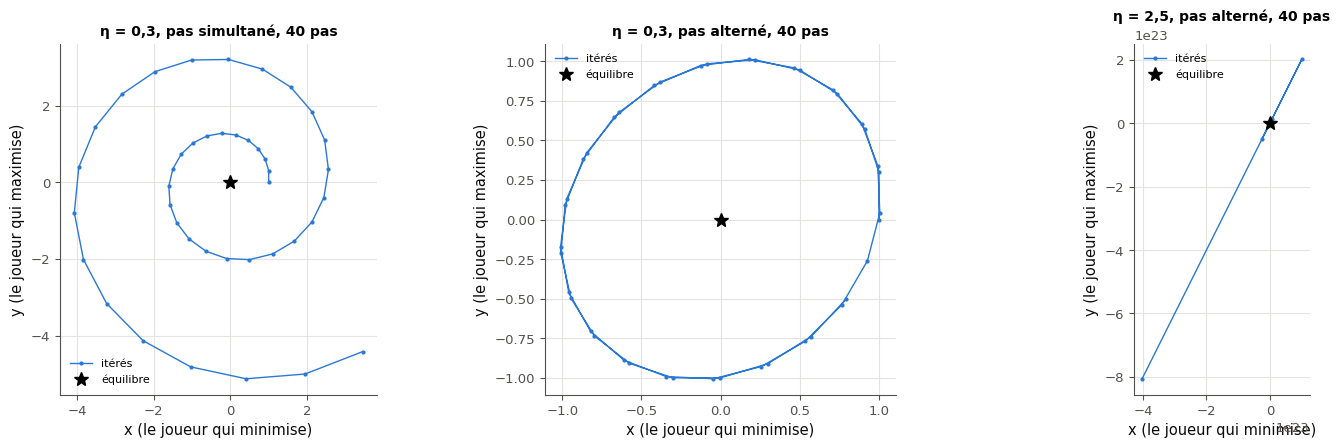

✅ Ex M27.24 : tes trois trajectoires sont dessinées.


In [35]:
descent_ascent_iterates = mymath.distances.descent_ascent_iterates


def draw_paths_24(ax, eta, n_steps, alternating):
    """In ax, with your descent_ascent_iterates: the iterates on xy from (1, 0), joined in order (x horizontal, y
    vertical); the equilibrium (0, 0) marked by a point; axes of the same scale (ax.set_aspect("equal")); a title that
    gives eta and the mode (« simultané » or « alterné »); axis labels. No other axes."""
    xs, ys = descent_ascent_iterates([[1.0]], np.array([1.0]), np.array([0.0]), eta, n_steps=n_steps,
                                     alternating=alternating)
    ax.plot(xs[:, 0], ys[:, 0], "-", lw=1, marker=".", ms=4, label="itérés")
    ax.plot([0.0], [0.0], "k*", ms=10, label="équilibre")
    ax.set_aspect("equal")
    mode = "alterné" if alternating else "simultané"
    ax.set_title(f"η = {eta:g}".replace(".", ",") + f", pas {mode}, {n_steps} pas", fontsize=10)
    ax.set_xlabel("x (le joueur qui minimise)")
    ax.set_ylabel("y (le joueur qui maximise)")
    ax.legend(fontsize=8)


xs_24, ys_24 = descent_ascent_iterates([[1.0]], np.array([1.0]), np.array([0.0]), 0.3, n_steps=40)
answer_M27_24d = float(np.hypot(xs_24[-1, 0], ys_24[-1, 0]))
angles_24 = np.unwrap(np.arctan2(ys_24[:, 0], xs_24[:, 0]))
answer_M27_24e = float((angles_24[-1] - angles_24[0]) / (2 * math.pi))
xs_24, ys_24 = descent_ascent_iterates([[1.0]], np.array([1.0]), np.array([0.0]), 2.5, n_steps=40, alternating=True)
answer_M27_24f = float(math.log10(np.hypot(xs_24[-1, 0], ys_24[-1, 0])))
print("d)", round(answer_M27_24d, 6), " e)", round(answer_M27_24e, 6), " f)", round(answer_M27_24f, 6))
print("   valeurs propres du pas alterné pour η = 2,5 :", np.round(np.linalg.eigvals([[1, -2.5], [2.5, 1 - 6.25]]), 4).tolist())

PATHS_C24 = {key: [arr[:, 0].tolist() for arr in ref_distances.descent_ascent_iterates(
                 [[1.0]], [1.0], [0.0], eta, n_steps=n, alternating=alt)]
             for key, (eta, n, alt) in {"0.3-s": (0.3, 40, False), "0.3-a": (0.3, 40, True),
                                        "2.5-a": (2.5, 40, True), "hidden": (0.45, 12, True)}.items()}   # the iterates expected, [xs, ys], computed by the reference (no value written here)


def look_24(ax, eta, n_steps, alternating, key):
    """What is missing in a drawing of draw_paths_24 (French phrases)."""
    xs, ys = PATHS_C24[key]
    missing = []
    joined = [line for line in ax.lines if str(line.get_linestyle()) not in ("None", "none", "", " ")]
    if not any(np.shape(line.get_xdata()) == np.shape(xs) and np.allclose(line.get_xdata(), xs, rtol=1e-9, atol=1e-12)
               and np.allclose(line.get_ydata(), ys, rtol=1e-9, atol=1e-12) for line in joined):
        missing.append(f"les {n_steps + 1} itérés depuis (1, 0), reliés dans l'ordre par un trait (x en abscisse, y en "
                       "ordonnée ; dessine avec ax.plot, pas plt.plot, qui dessine dans le dernier axe créé)")
    if not points_at(ax, [0.0], [0.0], marker_only=True):
        missing.append("l'équilibre (0, 0), marqué par un point")
    if ax.get_aspect() != 1.0:
        missing.append('des axes de même échelle (ax.set_aspect("equal"))')
    title = ax.get_title().lower()
    eta_texts = (f"{eta:g}", f"{eta:g}".replace(".", ","))
    mode, other = ("altern", "simultan") if alternating else ("simultan", "altern")
    if not any(text in title for text in eta_texts) or mode not in title or other in title:
        missing.append(f"un titre qui donne η ({eta_texts[1]}) et son seul mode ({'alterné' if alternating else 'simultané'})")
    if not ax.get_xlabel() or not ax.get_ylabel():
        missing.append("des noms d'axes")
    return missing


with checked("M27.24"):
    results_24 = []
    report_24 = reporter(results_24, stop=False)
    fig_c24, ax_c24 = plt.subplots()
    try:
        with own_code("M27.24", "draw_paths_24", REF_DISTANCES):
            opened_c24 = drawn(draw_paths_24, ax_c24, 0.45, 12, True)
        missing_c24 = look_24(ax_c24, 0.45, 12, True, "hidden")
    finally:
        plt.close(fig_c24)
    fig_24, axes_24 = plt.subplots(1, 3, figsize=(15, 4.6))
    try:
        opened_24 = list(opened_c24)
        for ax_24, (eta_24, alternating_24, key_24) in zip(axes_24, ((0.3, False, "0.3-s"), (0.3, True, "0.3-a"),
                                                                     (2.5, True, "2.5-a"))):
            with own_code("M27.24", "draw_paths_24", REF_DISTANCES):
                opened_24 += drawn(draw_paths_24, ax_24, eta_24, 40, alternating_24)
            missing_24 = look_24(ax_24, eta_24, 40, alternating_24, key_24)
            mode_24 = "alterné" if alternating_24 else "simultané"
            report_24(not missing_24, f"η = {fr(eta_24, 1)}, {mode_24} : les 41 itérés, l'équilibre, l'échelle, le titre et "
                      "les axes sont là", f"η = {fr(eta_24, 1)}, {mode_24} : il manque " + " ; ".join(missing_24))
        report_24(not missing_c24, "un appel caché de ta fonction (un autre pas, 12 pas alternés) est dessiné juste aussi",
                  "un appel caché de ta fonction (η = 0,45, 12 pas alternés) : il manque " + " ; ".join(missing_c24))
        report_24(not opened_24, "draw_paths_24 dessine dans l'axe reçu",
                  "draw_paths_24 doit dessiner dans l'axe reçu, sans ouvrir de figure")
    except BaseException:
        plt.close(fig_24)
        raise
    fig_24.tight_layout()
    plt.show()
    verdict("M27.24", all(results_24), "tes trois trajectoires sont dessinées.", "relis les lignes ❌ ci-dessus.")

In [36]:
end_24r = path_24r(0.3, 40, False)
wbm.record("M27.24d", float(np.linalg.norm(end_24r[-1])), decimals=6,
           mistakes={"la distance à l'équilibre est la norme √(x² + y²), pas son carré": float(end_24r[-1] @ end_24r[-1]),
                     "d) porte sur les 40 pas simultanés": float(np.linalg.norm(path_24r(0.3, 40, True)[-1]))})
total_24r = float(np.unwrap(np.arctan2(end_24r[:, 1], end_24r[:, 0]))[-1])
wbm.record("M27.24e", total_24r / (2 * math.pi), decimals=6,
           mistakes={"un tour vaut 2π radians : divise l'angle total par 2π": total_24r,
                     "l'angle total se lit sur l'angle déroulé (np.unwrap), pas sur le seul angle du dernier itéré":
                         float(np.arctan2(end_24r[-1, 1], end_24r[-1, 0])) / (2 * math.pi)})
far_alt_24r = float(np.linalg.norm(path_24r(2.5, 40, True)[-1]))
wbm.record("M27.24f", math.log10(far_alt_24r), decimals=6,
           mistakes={"log₁₀, pas le logarithme népérien": math.log(far_alt_24r),
                     "le logarithme de la distance, pas de son carré": math.log10(far_alt_24r ** 2)})

WBM_ANSWER {"coarse_any": {"0": ["7d9a32fc2c2cf413ab8a9149409c84ae17a2e78a63230ee9226e6e0f69699705"]}, "coarser": {"1": ["bdeb16f2d60e914678ba7a7a4a37ecc190f4cabdf8eb2fb9e9a035d4f7db77ca"], "2": ["158165111d15e7eda8c78364b6904231a70cb1ebbfe520d674304b19792d74ca"], "3": ["a1443447eb3e3d1d104d240a0d704f3a88bb60ab126bcc175fd7d513709dc768"], "4": ["369ed6599dcf7f5cf80d639db55dceee6cea1df116590115a174f9d37a438de4"]}, "decimals": 6, "hash": "542c6c9ebbba0a32bc7a21eefa1e468c547d5602ff97fb36102f32d9e90c2e8b", "hash_coarse": "2facec4c967dccae612f9043d3bc4e7b6649581675e167200fddf033b13c7e84", "id": "M27.24d", "kind": "float", "magnitude": 0, "mistakes": {"68add21126e315cc858a4c3f1efffe4c53c7f9f7c89f5293e81c83fdb14d3173": "la distance à l'équilibre est la norme √(x² + y²), pas son carré", "e0219963e65de46db431adebb763dc18ebde1fcc3294f4e24755a95c2923384a": "d) porte sur les 40 pas simultanés"}, "sign": 1}
📝 Ex M27.24d : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["98

**Après l'expérience**, dans ta copie : pourquoi la spirale fait-elle presque deux tours en 40 pas ? Que deviennent la spirale et l'ellipse avec $\eta = 0{,}1$ ? Pourquoi le pas alterné saute-t-il d'un côté à l'autre de l'équilibre pour $\eta = 2{,}5$ ?

💡 Prédictions attendues : a) (C) ; b) (B) ; c) (B). d) $1{,}09^{20} \approx 5{,}6044$. e) $\frac{40\arctan 0{,}3}{2\pi} \approx 1{,}8555$ tour. f) $\approx 23{,}95$ : pour $\eta = 2{,}5$, la trace vaut $-4{,}25$ et les valeurs propres $-0{,}25$ et $-4$ ; la distance est multipliée par 4 environ à chaque pas, en changeant de côté.

### Ex M27.25 — Le biais d'une distance estimée : ‖x̄₁ − x̄₂‖² entre deux échantillons d'une même loi de ℝ³, selon leurs tailles, contre tr Σ₁/n₁ + tr Σ₂/n₂ 🔬 ★★ ⏱️ 30 min
**Objectif :** mesurer par simulation le biais d'une distance estimée entre deux moyennes, le comparer à tr Σ (1/n₁ + 1/n₂), et voir un petit décalage réel s'y noyer.  
**Prérequis :** fiche §9 ; M02c ; Ex M27.15 · **Parcours :** C

Une machine fabrique des cales ; on mesure trois cotes de chacune (en mm), de moyenne $\boldsymbol{\mu} = (80, 25, 6)$ (`MU_25`) et de covariance
$$\boldsymbol{\Sigma} = \begin{pmatrix} 0{,}09 & 0{,}03 & 0 \\ 0{,}03 & 0{,}04 & 0{,}01 \\ 0 & 0{,}01 & 0{,}01 \end{pmatrix}, \qquad \operatorname{tr}\boldsymbol{\Sigma} = 0{,}14\ \text{mm}^2$$
(`SIGMA_25`). Écris `distance_bias_25(mu1, mu2, Sigma, n1, n2, n_rep, rng)`, qui simule `n_rep` paires de séries indépendantes, toutes à la fois avec des tableaux, dans cet ordre : `L = np.linalg.cholesky(Sigma)`, puis la série 1, `mu1 + rng.standard_normal((n_rep, n1, 3)) @ L.T`, puis la série 2, `mu2 + rng.standard_normal((n_rep, n2, 3)) @ L.T` ; elle rend la moyenne, sur les `n_rep` paires, de $\lVert\bar{\mathbf{x}}_1 - \bar{\mathbf{x}}_2\rVert^2$. Écris aussi `draw_bias_25(ax, ns, means, trace)`, qui trace dans l'axe reçu, en échelles logarithmiques, les moyennes des séries de même taille $n$ contre $n$ (des points) et la courbe $2\,\text{trace}/n$ sur toute l'étendue des `ns`, avec des noms d'axes et une légende.

Avec `rng = np.random.default_rng(6425)`, `n_rep = 4000` (`N_REP_25`) et ce même `rng` pour tous les appels, dans l'ordre : deux séries de la même machine (`mu1 = mu2 = MU_25`) pour $(n_1, n_2) = (5, 5)$, $(20, 20)$, $(80, 80)$, $(5, 80)$ et $(80, 5)$ (`SIZES_25`) ; puis, avec `mu2 = MU_25 + SHIFT_25` (un vrai décalage $\boldsymbol{\delta} = (0{,}05 ;\ 0 ;\ 0)$ de la première cote), pour $(5, 5)$ et $(80, 80)$. Relève :
- a) les cinq moyennes, les cinq valeurs $\operatorname{tr}\boldsymbol{\Sigma}\,(\frac{1}{n_1} + \frac{1}{n_2})$, et leurs rapports, moyenne divisée par valeur (une liste de 3 listes de 5 nombres ; 3 décimales pour les rapports dans ta copie) ;
- b) vrai ou faux : les cinq rapports sont à moins de 5 % de 1 ;
- c) avec le décalage, les deux moyennes, puis les mêmes moins $\operatorname{tr}\boldsymbol{\Sigma}\,(\frac{1}{n_1} + \frac{1}{n_2})$, à comparer à $\lVert\boldsymbol{\delta}\rVert^2 = 0{,}0025$ (une liste de 4 nombres) ;
- d) vrai ou faux : avec 5 cales par série, la distance estimée moyenne dépasse vingt fois la vraie distance $\lVert\boldsymbol{\delta}\rVert^2$.

La vérification essaie `distance_bias_25` sur un cas caché, puis appelle `draw_bias_25` sur les trois tailles égales (avec, pour moyennes, les valeurs théoriques $2\operatorname{tr}\boldsymbol{\Sigma}/n$) et affiche la figure ; elle l'appelle aussi sur d'autres tailles (un appel caché). Ce qu'il faut conclure : la distance estimée entre deux séries d'une même machine n'est pas nulle, elle suit $\operatorname{tr}\boldsymbol{\Sigma}\,(\frac{1}{n_1} + \frac{1}{n_2})$ ; un petit décalage réel se noie dans ce biais sur de petites séries ; deux distances estimées ne se comparent qu'à tailles égales, ou après avoir retiré le biais.

In [37]:
MU_25 = np.array([80.0, 25.0, 6.0])                       # the mean of the three dimensions of a shim (mm)
SIGMA_25 = np.array([[0.09, 0.03, 0.0], [0.03, 0.04, 0.01], [0.0, 0.01, 0.01]])   # their covariance (mm²), tr = 0.14
SIZES_25 = [(5, 5), (20, 20), (80, 80), (5, 80), (80, 5)]  # (n1, n2): two series of the same machine
SHIFT_25 = np.array([0.05, 0.0, 0.0])                     # a true shift of the first dimension (mm)
N_REP_25 = 4000                                           # the number of simulated pairs of series

a) [[0.05595, 0.0138, 0.00356, 0.02978, 0.02911], [0.056, 0.014, 0.0035, 0.02975, 0.02975], [0.99913, 0.98553, 1.01843, 1.00096, 0.97843]]
b) True  c) [0.05845, 0.00614, 0.00245, 0.00264]  d) True (rapport 23.4)
✅ distance_bias_25 : un cas caché de ta fonction (deux moyennes différentes, n1 = 7, n2 = 3), comme attendu
✅ draw_bias_25 dessine dans l'axe reçu
✅ les trois moyennes des séries de même taille sont des points
✅ la droite 2 tr Σ / n est tracée de n = 5 à n = 80
✅ les deux échelles sont logarithmiques
✅ des noms d'axes et une légende
✅ un appel caché de draw_bias_25 (d'autres tailles, une autre trace) est dessiné juste aussi


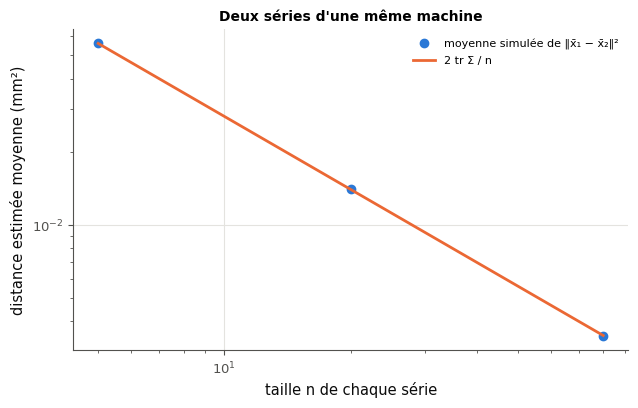

✅ Ex M27.25 : ta simulation et ta figure sont justes.


In [38]:
def distance_bias_25(mu1, mu2, Sigma, n1, n2, n_rep, rng):
    """n_rep pairs of independent series at once: L = np.linalg.cholesky(Sigma), then the series 1,
    mu1 + rng.standard_normal((n_rep, n1, 3)) @ L.T, then the series 2, mu2 + rng.standard_normal((n_rep, n2, 3)) @ L.T;
    returns the mean over the n_rep pairs of ‖x̄1 − x̄2‖²."""
    L = np.linalg.cholesky(np.asarray(Sigma, dtype=float))
    first = np.asarray(mu1, dtype=float) + rng.standard_normal((n_rep, n1, 3)) @ L.T
    second = np.asarray(mu2, dtype=float) + rng.standard_normal((n_rep, n2, 3)) @ L.T
    gap = first.mean(axis=1) - second.mean(axis=1)                       # (n_rep, 3)
    return float((gap ** 2).sum(axis=1).mean())


def draw_bias_25(ax, ns, means, trace):
    """In ax, in log scales on both axes: the means against n (points), and the curve 2 trace / n over the whole range of
    ns; axis labels and a legend. No other axes."""
    n_line = np.geomspace(min(ns), max(ns), 50)
    ax.plot(ns, means, "o", label="moyenne simulée de ‖x̄₁ − x̄₂‖²")
    ax.plot(n_line, 2 * trace / n_line, "-", label="2 tr Σ / n")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("taille n de chaque série")
    ax.set_ylabel("distance estimée moyenne (mm²)")
    ax.set_title("Deux séries d'une même machine", fontsize=10)
    ax.legend(fontsize=8)


rng_25 = np.random.default_rng(6425)
trace_25 = float(np.trace(SIGMA_25))
means_25 = [distance_bias_25(MU_25, MU_25, SIGMA_25, n1, n2, N_REP_25, rng_25) for n1, n2 in SIZES_25]
values_25 = [trace_25 * (1 / n1 + 1 / n2) for n1, n2 in SIZES_25]
ratios_25 = [m / v for m, v in zip(means_25, values_25)]
answer_M27_25a = [means_25, values_25, ratios_25]
answer_M27_25b = bool(all(abs(r - 1) < 0.05 for r in ratios_25))
shifted_25 = [distance_bias_25(MU_25, MU_25 + SHIFT_25, SIGMA_25, n, n, N_REP_25, rng_25) for n in (5, 80)]
answer_M27_25c = shifted_25 + [s - trace_25 * 2 / n for s, n in zip(shifted_25, (5, 80))]
answer_M27_25d = bool(shifted_25[0] > 20 * float(SHIFT_25 @ SHIFT_25))
print("a)", np.round(answer_M27_25a, 5).tolist())
print("b)", answer_M27_25b, " c)", np.round(answer_M27_25c, 5).tolist(), " d)", answer_M27_25d,
      f"(rapport {shifted_25[0] / float(SHIFT_25 @ SHIFT_25):.1f})")

MEANS_C25 = [2 * 0.14 / n for n in (5, 20, 80)]   # the theoretical means 2 tr Σ / n of the equal sizes (the figure, a hint)


def means_hint_25(value):
    """a): means close to the expected ones (within 10 %), not equal to them: the order of the draws."""
    got = np.asarray(value, dtype=float)
    if got.shape == (3, 5) and np.all(np.abs(got[0, :3] / np.array(MEANS_C25) - 1) < 0.1):
        return ("tes moyennes ont le bon ordre de grandeur : les valeurs exactes demandent les tirages de l'énoncé, "
                "dans son ordre (à chaque appel, la série 1 puis la série 2 ; les appels dans l'ordre de SIZES_25 ; le "
                "même rng) et transformés comme lui, mu + z @ L.T avec L = np.linalg.cholesky(Sigma)")
    return None


HIDDEN_C25 = {'mu1': [1.0, 2.0, 3.0],
 'mu2': [1.1, 2.0, 2.9],
 'Sigma': [[0.5, 0.1, 0.0], [0.1, 0.3, 0.0], [0.0, 0.0, 0.2]],
 'n1': 7,
 'n2': 3,
 'n_rep': 500,
 'seed': 6426,
 'want': 0.5119650377703837,
 'second_first': 0.5156903453516299,
 'no_cholesky': 0.21531199682623123,
 'norm': 0.6561501697180852}   # a hidden case of distance_bias_25: its data, the value expected, three classic wrong values

with checked("M27.25"):
    results_25 = []
    report_25 = reporter(results_25, stop=False)
    h_c25 = HIDDEN_C25
    got_c25 = distance_bias_25(np.array(h_c25["mu1"]), np.array(h_c25["mu2"]), np.array(h_c25["Sigma"]), h_c25["n1"],
                               h_c25["n2"], h_c25["n_rep"], np.random.default_rng(h_c25["seed"]))
    try:
        value_c25 = float(got_c25)
    except (TypeError, ValueError):
        value_c25 = float("nan")
    why_c25 = next((text for key, text in (
        ("second_first", "tu tires la série 2 avant la série 1 : la série 1 d'abord, avec le même rng"),
        ("no_cholesky", "les tirages passent par L = np.linalg.cholesky(Sigma) : x = mu + z @ L.T a pour covariance "
                        "L Lᵀ = Σ"),
        ("norm", "la moyenne porte sur ‖x̄₁ − x̄₂‖², le carré de la norme")) if math.isclose(value_c25, h_c25[key],
                                                                                          rel_tol=1e-9)),
                   f"attendu {h_c25['want']:.6g}, reçu {shown(got_c25)}")
    report_25(math.isclose(value_c25, h_c25["want"], rel_tol=1e-9),
              "distance_bias_25 : un cas caché de ta fonction (deux moyennes différentes, n1 = 7, n2 = 3), comme attendu",
              f"distance_bias_25, un cas caché de ta fonction (n1 = 7, n2 = 3, default_rng({h_c25['seed']})) : {why_c25}")
    fig_c25, ax_c25 = plt.subplots()
    try:
        opened_c25 = drawn(draw_bias_25, ax_c25, [3, 9, 27, 81], [0.4, 0.12, 0.035, 0.013], 0.5)
        hidden_ok_c25 = (points_at(ax_c25, [3, 9, 27, 81], [0.4, 0.12, 0.035, 0.013], marker_only=True)
                         and follows(ax_c25, lambda n: 2 * 0.5 / n, 3, 81))
    finally:
        plt.close(fig_c25)
    fig_25, ax_25 = plt.subplots(figsize=(6.5, 4.2))
    try:
        opened_25 = drawn(draw_bias_25, ax_25, [5, 20, 80], list(MEANS_C25), 0.14)
        report_25(not opened_25 and not opened_c25, "draw_bias_25 dessine dans l'axe reçu",
                  "draw_bias_25 doit dessiner dans l'axe reçu, sans ouvrir de figure")
        report_25(points_at(ax_25, [5, 20, 80], MEANS_C25, marker_only=True),
                  "les trois moyennes des séries de même taille sont des points",
                  "il manque les moyennes contre n, en points (un marqueur : ax.plot(ns, means, \"o\"), ou ax.scatter)")
        report_25(follows(ax_25, lambda n: 2 * 0.14 / n, 5, 80), "la droite 2 tr Σ / n est tracée de n = 5 à n = 80",
                  "il manque la courbe y = 2 trace / n, tracée sur toute l'étendue des n reçus")
        report_25(ax_25.get_xscale() == "log" and ax_25.get_yscale() == "log", "les deux échelles sont logarithmiques",
                  "les deux échelles doivent être logarithmiques (ax.set_xscale(\"log\"), ax.set_yscale(\"log\"))")
        report_25(ax_25.get_legend() is not None and ax_25.get_xlabel() != "" and ax_25.get_ylabel() != "",
                  "des noms d'axes et une légende", "draw_bias_25 doit nommer les axes et mettre une légende")
        report_25(hidden_ok_c25, "un appel caché de draw_bias_25 (d'autres tailles, une autre trace) est dessiné juste aussi",
                  "un appel caché de draw_bias_25 (ns = [3, 9, 27, 81], trace = 0,5) : il manque les points ou la courbe "
                  "2 trace / n")
    except BaseException:
        plt.close(fig_25)
        raise
    fig_25.tight_layout()
    plt.show()
    verdict("M27.25", all(results_25), "ta simulation et ta figure sont justes.", "relis les lignes ❌ ci-dessus.")

In [39]:
def series_25r(mu1, mu2, n1, n2, rng):
    """The procedure of the statement, written again: (the mean of ‖x̄1 − x̄2‖², the mean of ‖x̄1 − x̄2‖)."""
    L = np.linalg.cholesky(np.array([[0.09, 0.03, 0.0], [0.03, 0.04, 0.01], [0.0, 0.01, 0.01]]))
    first = mu1 + rng.standard_normal((4000, n1, 3)) @ L.T
    second = mu2 + rng.standard_normal((4000, n2, 3)) @ L.T
    squares = ((first.mean(axis=1) - second.mean(axis=1)) ** 2).sum(axis=1)
    return float(squares.mean()), float(np.sqrt(squares).mean())


mu_25r, sizes_25r = np.array([80.0, 25.0, 6.0]), [(5, 5), (20, 20), (80, 80), (5, 80), (80, 5)]
rng_25r = np.random.default_rng(6425)
both_25r = [series_25r(mu_25r, mu_25r, n1, n2, rng_25r) for n1, n2 in sizes_25r]
shifted_25r = [series_25r(mu_25r, mu_25r + [0.05, 0.0, 0.0], n, n, rng_25r)[0] for n in (5, 80)]
means_25r = [m for m, _ in both_25r]
values_25r = [0.14 * (1 / n1 + 1 / n2) for n1, n2 in sizes_25r]
wbm.record("M27.25a", [means_25r, values_25r, [m / v for m, v in zip(means_25r, values_25r)]], decimals=5,
           mistakes={"le rapport est la moyenne simulée divisée par tr Σ (1/n₁ + 1/n₂)":
                         [means_25r, values_25r, [v / m for m, v in zip(means_25r, values_25r)]],
                     "la moyenne porte sur ‖x̄₁ − x̄₂‖², le carré de la norme":
                         [[r for _, r in both_25r], values_25r, [r / v for (_, r), v in zip(both_25r, values_25r)]],
                     "1/n₁ + 1/n₂ : les deux séries comptent, chacune avec sa taille":
                         [means_25r, [0.14 / n1 for n1, _ in sizes_25r], [m * n1 / 0.14 for m, (n1, _) in zip(means_25r, sizes_25r)]]})
wbm.record("M27.25b", bool(all(abs(m / v - 1) < 0.05 for m, v in zip(means_25r, values_25r))),
           mistakes={"compare chaque rapport à 1 : |rapport − 1| < 0,05": False})
wbm.record("M27.25c", shifted_25r + [s - 0.14 * 2 / n for s, n in zip(shifted_25r, (5, 80))], decimals=6,
           mistakes={"retire tr Σ (1/n₁ + 1/n₂), avec les deux tailles": shifted_25r + [s - 0.14 / n for s, n in zip(shifted_25r, (5, 80))],
                     "les deux moyennes d'abord, puis les mêmes moins le biais":
                         [s - 0.14 * 2 / n for s, n in zip(shifted_25r, (5, 80))] + shifted_25r})
wbm.record("M27.25d", bool(shifted_25r[0] > 20 * 0.0025),
           mistakes={"compare la distance estimée moyenne (5 cales par série, avec le décalage) à vingt fois ‖δ‖²": False})

WBM_ANSWER {"decimals": 5, "element_coarse": [["5c4844d673f9abdaa22ca34b3363fe6f14380118b37af79df055dfbb7a1044c1"], ["11723cd182079f09952a219c325f7bdadb6ee966a5fb126c81c10916c41fa29e"], ["d31c7551069777df940c071f233ea403a917fb884b305f7880c4be0afe9b8402"], ["5d5577b0a6571c87b52b0766bcedb9be7503bca1a4a0228c2cd9fe8778dcac71"], ["2ebe3c94a5ddaee9de47ea4cbb4e3bc9b2e8f763cbe8aaecbac907dbbe826ac7"], ["51521edcc2b7c5bec2a8b4ba829b5feb6dfa445daf707adfa06a0c357cc308e4"], ["467c0a49a201dda131628d15b704da4bbc744dcb55725e99bc04603ca0f37383"], ["da7124c5102110bf2021110ff5be131927afb876eb642cf286d7e660607d0fa9"], ["21c08cc757ef465d8624cf17e94483aee15f6358910b68940c10db8c26fec50f"], ["5c039f0794b3054e076c172d74e2c9602630d748969837097ebeb9233310e8b5"], ["56b871fd09cf699023cc5188b257524cc35fe64394274f4d40f16b80cdb98730"], ["229f33debf0fc33a95ef5d971986376eca16eb016da8f41e2f6ca2e99293515a"], ["969de5c4ffca6a49e140be5a226e1336bd08355298912de5261278eaf41ecb76"], ["81bbdeb20cc9ad42a85fec435d8f57650785e1d452

**Après la figure**, dans ta copie : pourquoi la distance estimée moyenne est-elle divisée par 4 quand $n$ est multiplié par 4 ? Pourquoi $(5, 80)$ et $(80, 5)$ donnent-ils presque la même chose ? Avec 5 cales par série, pourrais-tu voir le décalage de 0,05 mm ?

💡 a) Moyennes $\approx 0{,}0560$ ; $0{,}0138$ ; $0{,}0036$ ; $0{,}0298$ ; $0{,}0291$, contre 0,056 ; 0,014 ; 0,0035 ; 0,02975 ; 0,02975 : des rapports 0,999 ; 0,986 ; 1,018 ; 1,001 ; 0,978. b) Vrai. c) $\approx 0{,}0585$ et $0{,}0061$, puis $0{,}0025$ et $0{,}0026$ une fois le biais retiré, à comparer à 0,0025. d) Vrai : $0{,}0585 / 0{,}0025 \approx 23$. Sur la figure, les trois points suivent la droite $2\operatorname{tr}\boldsymbol{\Sigma}/n$, de pente $-1$ en échelles logarithmiques.

### Ex M27.26 — Deux fonctions de répartition sur une même figure : l'aire entre elles (W₁) et leur plus grand écart vertical (KS), pour une translation puis une dilatation 🎨 ★ ⏱️ 25 min
**Objectif :** dessiner deux fonctions de répartition, l'aire entre elles et leur plus grand écart, et voir ce que W₁ et KS mesurent et ce qu'un changement d'unité leur fait.  
**Prérequis :** fiche §8 et §10 ; Ex M27.8 et M27.10 · **Parcours :** C, E

Écris `draw_cdf_gaps_26(ax, cdf_a, cdf_b, grid, label_a, label_b, unit)`, qui dessine sur l'**axe reçu** (sans ouvrir de figure) les deux fonctions de répartition `cdf_a` et `cdf_b` évaluées sur `grid` (une courbe chacune, de labels `label_a` et `label_b`, avec une légende), colore l'aire entre elles (`ax.fill_between`), trace un segment vertical d'une courbe à l'autre là où leur écart $\lvert F - G\rvert$ est le plus grand sur la grille, et met en titre les deux nombres $W_1$ (l'aire entre les courbes, par la méthode des trapèzes, `np.trapezoid`), avec son unité `unit`, et KS (le plus grand écart sur la grille) ; elle rend `(w1, ks)`.

La vérification l'appelle trois fois et affiche les figures : une **translation**, la température d'un local, $\mathcal{N}(20 ;\ 2^2)$ contre $\mathcal{N}(21{,}2 ;\ 2^2)$ en °C, sur `np.linspace(10, 32, 4401)` (`ROOM_A_26`, `ROOM_B_26`, `GRID_C_26`) ; une **dilatation**, une attente à un guichet, la loi exponentielle de moyenne 2 contre celle de moyenne 5, en minutes, sur `np.linspace(0, 80, 16001)` (`WAIT_A_26`, `WAIT_B_26`, `GRID_MIN_26` ; `scipy.stats.expon(scale=2).cdf`) ; la même translation en °F, $\mathcal{N}(68 ;\ 3{,}6^2)$ contre $\mathcal{N}(70{,}16 ;\ 3{,}6^2)$, sur la grille $1{,}8 \times$ `grid` $+ 32$ (`ROOM_A_F_26`, `ROOM_B_F_26`, `GRID_F_26`) ; elle l'appelle aussi sur deux autres lois (un appel caché). Relève, avec ta fonction (appelle-la sur l'axe d'une figure que tu fermes aussitôt, `fig, ax = plt.subplots()` puis `plt.close(fig)`, pour ne pas afficher la figure deux fois) :
- a) `(w1, ks)` pour la translation (une liste de 2 nombres ; 3 décimales dans ta copie) ;
- b) `(w1, ks)` pour la dilatation (une liste de 2 nombres ; 3 décimales dans ta copie) ;
- c) `(w1, ks)` en °F (une liste de 2 nombres ; 3 décimales dans ta copie).

Ce qu'il faut observer : pour la translation, l'aire vaut le décalage, et l'écart vertical est le plus grand au milieu ; pour la dilatation, les deux courbes partent du même point et s'écartent, puis se rejoignent ; un changement d'unité multiplie $W_1$ et laisse KS intact.

In [40]:
GRID_C_26 = np.linspace(10, 32, 4401)                     # the translation: a room, in °C
ROOM_A_26, ROOM_B_26 = stats.norm(20, 2).cdf, stats.norm(21.2, 2).cdf
GRID_MIN_26 = np.linspace(0, 80, 16001)                   # the dilatation: a wait at a counter, in minutes
WAIT_A_26, WAIT_B_26 = stats.expon(scale=2).cdf, stats.expon(scale=5).cdf
GRID_F_26 = 1.8 * GRID_C_26 + 32                           # the same translation in °F
ROOM_A_F_26, ROOM_B_F_26 = stats.norm(68, 3.6).cdf, stats.norm(70.16, 3.6).cdf

a) [1.2, 0.235823]  b) [2.999999, 0.32573]  c) [2.16, 0.235823]
✅ une translation (°C) : (w1, ks) rendus comme attendu
✅ une translation (°C) : les deux courbes, l'aire, le segment, le titre et la légende sont là
✅ une dilatation (minutes) : (w1, ks) rendus comme attendu
✅ une dilatation (minutes) : les deux courbes, l'aire, le segment, le titre et la légende sont là
✅ la translation en °F : (w1, ks) rendus comme attendu
✅ la translation en °F : les deux courbes, l'aire, le segment, le titre et la légende sont là
✅ un appel caché de ta fonction (deux autres lois, une autre grille) est juste aussi
✅ draw_cdf_gaps_26 dessine dans l'axe reçu


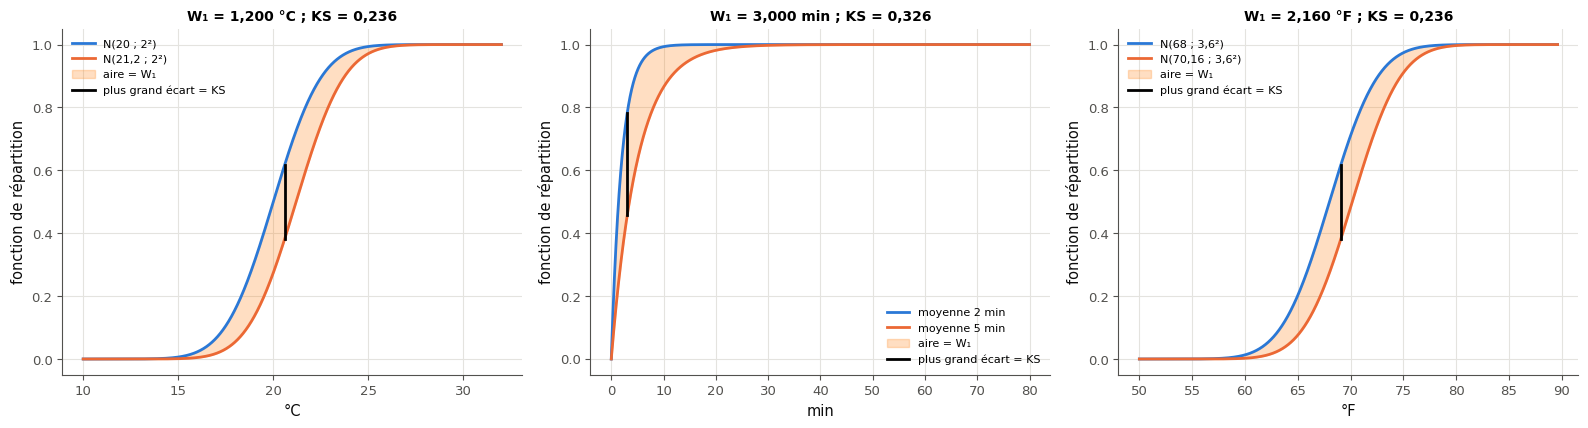

✅ Ex M27.26 : tes trois figures sont justes.


In [41]:
def draw_cdf_gaps_26(ax, cdf_a, cdf_b, grid, label_a, label_b, unit):
    """In ax: the two distribution functions on grid (labels label_a and label_b, and a legend), the area between them
    colored (ax.fill_between), a vertical segment from one curve to the other where |F − G| is largest on the grid, and a
    title with W1 (the area, np.trapezoid, with its unit) and KS (the largest gap on the grid). Returns (w1, ks). No other
    axes."""
    grid = np.asarray(grid, dtype=float)
    F, G = cdf_a(grid), cdf_b(grid)
    gap = np.abs(F - G)
    w1, k = float(np.trapezoid(gap, grid)), int(np.argmax(gap))
    ks = float(gap[k])
    ax.plot(grid, F, label=label_a)
    ax.plot(grid, G, label=label_b)
    ax.fill_between(grid, F, G, color="tab:orange", alpha=0.25, label="aire = W₁")
    ax.plot([grid[k], grid[k]], [F[k], G[k]], "k-", lw=2, label="plus grand écart = KS")
    ax.set_title(f"W₁ = {w1:.3f} {unit} ; KS = {ks:.3f}".replace(".", ","), fontsize=10)
    ax.set_xlabel(unit)
    ax.set_ylabel("fonction de répartition")
    ax.legend(fontsize=8)
    return w1, ks


answers_26 = []
for cdf_a_26, cdf_b_26, grid_26, unit_26 in ((ROOM_A_26, ROOM_B_26, GRID_C_26, "°C"), (WAIT_A_26, WAIT_B_26, GRID_MIN_26, "min"),
                                             (ROOM_A_F_26, ROOM_B_F_26, GRID_F_26, "°F")):
    fig_26, ax_26 = plt.subplots()
    answers_26.append(list(draw_cdf_gaps_26(ax_26, cdf_a_26, cdf_b_26, grid_26, "A", "B", unit_26)))
    plt.close(fig_26)
answer_M27_26a, answer_M27_26b, answer_M27_26c = answers_26
print("a)", np.round(answer_M27_26a, 6).tolist(), " b)", np.round(answer_M27_26b, 6).tolist(), " c)",
      np.round(answer_M27_26c, 6).tolist())

X_STAR_C26 = [20.6, 3.055, 69.08000000000001]   # for each call, the abscissa of the largest gap on the grid ((w1, ks) are checked like a) to c))
HIDDEN_C26 = [0.6678303466666666, 0.29687466666666673, 2.624, 0.265624]   # a hidden call: (w1, ks) expected, the abscissa of the largest gap, and the largest F − G without absolute value


def vertical_at(ax, x, low, high, tol):
    """True when a segment of ax is vertical at x (within tol) and goes from low to high (a line or ax.vlines)."""
    segments = [np.column_stack(line_points(line)) for line in ax.lines]
    for collection in ax.collections:
        if type(collection).__name__ == "LineCollection":
            segments += [np.asarray(s, dtype=float) for s in collection.get_segments()]
    for s in segments:
        if (len(s) >= 2 and np.all(np.abs(s[:, 0] - x) <= tol) and s[:, 1].min() <= low + 1e-6
                and s[:, 1].max() >= high - 1e-6):
            return True
    return False


def look_26(ax, cdf_a, cdf_b, grid, label_a, label_b, unit, x_star):
    """What is missing in a drawing of draw_cdf_gaps_26 (French phrases)."""
    missing = []
    if not (through(ax, grid, cdf_a(grid), rtol=1e-9, atol=1e-12) and through(ax, grid, cdf_b(grid), rtol=1e-9, atol=1e-12)):
        missing.append("les deux fonctions de répartition, évaluées sur grid (une courbe chacune)")
    if not any(type(c).__name__ in ("PolyCollection", "FillBetweenPolyCollection") for c in ax.collections):
        missing.append("l'aire entre elles, colorée (ax.fill_between)")
    low, high = sorted((float(cdf_a(x_star)), float(cdf_b(x_star))))
    if not vertical_at(ax, x_star, low, high, 0.51 * (grid[1] - grid[0])):
        missing.append("le segment vertical du plus grand écart, d'une courbe à l'autre")
    title = ax.get_title()
    if "ks" not in title.lower() or "w" not in title.lower() or unit not in title:
        missing.append(f"un titre avec W₁ (et son unité, {unit}) et KS")
    legend = ax.get_legend()
    texts = [t.get_text() for t in legend.get_texts()] if legend is not None else []
    if label_a not in texts or label_b not in texts:
        missing.append("une légende avec label_a et label_b")
    return missing


def returned_26(label, result, want):
    """The (w1, ks) returned compared with want (a letter: compared like that answer; else a list): '' when right,
    else the reason."""
    try:
        w1, ks = (float(v) for v in result)
    except (TypeError, ValueError):
        return f"draw_cdf_gaps_26 doit rendre le couple (w1, ks), reçu {shown(result)}"
    if isinstance(want, str):                 # a), b) or c): compared like the answer, by wbm.check
        def as_answer(pair_26):
            return wbm.check(f"M27.26{want}", list(pair_26), computed=True, quiet=True).passed
        if as_answer((w1, ks)):
            return ""
        if as_answer((ks, w1)):
            return "tu rends (ks, w1) : rends (w1, ks), dans cet ordre"
        return ("(w1, ks) ne sont pas ceux attendus : W₁ est l'aire entre les deux courbes (np.trapezoid sur grid), "
                "KS le plus grand |F − G| sur grid")
    if math.isclose(w1, want[1], abs_tol=1e-6) and math.isclose(ks, want[0], abs_tol=1e-6):
        return "tu rends (ks, w1) : rends (w1, ks), dans cet ordre"
    if not math.isclose(w1, want[0], abs_tol=1e-6):
        return f"W₁ attendu {want[0]:.6f}, reçu {w1:.6f} (l'aire entre les deux courbes, np.trapezoid sur grid)"
    if math.isclose(ks, want[3], abs_tol=1e-6):
        return ("KS est le plus grand écart en valeur absolue, |F − G| : ici la seconde courbe passe aussi au-dessus de "
                "la première")
    if not math.isclose(ks, want[1], abs_tol=1e-6):
        return f"KS attendu {want[1]:.6f}, reçu {ks:.6f} (le plus grand |F − G| sur grid)"
    return ""


with checked("M27.26"):
    results_26 = []
    report_26 = reporter(results_26, stop=False)
    hidden_a_c26, hidden_b_c26 = stats.uniform(0, 4).cdf, stats.triang(0.25, loc=1, scale=2).cdf
    hidden_grid_c26 = np.linspace(-1, 5, 3001)
    fig_c26, ax_c26 = plt.subplots()
    try:
        result_c26 = []
        opened_c26 = drawn(lambda: result_c26.append(draw_cdf_gaps_26(ax_c26, hidden_a_c26, hidden_b_c26,
                                                                      hidden_grid_c26.copy(), "loi A", "loi B", "m")))
        missing_c26 = look_26(ax_c26, hidden_a_c26, hidden_b_c26, hidden_grid_c26, "loi A", "loi B", "m", HIDDEN_C26[2])
        why_c26 = returned_26("caché", result_c26[0], HIDDEN_C26)
    finally:
        plt.close(fig_c26)
    calls_26 = [("une translation (°C)", ROOM_A_26, ROOM_B_26, GRID_C_26, "N(20 ; 2²)", "N(21,2 ; 2²)", "°C"),
                ("une dilatation (minutes)", WAIT_A_26, WAIT_B_26, GRID_MIN_26, "moyenne 2 min", "moyenne 5 min", "min"),
                ("la translation en °F", ROOM_A_F_26, ROOM_B_F_26, GRID_F_26, "N(68 ; 3,6²)", "N(70,16 ; 3,6²)", "°F")]
    fig_26, axes_26 = plt.subplots(1, 3, figsize=(16, 4.4))
    try:
        opened_26 = list(opened_c26)
        for ax_26, (label_26, cdf_a_26, cdf_b_26, grid_26, la_26, lb_26, unit_26), (letter_26, x_star_26) in zip(
                axes_26, calls_26, zip("abc", X_STAR_C26)):
            result_26 = []
            opened_26 += drawn(lambda: result_26.append(draw_cdf_gaps_26(ax_26, cdf_a_26, cdf_b_26, grid_26.copy(), la_26,
                                                                          lb_26, unit_26)))
            why_26 = returned_26(label_26, result_26[0], letter_26)
            report_26(not why_26, f"{label_26} : (w1, ks) rendus comme attendu", f"{label_26} : {why_26}")
            missing_26 = look_26(ax_26, cdf_a_26, cdf_b_26, grid_26, la_26, lb_26, unit_26, x_star_26)
            report_26(not missing_26, f"{label_26} : les deux courbes, l'aire, le segment, le titre et la légende sont là",
                      f"{label_26} : il manque " + " ; ".join(missing_26))
        report_26(not why_c26 and not missing_c26, "un appel caché de ta fonction (deux autres lois, une autre grille) est "
                  "juste aussi", "un appel caché de ta fonction (deux autres lois, unité « m ») : "
                  + " ; ".join(([why_c26] if why_c26 else []) + (["il manque " + " ; ".join(missing_c26)] if missing_c26 else [])))
        report_26(not opened_26, "draw_cdf_gaps_26 dessine dans l'axe reçu",
                  "draw_cdf_gaps_26 doit dessiner dans l'axe reçu, sans ouvrir de figure")
    except BaseException:
        plt.close(fig_26)
        raise
    fig_26.tight_layout()
    plt.show()
    verdict("M27.26", all(results_26), "tes trois figures sont justes.", "relis les lignes ❌ ci-dessus.")

In [42]:
def gaps_26r(cdf_a, cdf_b, grid):
    """(w1, ks) on the grid, as the statement defines them: the trapezoid area of |F − G|, its largest value."""
    gap = np.abs(cdf_a(grid) - cdf_b(grid))
    return [float(np.sum((gap[1:] + gap[:-1]) / 2 * np.diff(grid))), float(gap.max())]


grid_c_26r = np.linspace(10, 32, 4401)
cases_26r = {"a": gaps_26r(stats.norm(20, 2).cdf, stats.norm(21.2, 2).cdf, grid_c_26r),
             "b": gaps_26r(stats.expon(scale=2).cdf, stats.expon(scale=5).cdf, np.linspace(0, 80, 16001)),
             "c": gaps_26r(stats.norm(68, 3.6).cdf, stats.norm(70.16, 3.6).cdf, 1.8 * grid_c_26r + 32)}
for letter_26r, (w1_26r, ks_26r) in cases_26r.items():
    wrong_26r = {"la fonction rend (w1, ks), dans cet ordre": [ks_26r, w1_26r]}
    if letter_26r == "c":
        wrong_26r["c) se calcule en °F : les lois et la grille sont en °F, et W₁ a l'unité de la variable"] = cases_26r["a"]
    wbm.record(f"M27.26{letter_26r}", [w1_26r, ks_26r], decimals=4, mistakes=wrong_26r)

WBM_ANSWER {"decimals": 4, "element_coarse": [["bdf9c918cf65a779d05c473b5d7fb23baf00fdc0d5c78abb992fea7d6593e4f2"], ["e0326d24e657cf71aa07ab55217a38f73181030e5da967aafdb96a7cec3b6245"]], "element_coarse_any": [["1e637aaf830f40ceb926eca75da614c77e14f24729a1918679a49552245409d2", "069b1a8cfc351c8fe54e2b0c23e24fb70c4c6dbd10e4d447593651af48f40154", "3a5870efa10a06f2cfd3aeac2735689292140326d0d9509e183d534b7d1da5a2"], ["e33ada21419254e0c9db45351850d9fd5207e2e804e009c506a806bed1470875", "e39d689e7416ab3d2dc9ab5bfb5771722494aef906bf1bd6f314ddc2e3c43e41"]], "element_hashes": ["39b1c3b9eebfdcbab3f649df8286c67c771b8dd21dbd8397c0dc817089060c60", "23ea2d3b9bb457418d23daf04e56adc05fc3845bceee12a4b52b2e70c3c5def1"], "hash": "eb7bb76267054e00aa507b3506c7ba1b930201c75051b9134e0729120b7fc9dd", "id": "M27.26a", "kind": "array", "mistakes": {"4a6f376881d64ead7c7f5376b328163e46d44027b52a7f50adc840495bd1d8ac": "la fonction rend (w1, ks), dans cet ordre"}, "shape": [2]}
📝 Ex M27.26a : réponse enregistrée (ar

**Après les figures**, dans ta copie : pourquoi l'écart vertical de la translation est-il le plus grand au milieu ? Pourquoi $W_1$ vaut-il exactement l'écart des moyennes pour la dilatation ? Que mesure KS que $W_1$ ne mesure pas, et inversement ?

💡 a) $(1{,}200 ;\ 0{,}236)$ : $W_1$ est le décalage, et $\mathrm{KS} = 2\Phi(0{,}3) - 1 \approx 0{,}2358$, atteint au milieu, en 20,6 °C. b) $(3{,}000 ;\ 0{,}326)$ : $W_1 = 3$ (l'écart des moyennes : les quantiles $-2\ln(1 - u)$ et $-5\ln(1 - u)$ ne se croisent pas), et l'écart maximal est en $x = \frac{10}{3}\ln 2{,}5 \approx 3{,}05$ min. c) $(2{,}160 ;\ 0{,}236)$.

## Partie C · Déboguer, tester

Fiche §2 et §8. Trois erreurs classiques, qui passent une vérification mal choisie ; un test de propriété des stratégies optimales d'un jeu $2 \times 2$. Les données et les vérifications s'appuient sur la référence (`ref_distances`), pour ne pas dépendre de ton code.

### Ex M27.27 — Chasse à l'erreur : une stratégie d'indifférence calculée sur ses propres gains, W₂ de deux gaussiennes avec des variances, des échantillons appariés sans être triés 🐛 ★ ⏱️ 35 min
**Objectif :** reconnaître trois erreurs classiques sur l'indifférence, W₂ et l'appariement trié, qui passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §2 et §8 ; Ex M27.2, M27.14, M27.16 et M27.20 · **Parcours :** C

Un collègue a écrit trois fonctions, chacune accompagnée d'une vérification qui passe (cellule fournie) :
1. `penalty_kick_mix(G)` doit rendre $p^\star$, la probabilité optimale de la première ligne d'un jeu $2 \times 2$ sans point selle ; elle rend `(d - b) / (a - b - c + d)`. Il l'a vérifiée sur le jeu $\begin{pmatrix} 50 & 90 \\ 90 & 60 \end{pmatrix}$ : $p$ est entre 0 et 1, et les deux colonnes coûtent alors autant au joueur des colonnes, $50p + 90(1 - p) = 90p + 60(1 - p)$. Il l'applique aux tirs au but de M27.2.
2. `w2_settings(mu1, sd1, mu2, sd2)` doit rendre $W_2$ entre deux réglages d'une machine, résumés par leur moyenne et leur écart-type ; elle rend `math.sqrt((mu1 - mu2) ** 2 + (sd1 ** 2 - sd2 ** 2) ** 2)`. Il l'a vérifiée par `w2_settings(0, 1, 3, 1) == 3` et `w2_settings(2, 0, 2, 1) == 1`.
3. `pair_parts(shafts, sleeves)` doit apparier $n$ axes et $n$ bagues, dont on a mesuré les diamètres (en mm), pour que les jeux bague − axe soient aussi réguliers que possible : elle rend un tableau d'entiers `partner`, où `partner[i]` est l'indice de la bague montée sur l'axe `i`, qui minimise $\sum_i(\text{bague} - \text{axe})^2$ (la fiche, §8, et ∂ M27.14 : trier puis apparier). Elle rend `np.argsort(sleeves)`. Il l'a vérifiée avec les axes `[10.00, 10.02, 10.05]` et les bagues `[10.09, 10.06, 10.11]` : elle rend `[1, 0, 2]`, et les jeux valent 0,06 ; 0,07 ; 0,06.

À faire : trouve et corrige chaque erreur ; les fonctions corrigées s'appellent `penalty_kick_mix_fixed`, `w2_settings_fixed` et `pair_parts_fixed`, avec les mêmes arguments (`pair_parts_fixed` rend aussi un tableau NumPy d'entiers). Puis réponds :
- a) $p^\star$ pour les tirs au but (`G_PENALTY`) par `penalty_kick_mix_fixed`, puis ce que rend `penalty_kick_mix` (une liste de 2 nombres) ;
- b) $W_2$ par `w2_settings_fixed` puis par `w2_settings`, pour la machine du 🔗 M27.16 (`SHAFTS_BEFORE`, `SHAFTS_AFTER`), puis de même pour $\mathcal{N}(100 ;\ 5^2)$ contre $\mathcal{N}(100 ;\ 2^2)$ (une liste de 4 nombres) ;
- c) pour les axes `[20.01, 19.98, 20.05, 19.96, 20.03]` et les bagues `[20.10, 20.04, 20.13, 20.07, 20.06]` (`SHAFTS_27`, `SLEEVES_27`) : ce que rend `pair_parts_fixed`, puis $\sum_i(\text{bague} - \text{axe})^2$ (mm²) pour l'appariement corrigé, puis pour celui du collègue (une liste de 7 : les 5 indices, puis les deux sommes).

Dans ta copie : pour chacune des trois erreurs, pourquoi la vérification du collègue ne la voyait pas. La vérification essaie tes corrections sur des cas cachés : des jeux sans symétrie, des écarts-types différents, des axes dans le désordre et des diamètres égaux.

In [43]:
SHAFTS_27 = np.array([20.01, 19.98, 20.05, 19.96, 20.03])   # c): the diameters of five shafts (mm)
SLEEVES_27 = np.array([20.10, 20.04, 20.13, 20.07, 20.06])  # and of five sleeves (mm)


# The colleague's code
def penalty_kick_mix(G):
    """p*, the optimal probability of the first row of a 2 × 2 game without a saddle point."""
    (a, b), (c, d) = np.asarray(G, dtype=float).tolist()
    return (d - b) / (a - b - c + d)


def w2_settings(mu1, sd1, mu2, sd2):
    """W2 between two settings of a machine, summed up by their mean and their standard deviation."""
    return math.sqrt((mu1 - mu2) ** 2 + (sd1 ** 2 - sd2 ** 2) ** 2)


def pair_parts(shafts, sleeves):
    """partner[i], the index of the sleeve mounted on the shaft i, so that Σ (sleeve − shaft)² is smallest."""
    return np.argsort(sleeves)


# The colleague's checks: all pass
p_check_27 = penalty_kick_mix([[50, 90], [90, 60]])
print("(1) 0 ≤ p ≤ 1 :", 0 <= p_check_27 <= 1, "; les deux colonnes coûtent autant :",
      math.isclose(50 * p_check_27 + 90 * (1 - p_check_27), 90 * p_check_27 + 60 * (1 - p_check_27)), "(attendu True, True)")
print("(2)", w2_settings(0, 1, 3, 1) == 3, w2_settings(2, 0, 2, 1) == 1, "(attendu True, True)")
shafts_check_27, sleeves_check_27 = np.array([10.00, 10.02, 10.05]), np.array([10.09, 10.06, 10.11])
partner_check_27 = pair_parts(shafts_check_27, sleeves_check_27)
print("(3)", partner_check_27.tolist() == [1, 0, 2], "; jeux :",
      np.round(sleeves_check_27[partner_check_27] - shafts_check_27, 2).tolist(), "(attendu True ; [0.06, 0.07, 0.06])")

(1) 0 ≤ p ≤ 1 : True ; les deux colonnes coûtent autant : True (attendu True, True)
(2) True True (attendu True, True)
(3) True ; jeux : [0.06, 0.07, 0.06] (attendu True ; [0.06, 0.07, 0.06])


In [44]:
def penalty_kick_mix_fixed(G):
    """p*, the optimal probability of the first row of a 2 × 2 game without a saddle point."""
    (a, b), (c, d) = np.asarray(G, dtype=float).tolist()
    return (d - c) / (a - b - c + d)                 # p* makes the column player indifferent: the columns of G


def w2_settings_fixed(mu1, sd1, mu2, sd2):
    """W2 between two settings of a machine, summed up by their mean and their standard deviation."""
    return math.sqrt((mu1 - mu2) ** 2 + (sd1 - sd2) ** 2)          # standard deviations, not variances


def pair_parts_fixed(shafts, sleeves):
    """partner[i], the index of the sleeve mounted on the shaft i, so that Σ (sleeve − shaft)² is smallest (an array of
    integers)."""
    shafts, sleeves = np.asarray(shafts, dtype=float), np.asarray(sleeves, dtype=float)
    partner = np.empty(len(shafts), dtype=int)
    partner[np.argsort(shafts)] = np.argsort(sleeves)              # the k-th smallest sleeve on the k-th smallest shaft
    return partner


answer_M27_27a = [penalty_kick_mix_fixed(G_PENALTY), penalty_kick_mix(G_PENALTY)]
answer_M27_27b = [w2_settings_fixed(*SHAFTS_BEFORE, *SHAFTS_AFTER), w2_settings(*SHAFTS_BEFORE, *SHAFTS_AFTER),
                  w2_settings_fixed(100, 5, 100, 2), w2_settings(100, 5, 100, 2)]
partner_27 = pair_parts_fixed(SHAFTS_27, SLEEVES_27)
answer_M27_27c = (partner_27.tolist() + [float(((SLEEVES_27[partner_27] - SHAFTS_27) ** 2).sum())]
                  + [float(((SLEEVES_27[pair_parts(SHAFTS_27, SLEEVES_27)] - SHAFTS_27) ** 2).sum())])
print("a)", np.round(answer_M27_27a, 6).tolist(), " b)", np.round(answer_M27_27b, 6).tolist())
print("c)", partner_27.tolist(), np.round(answer_M27_27c[5:], 6).tolist(), "; jeux corrigés :",
      np.round(SLEEVES_27[partner_27] - SHAFTS_27, 2).tolist())

CASES_C27 = {'kicks': [{'G': [[2.0, 7.0], [5.0, 3.0]], 'want': 0.2857142857142857, 'q': 0.5714285714285714},
           {'G': [[9.0, 0.0], [2.0, 5.0]], 'want': 0.25, 'q': 0.4166666666666667},
           {'G': [[-4.0, 5.0], [3.0, -1.0]], 'want': 0.3076923076923077, 'q': 0.46153846153846156}],
 'settings': [{'args': [5.0, 0.3, 5.4, 0.8], 'want': 0.6403124237432851, 'variances': 0.6800735254367725},
              {'args': [-2.0, 4.0, 1.0, 1.5], 'want': 3.905124837953327, 'variances': 14.073467945037569},
              {'args': [0.0, 0.5, 0.0, 2.5], 'want': 2.0, 'variances': 6.0}],
 'parts': [{'shafts': [30.05, 29.96, 29.98, 29.99, 30.03, 30.02],
            'sleeves': [30.07, 30.06, 30.01, 30.11, 30.12, 30.08],
            'best': 0.030199999999999706,
            'sleeves_only': [2, 1, 0, 5, 3, 4],
            'composed': [1, 0, 5, 4, 3, 2]},
           {'shafts': [29.93, 29.99, 30.02, 29.95, 29.96, 29.98, 30.03],
            'sleeves': [30.11, 30.09, 30.1, 30.05, 30.04, 30.14, 30.06],
            'best': 0.07650000000000011,
            'sleeves_only': [4, 3, 6, 1, 2, 0, 5],
            'composed': [4, 1, 2, 0, 3, 6, 5]},
           {'shafts': [5.0, 5.0, 4.98, 5.02],
            'sleeves': [5.06, 5.05, 5.06, 5.04],
            'best': 0.011299999999999892,
            'sleeves_only': [3, 1, 0, 2],
            'composed': [0, 3, 1, 2]}]}   # the hidden cases of the three corrected functions, with what each must give

results_27, parts_27 = [], []


def report_27(ok, success, failure):
    results_27.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


def call_27(part, name, function, *args):
    """function(*args); an error of the learner's code becomes one ❌ line that names the function (the check of this
    part stops there, the final verdict stays)."""
    try:
        return function(*args)
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the function
        report_27(False, "", f"({part}) {name} : ton code lève {type(exc).__name__} : {str(exc)[:200]}")
        parts_27.append(part)
        raise StopCheck from None


with checked("M27.27"):                                       # (1) penalty_kick_mix_fixed
    wrong_27 = []
    for case_c27 in CASES_C27["kicks"]:
        got_c27 = call_27(1, "penalty_kick_mix_fixed", penalty_kick_mix_fixed, np.array(case_c27["G"]))
        try:
            value_c27 = float(got_c27)
        except (TypeError, ValueError):
            value_c27 = float("nan")
        if math.isclose(value_c27, case_c27["want"], rel_tol=1e-9):
            continue
        if math.isclose(value_c27, case_c27["q"], rel_tol=1e-9):
            wrong_27.append("ta fonction rend encore la probabilité qui rend le joueur des LIGNES indifférent ; p* rend "
                            "l'adversaire indifférent (ce que coûtent les deux colonnes)")
        elif math.isclose(value_c27, 1 - case_c27["want"], rel_tol=1e-9):
            wrong_27.append("p* est la probabilité de la première ligne, pas de la seconde")
        elif math.isclose(value_c27, 1 - case_c27["q"], rel_tol=1e-9):
            wrong_27.append("tu rends 1 − q* : p* est la probabilité de la première ligne, qui rend le joueur des colonnes "
                            "indifférent")
        else:
            wrong_27.append(f"un jeu sans symétrie : attendu {case_c27['want']:.6f}, reçu {shown(got_c27)}")
    report_27(not wrong_27, "(1) penalty_kick_mix_fixed : trois jeux cachés, sans symétrie",
              "(1) penalty_kick_mix_fixed : " + " ; ".join(list(dict.fromkeys(wrong_27))[:2]))
    parts_27.append(1)

with checked("M27.27"):                                       # (2) w2_settings_fixed
    wrong_27 = []
    for case_c27 in CASES_C27["settings"]:
        got_c27 = call_27(2, "w2_settings_fixed", w2_settings_fixed, *case_c27["args"])
        try:
            value_c27 = float(got_c27)
        except (TypeError, ValueError):
            value_c27 = float("nan")
        if math.isclose(value_c27, case_c27["want"], rel_tol=1e-9):
            continue
        if math.isclose(value_c27, case_c27["variances"], rel_tol=1e-9):
            wrong_27.append("tu mets encore des variances : la formule soustrait les écarts-types")
        elif math.isclose(value_c27, case_c27["want"] ** 2, rel_tol=1e-9):
            wrong_27.append("ta fonction rend W₂², pas W₂")
        else:
            wrong_27.append(f"(moyenne, écart-type) = {case_c27['args'][:2]} et {case_c27['args'][2:]} : attendu "
                            f"{case_c27['want']:.6f}, reçu {shown(got_c27)}")
    report_27(not wrong_27, "(2) w2_settings_fixed : trois réglages cachés, aux écarts-types différents",
              "(2) w2_settings_fixed : " + " ; ".join(list(dict.fromkeys(wrong_27))[:2]))
    parts_27.append(2)

with checked("M27.27"):                                       # (3) pair_parts_fixed
    wrong_27 = []
    for case_c27 in CASES_C27["parts"]:
        shafts_c27, sleeves_c27 = np.array(case_c27["shafts"]), np.array(case_c27["sleeves"])
        got_c27 = call_27(3, "pair_parts_fixed", pair_parts_fixed, shafts_c27.copy(), sleeves_c27.copy())
        arr_c27 = np.asarray(got_c27)
        n_c27 = len(shafts_c27)
        if arr_c27.shape != (n_c27,) or not np.issubdtype(arr_c27.dtype, np.integer):
            wrong_27.append(f"pair_parts_fixed doit rendre un tableau NumPy d'entiers de {n_c27} indices, reçu "
                            f"{shown(got_c27)[:120]} (dtype {getattr(arr_c27, 'dtype', '?')})")
            continue
        if sorted(arr_c27.tolist()) != list(range(n_c27)):
            wrong_27.append("chaque bague est montée une fois : partner doit contenir chacun des indices 0, …, n − 1")
            continue
        total_c27 = float(((sleeves_c27[arr_c27] - shafts_c27) ** 2).sum())
        if total_c27 <= case_c27["best"] + 1e-12:
            continue
        if arr_c27.tolist() == case_c27["sleeves_only"]:
            wrong_27.append("tu ne ranges encore que les bagues : la k-ième plus petite bague va sur le k-ième plus petit "
                            "axe, quel que soit l'ordre des mesures")
        elif arr_c27.tolist() == case_c27["composed"]:
            wrong_27.append("partner[i] est la bague de l'axe i : la k-ième plus petite bague va sur l'axe de rang k "
                            "(l'indice argsort(shafts)[k]), pas sur l'axe d'indice k")
        else:
            wrong_27.append(f"{n_c27} axes dans le désordre : ta somme des carrés vaut {total_c27:.6f}, la plus petite "
                            f"{case_c27['best']:.6f}")
    report_27(not wrong_27, "(3) pair_parts_fixed : des cas cachés, des axes dans le désordre et des diamètres égaux",
              "(3) pair_parts_fixed : " + " ; ".join(list(dict.fromkeys(wrong_27))[:2]))
    parts_27.append(3)

if len(set(parts_27)) == 3:
    verdict("M27.27", all(results_27), "les trois fonctions corrigées passent tous les cas.", "relis les lignes ❌ ci-dessus.")

a) [0.384615, 0.538462]  b) [0.288617, 0.280253, 3.0, 21.0]
c) [3, 4, 2, 1, 0] [0.0277, 0.0373] ; jeux corrigés : [0.06, 0.08, 0.08, 0.08, 0.07]
✅ (1) penalty_kick_mix_fixed : trois jeux cachés, sans symétrie
✅ (2) w2_settings_fixed : trois réglages cachés, aux écarts-types différents
✅ (3) pair_parts_fixed : des cas cachés, des axes dans le désordre et des diamètres égaux
✅ Ex M27.27 : les trois fonctions corrigées passent tous les cas.


In [45]:
from fractions import Fraction as F_27r
from itertools import permutations

(a_27r, b_27r), (c_27r, d_27r) = (55, 95), (85, 60)
p_27r, q_27r = F_27r(d_27r - c_27r, a_27r - b_27r - c_27r + d_27r), F_27r(d_27r - b_27r, a_27r - b_27r - c_27r + d_27r)
wbm.record("M27.27a", [float(p_27r), float(q_27r)], decimals=6,
           mistakes={"penalty_kick_mix_fixed rend encore la probabilité qui rend le joueur des lignes indifférent":
                         [float(q_27r), float(q_27r)],
                     "la seconde valeur est ce que rend la version FAUSSE, penalty_kick_mix": [float(p_27r), float(p_27r)],
                     "p* est la probabilité de la première ligne": [float(1 - p_27r), float(q_27r)]})
right_27r = lambda m1, s1, m2, s2: math.hypot(m1 - m2, s1 - s2)           # noqa: E731
squares_27r = lambda m1, s1, m2, s2: math.hypot(m1 - m2, s1 ** 2 - s2 ** 2)   # noqa: E731
settings_27r = [(50.30, 0.12, 50.02, 0.05), (100, 5, 100, 2)]
wbm.record("M27.27b", [f(*s) for s in settings_27r for f in (right_27r, squares_27r)], decimals=6,
           mistakes={"w2_settings_fixed met encore des variances : la formule soustrait les écarts-types":
                         [squares_27r(*s) for s in settings_27r for _ in range(2)],
                     "la deuxième et la quatrième valeurs sont celles de la version FAUSSE, w2_settings":
                         [right_27r(*s) for s in settings_27r for _ in range(2)],
                     "w2_settings_fixed doit rendre W₂, pas son carré":
                         [v for s in settings_27r for v in (right_27r(*s) ** 2, squares_27r(*s))]})
shafts_27r, sleeves_27r = [20.01, 19.98, 20.05, 19.96, 20.03], [20.10, 20.04, 20.13, 20.07, 20.06]
total_27r = lambda partner: sum((sleeves_27r[j] - x) ** 2 for x, j in zip(shafts_27r, partner))   # noqa: E731
best_27r = list(min(permutations(range(5)), key=total_27r))              # the oracle: the 120 pairings
colleague_27r = sorted(range(5), key=lambda j: sleeves_27r[j])
composed_27r = [colleague_27r[i] for i in sorted(range(5), key=lambda i: shafts_27r[i])]   # argsort(sleeves)[argsort(shafts)]
wbm.record("M27.27c", best_27r + [total_27r(best_27r), total_27r(colleague_27r)], decimals=6,
           mistakes={"pair_parts_fixed ne range encore que les bagues : les axes aussi arrivent dans le désordre":
                         colleague_27r + [total_27r(colleague_27r), total_27r(colleague_27r)],
                     "la somme de ton appariement d'abord, puis celle du collègue":
                         best_27r + [total_27r(colleague_27r), total_27r(best_27r)],
                     "partner[i] est la bague de l'axe i : la k-ième plus petite bague va sur l'axe de rang k (l'indice "
                     "argsort(shafts)[k]), pas sur l'axe d'indice k":
                         composed_27r + [total_27r(composed_27r), total_27r(colleague_27r)]})

WBM_ANSWER {"array_rounded": {"1": "3db3abef6c262c6e265a842caef3a8e3925c259302c2a64187fe8ad40f305ea0", "2": "bd0dcd971233d3f64f48bdf51612ead6d4a386416b540b02c0de700dc11d3c2e", "3": "df20ad7f4e6f44a8c169cd2faf53cdf8453cb23c20af3bbffc164a486f9b043f", "4": "8d48ca440a6e5a11e39a6894887d9bfc1ea7ae14e3311d6150644916712ed048", "5": "ce30a7a3448eb6fe869c2ad8c2c0adf72dcc2ce78b9ec520239f15c214413793"}, "decimals": 6, "element_coarse": [["55d89ec51c96d6ee62acbdbb1b4e434c8fe27531790bd6fc39db9cce8b95312b"], ["32d5979083d0218c83e9516139d8e758b3ac9868da95535254308cf1cc8abb0d"]], "element_coarse_any": [["e87ffb1188037bd9dcdc6e9840ec74a1bac6caabe3cad05531f617c6286cadf3", "2616d03f525c3d314a69b1e6e33b3201c6b86aa96e736d85aaa4c95c5bb1fa97", "4e3154e128bae0b43f337e69cfb6b00a34a23e01a46c47eddaca167e4c1f8661", "16185651576c2fbce502a75c2e7d351c4cabb0f54308679fb8c60cb6714ef6a7"], ["70b3fc3efc50180ee07d98f545e94566f065c6d23fd74afada4858fa1523f851", "7b6fdccddd67a63e604fb757907f1b5bbf549dc950d436165fd14e495cfc2f

**Après la vérification**, dans ta copie : pour chaque erreur, pourquoi la vérification du collègue ne la voyait-elle pas, et quelle vérification l'aurait vue ?

💡 (1) `penalty_kick_mix` calcule `(d - b) / κ`, la formule de $q^\star$ : elle rend le joueur des lignes indifférent, au lieu de l'adversaire. Sur le jeu symétrique du collègue ($b = c = 90$), $p^\star = q^\star$ : la vérification ne pouvait rien voir. Correction : `(d - c) / κ`. a) $\frac{5}{13} \approx 0{,}3846$ ; la version fautive rend $\frac{7}{13} \approx 0{,}5385$. (2) `w2_settings` met les variances $\sigma^2$ là où la formule veut les écarts-types ; les vérifications prenaient des écarts-types égaux, ou 0 et 1, pour lesquels $\sigma^2 = \sigma$. b) $0{,}2886$ contre $0{,}2803$ pour la machine ; 3 contre 21. (3) `pair_parts` ne trie que les bagues : juste seulement si les axes arrivent déjà triés, comme dans la vérification. Correction : `partner = np.empty(n, dtype=int)` puis `partner[np.argsort(shafts)] = np.argsort(sleeves)`. c) `[3, 4, 2, 1, 0]` ; 0,0277 mm² contre 0,0373 mm².

### Ex M27.28 — Un test de propriété : la valeur d'un jeu 2 × 2 tiré au hasard est entre maximin et minimax, et devient v + c pour G + c et k v pour k G (k > 0) 🛠️ ★ ⏱️ 40 min
**Objectif :** écrire un test de propriété qui compte ses échecs sur des jeux tirés au hasard, voir que les propriétés du titre laissent passer des versions fausses, et en ajouter deux qui les attrapent.  
**Prérequis :** fiche §2 ; Ex M27.20 · **Parcours :** C

La cellule fournie donne quatre versions fausses de `mixed_strategy_value_2x2` : `swapped_pq` (elle rend $(q, p, v)$), `formulas_always` (les formules d'indifférence même quand il y a un point selle, sauf si $\kappa = 0$), `maximin_as_value` (les bonnes stratégies, mais le maximin comme valeur) et `rounded_value` (la valeur arrondie à l'entier).

Écris `game_property_test_28(n_trials, rng, solver=None, tol=1e-9)` ; quand `solver` vaut `None`, le test prend `mymath.distances.mixed_strategy_value_2x2` **au moment de l'appel**. Pour chacun des `n_trials` essais, dans cet ordre : `G = rng.integers(-9, 10, size=(2, 2)).astype(float)`, `c = float(rng.integers(-5, 6))`, `k = float(rng.integers(2, 6))` ; puis `p, q, v = solver(G)`, et le maximin et le minimax de `G`, calculés dans le test par `G.min(axis=1).max()` et `G.max(axis=0).min()`, sans appeler `mymath`. La fonction rend un dictionnaire de cinq compteurs d'essais (un essai compte une fois s'il échoue) :
- `"bounds"` : $v$ sort de $[\text{maximin} - \text{tol} ;\ \text{minimax} + \text{tol}]$, ou $p$ ou $q$ sort de $[-\text{tol} ;\ 1 + \text{tol}]$ ;
- `"shift"` : `solver(G + c)` s'écarte de $(p, q, v + c)$ de plus de `tol` en une coordonnée ;
- `"scale"` : `solver(k * G)` s'écarte de $(p, q, kv)$ de plus de `tol` en une coordonnée ;
- et, **seulement pour les jeux sans point selle** (maximin $<$ minimax), `"transpose"` : `solver(-G.T)` s'écarte de $(q, p, -v)$, et `"swap_rows"` : `solver(G[::-1])` s'écarte de $(1 - p, q, v)$.

Puis :
- a) Dans ta copie : pourquoi des gains entiers, et des $c$ et $k$ entiers ? Pourquoi les deux dernières propriétés seulement sans point selle (essaie $\mathbf{G} = \begin{pmatrix} 2 & 2 \\ 2 & 2 \end{pmatrix}$) ?
- b) Avec `rng = np.random.default_rng(6428)` et 400 essais, avec ta fonction : vrai ou faux, les cinq compteurs sont nuls ;
- c) avec le même départ (un nouveau `default_rng(6428)` chaque fois, 400 essais) et chacune des quatre versions fausses, dans l'ordre `swapped_pq`, `formulas_always`, `maximin_as_value`, `rounded_value` : les cinq compteurs, dans l'ordre `"bounds"`, `"shift"`, `"scale"`, `"transpose"`, `"swap_rows"` (une liste de 4 listes de 5 entiers) ;
- d) les noms des versions fausses qui passent les trois propriétés du titre (`"bounds"`, `"shift"` et `"scale"` nuls) (une liste de noms, dans n'importe quel ordre, comme `["formulas_always"]`).

La vérification lance ton test sur deux départs cachés (150 essais chacun) : avec ta fonction, où ses cinq compteurs doivent valoir ceux de la référence (0), puis avec chacune des quatre versions fausses et avec deux autres versions fausses, écrites dans la cellule de vérification, où ils doivent valoir **exactement** ceux de la référence ; elle le lance aussi une fois avec `rounded_value` et `tol = 1.5` (ton test doit se servir de `tol`). Elle remplace aussi un instant `mymath.distances.mixed_strategy_value_2x2` par une version fausse (une valeur calculée avec $\lvert\kappa\rvert$) : tes compteurs doivent alors compter, comme ceux de la référence. Chacune des cinq propriétés est ainsi exigée par au moins une version fausse. Un entier NumPy convient pour un compteur ; un test qui échoue ne lève pas d'`AssertionError` : il compte. Ce qu'il faut retenir : les propriétés du titre, déjà vérifiées par `tests/test_m27_distances.py`, laissent passer des versions fausses ; l'échange des rôles et l'échange des lignes, qui ne valent que si les stratégies optimales sont uniques, les attrapent ; un test se juge aux erreurs qu'il attrape.

In [46]:
def swapped_pq(G):
    """WRONG: (q, p, v) instead of (p, q, v) (built on the reference)."""
    p, q, v = ref_distances.mixed_strategy_value_2x2(G)
    return q, p, v


def formulas_always(G):
    """WRONG: the indifference formulas even when there is a saddle point (the reference only when κ = 0)."""
    (a, b), (c, d) = np.asarray(G, dtype=float).tolist()
    kappa = a - b - c + d
    if kappa == 0:
        return ref_distances.mixed_strategy_value_2x2(G)
    return (d - c) / kappa, (d - b) / kappa, (a * d - b * c) / kappa


def maximin_as_value(G):
    """WRONG: the right strategies, but the maximin as value."""
    p, q, v = ref_distances.mixed_strategy_value_2x2(G)
    return p, q, ref_distances.pure_strategy_values(G)[0]


def rounded_value(G):
    """WRONG: the value rounded to an integer (Python's round: to the even integer on a tie, round(2.5) = 2)."""
    p, q, v = ref_distances.mixed_strategy_value_2x2(G)
    return p, q, float(round(v))

In [47]:
def game_property_test_28(n_trials, rng, solver=None, tol=1e-9):
    """n_trials random games: G = rng.integers(-9, 10, size=(2, 2)).astype(float), then c = float(rng.integers(-5, 6)),
    then k = float(rng.integers(2, 6)); solver defaults to mymath.distances.mixed_strategy_value_2x2, looked up at the
    call; the maximin and the minimax of G by G.min(axis=1).max() and G.max(axis=0).min(). Returns the numbers of trials
    "bounds", "shift", "scale", "transpose", "swap_rows" that fail (the last two only for games without a saddle point)."""
    solver = solver or mymath.distances.mixed_strategy_value_2x2     # looked up at each call: the check replaces it
    counts = {"bounds": 0, "shift": 0, "scale": 0, "transpose": 0, "swap_rows": 0}

    def off(result, expected):
        """True when one coordinate of result differs from expected by more than tol."""
        return bool(np.max(np.abs(np.asarray(result, dtype=float) - np.asarray(expected, dtype=float))) > tol)

    for _ in range(n_trials):
        G = rng.integers(-9, 10, size=(2, 2)).astype(float)
        c = float(rng.integers(-5, 6))
        k = float(rng.integers(2, 6))
        p, q, v = solver(G)
        maximin, minimax = G.min(axis=1).max(), G.max(axis=0).min()
        counts["bounds"] += int(not (maximin - tol <= v <= minimax + tol and -tol <= p <= 1 + tol and -tol <= q <= 1 + tol))
        counts["shift"] += int(off(solver(G + c), (p, q, v + c)))
        counts["scale"] += int(off(solver(k * G), (p, q, k * v)))
        if maximin < minimax:                                       # optimal strategies unique: no saddle point
            counts["transpose"] += int(off(solver(-G.T), (q, p, -v)))
            counts["swap_rows"] += int(off(solver(G[::-1]), (1 - p, q, v)))
    return counts


mine_28 = game_property_test_28(400, np.random.default_rng(6428))
wrong_28 = {name: game_property_test_28(400, np.random.default_rng(6428), solver=function)
            for name, function in (("swapped_pq", swapped_pq), ("formulas_always", formulas_always),
                                   ("maximin_as_value", maximin_as_value), ("rounded_value", rounded_value))}
COUNTERS_28 = ("bounds", "shift", "scale", "transpose", "swap_rows")
answer_M27_28b = all(mine_28[k] == 0 for k in COUNTERS_28)
answer_M27_28c = [[counts[k] for k in COUNTERS_28] for counts in wrong_28.values()]
answer_M27_28d = [name for name, counts in wrong_28.items() if counts["bounds"] == counts["shift"] == counts["scale"] == 0]
for name_28, counts_28 in {"ta fonction": mine_28, **wrong_28}.items():
    print(f"{name_28:18s}", counts_28)
print("b)", answer_M27_28b, " c)", answer_M27_28c, " d)", answer_M27_28d)
print("la bonne fonction sur [[2, 2], [2, 2]] et sur ses lignes échangées :",
      mymath.distances.mixed_strategy_value_2x2([[2, 2], [2, 2]]))


def absolute_kappa_c28(G):
    """WRONG: without a saddle point, the value (ad − bc)/|κ| (the sign of κ lost)."""
    p, q, v = ref_distances.mixed_strategy_value_2x2(G)
    maximin, minimax, _, _ = ref_distances.pure_strategy_values(G)
    if maximin == minimax:
        return p, q, v
    (a, b), (c, d) = np.asarray(G, dtype=float).tolist()
    return p, q, (a * d - b * c) / abs(a - b - c + d)


def smoothed_p_c28(G):
    """WRONG: without a saddle point, p = (d − c + s)/(κ + 2s), s the sign of κ (a smoothing): p moves with k G."""
    p, q, v = ref_distances.mixed_strategy_value_2x2(G)
    maximin, minimax, _, _ = ref_distances.pure_strategy_values(G)
    if maximin == minimax:
        return p, q, v
    (a, b), (c, d) = np.asarray(G, dtype=float).tolist()
    s = 1.0 if a - b - c + d > 0 else -1.0
    return (d - c + s) / (a - b - c + d + 2 * s), q, v


def clipped_q_c28(G):
    """WRONG: q computed on max(G, 0) (the negative gains set to 0) when both games lack a saddle point: q moves with
    G + c."""
    p, q, v = ref_distances.mixed_strategy_value_2x2(G)
    H = np.maximum(np.asarray(G, dtype=float), 0.0)
    if (ref_distances.pure_strategy_values(G)[0] == ref_distances.pure_strategy_values(G)[1]
            or ref_distances.pure_strategy_values(H)[0] == ref_distances.pure_strategy_values(H)[1]):
        return p, q, v
    return p, ref_distances.mixed_strategy_value_2x2(H)[1], v


with checked("M27.28"):
    results_28 = []
    report_28 = reporter(results_28, stop=False)
    COUNTERS_28 = ('bounds', 'shift', 'scale', 'transpose', 'swap_rows')
    EXPECTED_C28 = {"6441": {"ref": {"bounds": 0, "shift": 0, "scale": 0, "transpose": 0, "swap_rows": 0}, "swapped_pq": {"bounds": 0, "shift": 0, "scale": 0, "transpose": 0, "swap_rows": 40}, "formulas_always": {"bounds": 93, "shift": 0, "scale": 0, "transpose": 0, "swap_rows": 0}, "maximin_as_value": {"bounds": 0, "shift": 0, "scale": 0, "transpose": 40, "swap_rows": 0}, "rounded_value": {"bounds": 0, "shift": 3, "scale": 31, "transpose": 0, "swap_rows": 0}, "smoothed_p_c28": {"bounds": 0, "shift": 0, "scale": 36, "transpose": 40, "swap_rows": 0}, "clipped_q_c28": {"bounds": 0, "shift": 24, "scale": 0, "transpose": 34, "swap_rows": 0}, "absolute_kappa_c28": {"bounds": 9, "shift": 13, "scale": 0, "transpose": 39, "swap_rows": 39}, "rounded_value_tol": {"bounds": 0, "shift": 0, "scale": 11, "transpose": 0, "swap_rows": 0}}, "6442": {"ref": {"bounds": 0, "shift": 0, "scale": 0, "transpose": 0, "swap_rows": 0}, "swapped_pq": {"bounds": 0, "shift": 0, "scale": 0, "transpose": 0, "swap_rows": 40}, "formulas_always": {"bounds": 91, "shift": 0, "scale": 0, "transpose": 0, "swap_rows": 0}, "maximin_as_value": {"bounds": 0, "shift": 0, "scale": 0, "transpose": 41, "swap_rows": 0}, "rounded_value": {"bounds": 0, "shift": 2, "scale": 31, "transpose": 0, "swap_rows": 0}, "smoothed_p_c28": {"bounds": 0, "shift": 0, "scale": 37, "transpose": 40, "swap_rows": 0}, "clipped_q_c28": {"bounds": 0, "shift": 22, "scale": 0, "transpose": 35, "swap_rows": 0}}}   # the reference, per hidden start
    PROPERTIES_C28 = {
        "bounds": "que v est entre maximin − tol et minimax + tol, et p, q entre −tol et 1 + tol",
        "shift": "que solver(G + c) redonne (p, q, v + c) à tol près",
        "scale": "que solver(k G) redonne (p, q, k v) à tol près",
        "transpose": "que solver(−Gᵀ) redonne (q, p, −v), sans point selle",
        "swap_rows": "que solver(G[::-1]) redonne (1 − p, q, v), sans point selle",
    }

    def run_c28(label, seed, **kwargs):
        """Your game_property_test_28 on the hidden start seed (150 trials): its dictionary."""
        try:
            counts = game_property_test_28(150, np.random.default_rng(seed), **kwargs)
        except (NotImplementedError, MymathMissingError):
            raise
        except AssertionError as exc:
            print(f"❌ Ex M27.28 : game_property_test_28 ({label}) lève AssertionError ({str(exc)[:120]}) : l'erreur sort de "
                  "ta fonction ; elle doit compter les essais qui échouent et rendre le dictionnaire, sans assert.")
            raise StopCheck from None
        except Exception as exc:  # noqa: BLE001 - the learner's error
            print(f"❌ Ex M27.28 : game_property_test_28 ({label}) lève {type(exc).__name__} : {str(exc)[:200]}")
            raise StopCheck from None
        if not isinstance(counts, dict) or set(counts) != set(COUNTERS_28):
            print("❌ Ex M27.28 : game_property_test_28 doit rendre un dictionnaire de clés " + ", ".join(COUNTERS_28)
                  + f", reçu {shown(counts)[:160]}")
            raise StopCheck
        for key in COUNTERS_28:
            value = counts[key]
            if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)):
                print(f"❌ Ex M27.28 : le compteur \"{key}\" doit être un nombre entier d'essais (un entier NumPy convient), "
                      f"reçu {type(value).__name__} {value!r}")
                raise StopCheck
        return {key: int(v) for key, v in counts.items()}

    def compare_c28(label, got, want):
        """One ✅ when the five counters equal the reference's; else one ❌ per counter, naming the property."""
        wrong = [k for k in COUNTERS_28 if got[k] != want[k]]
        if not wrong:
            seen = [f"\"{k}\" {want[k]}" for k in COUNTERS_28 if want[k]]
            report_28(True, f"{label} : les cinq compteurs valent ceux de la référence"
                      + (" (" + ", ".join(seen) + ", les autres nuls)" if seen else " (0)"), "")
        for k in wrong:
            if got[k] == 0:
                why = f"ton test ne vérifie pas {PROPERTIES_C28[k]}"
            elif want[k] == 0:
                why = ("cette version ne fausse pas cette propriété : ton contrôle compte trop (sa tolérance, ce qu'il "
                       "compare, ou les jeux sur lesquels il porte)")
            elif got[k] < want[k]:
                why = (f"ton test en compte moins que la référence : il ne vérifie qu'une partie de la propriété "
                       f"({PROPERTIES_C28[k]}), ou il ne tire pas G, puis c, puis k")
            else:
                why = ("un essai compte une fois s'il échoue ; les deux dernières propriétés ne portent que sur les jeux "
                       "sans point selle ; vérifie aussi l'ordre des tirages (G, puis c, puis k)")
            report_28(False, "", f"{label} : \"{k}\" = {got[k]}, la référence {want[k]} : {why}")

    for seed_c28 in (6441, 6442):
        expected_c28 = EXPECTED_C28[str(seed_c28)]
        mine_c28 = run_c28(f"départ caché {seed_c28}", seed_c28)
        wrong_c28 = [k for k in COUNTERS_28 if mine_c28[k] != expected_c28["ref"][k]]
        report_28(not wrong_c28, f"départ caché {seed_c28}, ta fonction : les cinq compteurs valent ceux de la référence (0)",
                  f"départ caché {seed_c28}, ta fonction : " + ", ".join(f"{k} = {mine_c28[k]}" for k in wrong_c28)
                  + " au lieu de 0 : vérifie l'ordre des tirages (G, puis c, puis k), tes tolérances, puis ta "
                  "mixed_strategy_value_2x2 (ses tests, M27.20)")
        for name_c28, function_c28 in (("swapped_pq", swapped_pq), ("formulas_always", formulas_always),
                                       ("maximin_as_value", maximin_as_value), ("rounded_value", rounded_value)):
            got_c28 = run_c28(f"{name_c28}, départ caché {seed_c28}", seed_c28, solver=function_c28)
            compare_c28(f"{name_c28}, départ caché {seed_c28}", got_c28, expected_c28[name_c28])
        for number_c28, (name_c28, function_c28) in enumerate((("smoothed_p_c28", smoothed_p_c28),
                                                                ("clipped_q_c28", clipped_q_c28)), start=1):
            label_c28 = f"une version fausse de vérification (n° {number_c28}), départ caché {seed_c28}"
            compare_c28(label_c28, run_c28(label_c28, seed_c28, solver=function_c28), expected_c28[name_c28])
    compare_c28("rounded_value avec tol = 1,5, départ caché 6441",
                run_c28("rounded_value avec tol = 1,5", 6441, solver=rounded_value, tol=1.5),
                EXPECTED_C28["6441"]["rounded_value_tol"])

    original_c28 = mymath.distances.mixed_strategy_value_2x2
    aliases_c28 = [alias for alias, value in list(globals().items()) if value is original_c28]
    calls_c28 = [0]

    def replaced_c28(G):
        calls_c28[0] += 1
        return absolute_kappa_c28(G)

    mymath.distances.mixed_strategy_value_2x2 = replaced_c28
    for alias_c28 in aliases_c28:
        globals()[alias_c28] = replaced_c28
    try:
        patched_c28 = run_c28("une valeur calculée avec |κ|", 6441)
    finally:
        mymath.distances.mixed_strategy_value_2x2 = original_c28
        for alias_c28 in aliases_c28:
            globals()[alias_c28] = original_c28
    if calls_c28[0] == 0:
        report_28(False, "", "une version fausse remplace un instant ta mixed_strategy_value_2x2, mais ton test ne l'appelle "
                  "jamais : avec solver=None, il doit prendre mymath.distances.mixed_strategy_value_2x2 au moment de "
                  "l'appel, sans en garder une copie")
    else:
        compare_c28("une valeur calculée avec |κ| à la place de ta mixed_strategy_value_2x2", patched_c28,
                    EXPECTED_C28["6441"]["absolute_kappa_c28"])
    verdict("M27.28", all(results_28), "ton test compte juste sur la référence et sur les versions fausses, et prend ta "
            "fonction au moment de l'appel.", "relis les lignes ❌ ci-dessus.")

ta fonction        {'bounds': 0, 'shift': 0, 'scale': 0, 'transpose': 0, 'swap_rows': 0}
swapped_pq         {'bounds': 0, 'shift': 0, 'scale': 0, 'transpose': 0, 'swap_rows': 138}
formulas_always    {'bounds': 222, 'shift': 0, 'scale': 0, 'transpose': 0, 'swap_rows': 0}
maximin_as_value   {'bounds': 0, 'shift': 0, 'scale': 0, 'transpose': 140, 'swap_rows': 0}
rounded_value      {'bounds': 0, 'shift': 3, 'scale': 98, 'transpose': 0, 'swap_rows': 0}
b) True  c) [[0, 0, 0, 0, 138], [222, 0, 0, 0, 0], [0, 0, 0, 140, 0], [0, 3, 98, 0, 0]]  d) ['swapped_pq', 'maximin_as_value']
la bonne fonction sur [[2, 2], [2, 2]] et sur ses lignes échangées : (1.0, 1.0, 2.0)


✅ départ caché 6441, ta fonction : les cinq compteurs valent ceux de la référence (0)
✅ swapped_pq, départ caché 6441 : les cinq compteurs valent ceux de la référence ("swap_rows" 40, les autres nuls)
✅ formulas_always, départ caché 6441 : les cinq compteurs valent ceux de la référence ("bounds" 93, les autres nuls)
✅ maximin_as_value, départ caché 6441 : les cinq compteurs valent ceux de la référence ("transpose" 40, les autres nuls)
✅ rounded_value, départ caché 6441 : les cinq compteurs valent ceux de la référence ("shift" 3, "scale" 31, les autres nuls)
✅ une version fausse de vérification (n° 1), départ caché 6441 : les cinq compteurs valent ceux de la référence ("scale" 36, "transpose" 40, les autres nuls)
✅ une version fausse de vérification (n° 2), départ caché 6441 : les cinq compteurs valent ceux de la référence ("shift" 24, "transpose" 34, les autres nuls)
✅ départ caché 6442, ta fonction : les cinq compteurs valent ceux de la référence (0)
✅ swapped_pq, départ caché 6442 : 

In [48]:
def variant_28r(seed, solver, all_games=False, order="ck"):
    """The test of the statement written again on 400 trials, with two classic variants: the last two properties on every
    game (all_games), or c and k drawn in the other order (order="kc")."""
    rng, counts = np.random.default_rng(seed), dict.fromkeys(("bounds", "shift", "scale", "transpose", "swap_rows"), 0)
    for _ in range(400):
        G = rng.integers(-9, 10, size=(2, 2)).astype(float)
        if order == "ck":
            c, k = float(rng.integers(-5, 6)), float(rng.integers(2, 6))
        else:
            k, c = float(rng.integers(2, 6)), float(rng.integers(-5, 6))
        p, q, v = solver(G)
        low, high = G.min(axis=1).max(), G.max(axis=0).min()
        far = lambda got, want: bool(np.max(np.abs(np.asarray(got, dtype=float) - want)) > 1e-9)   # noqa: E731
        counts["bounds"] += int(not (low - 1e-9 <= v <= high + 1e-9 and -1e-9 <= p <= 1 + 1e-9 and -1e-9 <= q <= 1 + 1e-9))
        counts["shift"] += int(far(solver(G + c), [p, q, v + c]))
        counts["scale"] += int(far(solver(k * G), [p, q, k * v]))
        if low < high or all_games:
            counts["transpose"] += int(far(solver(-G.T), [q, p, -v]))
            counts["swap_rows"] += int(far(solver(G[::-1]), [1 - p, q, v]))
    return list(counts.values())


versions_28r = [swapped_pq, formulas_always, maximin_as_value, rounded_value]
table_28r = [variant_28r(6428, f) for f in versions_28r]
wbm.record("M27.28b", True,
           mistakes={"avec une fonction juste, aucun compteur ne compte : un compteur non nul vient de ton test (ses "
                     "tolérances, ses comparaisons) ou de ta fonction": False})
wbm.record("M27.28c", table_28r,
           mistakes={"les deux dernières propriétés ne portent que sur les jeux sans point selle":
                         [variant_28r(6428, f, all_games=True) for f in versions_28r],
                     "tire dans l'ordre de l'énoncé : G, puis c, puis k": [variant_28r(6428, f, order="kc") for f in versions_28r],
                     "ton test ne compte encore ni \"transpose\" ni \"swap_rows\" : les deux dernières propriétés, sur les "
                     "jeux sans point selle": [row[:3] + [0, 0] for row in table_28r]})
passing_28r = {name for name, row in zip(("swapped_pq", "formulas_always", "maximin_as_value", "rounded_value"), table_28r)
               if row[0] == row[1] == row[2] == 0}
missing_28r = sorted(passing_28r)
wbm.record("M27.28d", passing_28r,
           mistakes={"il en manque une : une version passe si ses trois compteurs \"bounds\", \"shift\" et \"scale\" sont "
                     "nuls (relis tes compteurs de c)": {missing_28r[0]},
                     "il en manque une : relis, dans c), les trois premiers compteurs de chaque version": {missing_28r[1]},
                     "rounded_value fausse \"scale\" (et parfois \"shift\") : elle ne passe pas les trois propriétés":
                         passing_28r | {"rounded_value"},
                     "formulas_always fausse \"bounds\" : elle ne passe pas les trois propriétés":
                         passing_28r | {"formulas_always"}})

WBM_ANSWER {"hash": "9ec10382d47af88ec026806c6f3419291a538765013385f4113a898ef4cadd8a", "id": "M27.28b", "kind": "bool", "mistakes": {"6bc7275e9c55937498bd86078546c3b5132554ccb1aa05058946450963f3a1a3": "avec une fonction juste, aucun compteur ne compte : un compteur non nul vient de ton test (ses tolérances, ses comparaisons) ou de ta fonction"}}
📝 Ex M27.28b : réponse enregistrée (bool).


WBM_ANSWER {"decimals": 0, "element_hashes": ["8385c2f4b980a8c976421c40836b82e48f65978a5a71f9b1cb613032bc1e185d", "c68888ea8412347ddb2931c8118306a6f8adf5453898d7de245b7f0b57d89bd0", "2b12f0d094078b15bde49fd9369e9f4e4cfe723157e110edc12fe9588aefe300", "f899a19ec672916412bd3b34ce62f805906dc0e8f6b034f5db960f91f8e1c8f4", "2000da696f5b5e6870541ac5d324351ca4bf0f6f77dd4ea1aef82691bd3efed5", "c3af527770e83861ce5cb26d39f7e2825bb524d4f574611787e8aac8b27f7819", "c64236fccb7b0e80290b3f5cda1d327c4211fd8d68056c3408884aca38947b96", "4c43b06fac6966c7775f7bf79e4a38a329f7c11b08c7b24ed0c4526dd583fa4a", "aac07338da8c0e9dc48cf8dfe93ff23cafc95bf9a11c566f4a7e9afe7cea5a77", "4ca2d40fbdfd13521dbae327ef0abe31052d0a9308493e89b61f356e48f0e168", "a47fa54a0bccb0ff311cf38459570fb369ba2b271287a1b84cefb069b7e17d06", "9033509ae7955dd5e4ba96b6ee26c5723d35f706a541e2815dc9b750d4b2d354", "146a793467ee74f67c12e35e3314db5a4b910e2f9fcffb2bcd9433c0afc109d0", "48e45dccfac93b0590edae35ccede20b38ce81be2d5810645677f0d3502dc809", "e

**Après la vérification**, dans ta copie : pourquoi les versions fausses de ta réponse d) passent-elles les trois propriétés du titre ? Quelles propriétés, prises ensemble, caractérisent la solution d'un jeu $2 \times 2$ sans point selle ?

💡 a) Avec des entiers, les calculs sont exacts ou presque : la détection du point selle (une comparaison exacte) ne bascule pas quand on ajoute $c$ ou qu'on multiplie par $k$ ; avec des flottants quelconques, un jeu presque à point selle pourrait changer de cas, et le test compterait une fausse alerte. Pour $\begin{pmatrix} 2 & 2 \\ 2 & 2 \end{pmatrix}$, la règle des plus petits indices rend $(1, 1, 2)$ pour $\mathbf{G}$ comme pour $\mathbf{G}$ retournée, alors que la propriété attend $(0, 1, 2)$ ; sans point selle, les stratégies optimales sont uniques. b) Vrai (260 des 400 jeux ont un point selle). c) `swapped_pq` : `\"swap_rows\"` = 138 ; `formulas_always` : `\"bounds\"` = 222 ; `maximin_as_value` : `\"transpose\"` = 140 ; `rounded_value` : `\"scale\"` = 98 et `\"shift\"` = 3 (un arrondi au pair) ; les autres compteurs nuls. d) `swapped_pq` et `maximin_as_value`.

## Partie D · Défi

Fiche §8. La loi normale la plus proche d'une loi exponentielle au sens de W₂, calculée à partir de sa seule fonction quantile, et jugée sur les valeurs exactes de trois lois.

### Ex M27.29 — Défi : la gaussienne la plus proche d'une loi exponentielle au sens de W₂, et cette distance, à 10⁻³ près 🏆 ★★★ ⏱️ 45 min
**Objectif :** trouver la loi normale la plus proche d'une loi donnée par sa fonction quantile, au sens de W₂, et la distance qui reste, à 10⁻³ près.  
**Prérequis :** fiche §8 ; M02a, M02b ; Ex M27.8 et M27.22 · **Parcours :** C

Le temps d'attente à un guichet suit la loi exponentielle de moyenne 2 minutes : $F(x) = 1 - e^{-x/2}$ pour $x \ge 0$, de fonction quantile $F^{-1}(u) = -2\ln(1 - u)$ (`counter_quantile_29`) et de variance 4 (`VARIANCE_29`). On cherche la loi normale $\mathcal{N}(\mu, \sigma^2)$, $\sigma \ge 0$, la plus proche de cette loi au sens de $W_2$, et cette distance.

Écris `closest_gaussian_29(quantile)`, qui reçoit la fonction quantile d'une loi de moment d'ordre 2 fini (une fonction NumPy de $u \in\ ]0, 1[$, qui accepte un tableau) et rend `(mu, sigma, w2)`. Tout NumPy et SciPy sont permis (`scipy.integrate.quad`, `scipy.optimize`, `scipy.stats.norm.ppf`), mais la fonction ne reçoit que la fonction quantile : aucune formule propre à la loi exponentielle.

**Critère de réussite :** `mu`, `sigma` et `w2` à moins de $10^{-3}$ des valeurs exactes pour l'attente au guichet (comparés comme ta réponse a), à 3 décimales), et pour deux lois cachées de la vérification, en moins de 10 secondes par loi ; ces deux lois changent d'échelle et d'origine à chaque exécution (la tolérance suit l'échelle). La vérification refuse une fonction qui rend les mêmes nombres pour trois lois différentes, et reconnaît une variance à la place d'un écart-type, un carré à la place de $W_2$, l'écart-type de la loi à la place du meilleur $\sigma$, et une intégrale trop grossière. Relève :
- a) `(mu, sigma, w2)` pour l'attente au guichet (un tuple de 3, tel que rendu ; 3 décimales dans ta copie) ;
- b) vrai ou faux : $\mu$ est la moyenne de la loi exponentielle ;
- c) $W_2^2$ divisé par la variance de la loi exponentielle (4) : la part de la variance que la meilleure gaussienne ne peut pas rendre (un nombre, en %, tel que calculé ; 1 décimale dans ta copie).

Point de départ : $W_2^2(\mu, \sigma) = \int_0^1\big(F^{-1}(u) - \mu - \sigma\Phi^{-1}(u)\big)^2\,\mathrm{d}u$ (fiche §8) ; une somme sur une grille régulière de $u$ converge lentement, à cause des queues.

In [49]:
def counter_quantile_29(u):
    """The quantile function of the wait at the counter, the exponential law of mean 2 minutes: F⁻¹(u) = −2 ln(1 − u)."""
    return -2.0 * np.log1p(-np.asarray(u, dtype=float))


VARIANCE_29 = 4.0                                          # the variance of this law (min²)

In [50]:
def closest_gaussian_29(quantile):
    """The normal law N(mu, sigma²), sigma >= 0, closest in W2 to the law of quantile function quantile (a NumPy function
    of u in ]0, 1[ that accepts an array), and this distance: returns (mu, sigma, w2). No formula of a particular law."""
    f = lambda u: float(quantile(u))
    mu = integrate.quad(f, 0, 1, limit=200)[0]                                   # the projection on the constant 1
    sigma = integrate.quad(lambda u: f(u) * stats.norm.ppf(u), 0, 1, limit=200)[0]   # on Φ⁻¹ (norm 1, orthogonal to 1)
    second = integrate.quad(lambda u: f(u) ** 2, 0, 1, limit=200)[0]
    return mu, max(sigma, 0.0), math.sqrt(max(second - mu ** 2 - sigma ** 2, 0.0))   # W₂² = 𝕍(X) − σ²


start_29 = time.perf_counter()
answer_M27_29a = closest_gaussian_29(counter_quantile_29)
print(f"a) {answer_M27_29a} en {time.perf_counter() - start_29:.3f} s")
answer_M27_29b = bool(abs(answer_M27_29a[0] - 2.0) < 1e-6)
answer_M27_29c = 100 * answer_M27_29a[2] ** 2 / VARIANCE_29
midpoints_29 = (np.arange(1000) + 0.5) / 1000                                    # the coarse way, for comparison
x_29, z_29 = counter_quantile_29(midpoints_29), stats.norm.ppf(midpoints_29)
print("b)", answer_M27_29b, " c)", round(answer_M27_29c, 4))
print("   σ sur 1 000 points milieux de u : la moyenne de F⁻¹Φ⁻¹", round(float(np.mean(x_29 * z_29)), 5),
      "; les moindres carrés", round(float(np.sum((x_29 - x_29.mean()) * z_29) / np.sum(z_29 ** 2)), 5))

HIDDEN_C29 = [([2.5, 0.8462843753173325, 0.18385525852273368], 0.8660254037844387),
 ([2.999999999999689, 2.010791092025536, 0.6758100204814919], 2.121320343559643)]   # the two hidden laws before a random change of scale and origin: the exact (mu, sigma, w2), and the standard deviation
rng_c29 = np.random.default_rng()   # a new change of scale and origin at each run: no table of values can pass
s_c29, t_c29 = float(rng_c29.uniform(0.5, 3.0)), float(rng_c29.uniform(-5.0, 5.0))


def moved_c29(quantile):
    """The quantile function of s X + t (s > 0): u ↦ s F⁻¹(u) + t."""
    return lambda u: t_c29 + s_c29 * np.asarray(quantile(u), dtype=float)


def moved_law_c29(entry):
    """(mu, sigma, w2) and the standard deviation of s X + t: s mu + t, s sigma, s w2 (W₂ follows the scale), s sd."""
    (mu, sigma, w2), sd = entry
    return [t_c29 + s_c29 * mu, s_c29 * sigma, s_c29 * w2], s_c29 * sd


with checked("M27.29"):
    results_29 = []
    report_29 = reporter(results_29, stop=False)
    tol_29 = 1e-3 * max(1.0, s_c29)                          # 10⁻³, at the scale of the moved laws
    laws_29 = (("l'attente au guichet", counter_quantile_29, None),
               ("une loi uniforme cachée", moved_c29(lambda u: 1.0 + 3.0 * np.asarray(u, dtype=float)),
                moved_law_c29(HIDDEN_C29[0])),
               ("une loi Gamma cachée", moved_c29(stats.gamma(2, scale=1.5).ppf), moved_law_c29(HIDDEN_C29[1])))
    runs_29 = []
    for label_29, quantile_29, law_29 in laws_29:
        start_29 = time.perf_counter()
        result_29 = closest_gaussian_29(quantile_29)
        elapsed_29 = time.perf_counter() - start_29
        triple_29 = pair("M27.29", "closest_gaussian_29", result_29, names=("mu", "sigma", "w2"))
        try:
            triple_29 = tuple(float(v) for v in triple_29)
        except (TypeError, ValueError):
            verdict("M27.29", False, "", f"closest_gaussian_29 doit rendre trois nombres (mu, sigma, w2), reçu {shown(result_29)}")
            raise StopCheck from None
        runs_29.append((label_29, triple_29, elapsed_29, law_29))
    if len({run[1] for run in runs_29}) == 1:
        verdict("M27.29", False, "", "closest_gaussian_29 rend les mêmes nombres pour trois lois différentes : elle doit les "
                "calculer à partir de la fonction quantile reçue")
        raise StopCheck
    for k_29, (label_29, (mu_29, sigma_29, w2_29), elapsed_29, law_29) in enumerate(runs_29):
        if law_29 is None:                   # the wait at the counter: compared like the answer a) (answers.json)
            result_c29 = wbm.check("M27.29a", (mu_29, sigma_29, w2_29), computed=True, quiet=True)
            report_29(result_c29.passed and elapsed_29 < 10, f"{label_29} : (mu, sigma, w2) comme attendu, en "
                      f"{fr(elapsed_29, 2)} s", f"{label_29} : " + (result_c29.message if not result_c29.passed
                                                                   else f"trop lent ({fr(elapsed_29, 1)} s, il faut moins de 10 s)"))
            continue
        (mu_e29, sigma_e29, w2_e29), sd_29 = law_29
        close_29 = [abs(got - want) < tol_29 for got, want in ((mu_29, mu_e29), (sigma_29, sigma_e29), (w2_29, w2_e29))]
        if all(close_29):
            why_29 = ""
        elif k_29 > 0 and all(abs(a - b) < 1e-9 for a, b in zip((mu_29, sigma_29, w2_29), runs_29[0][1])):
            why_29 = "tu rends les nombres de l'attente au guichet : calcule-les à partir de la fonction quantile reçue"
        elif abs(sigma_29 - sigma_e29 ** 2) < tol_29 * max(1.0, sigma_e29 ** 2):
            why_29 = "sigma est un écart-type, pas une variance"
        elif close_29[0] and close_29[1] and abs(w2_29 - w2_e29 ** 2) < tol_29 * max(1.0, w2_e29):
            why_29 = "w2 est la distance W₂, pas son carré"
        elif abs(sigma_29 - sd_29) < tol_29:
            why_29 = ("ton sigma est l'écart-type de la loi : il ne minimise pas W₂ ; écris W₂²(μ, σ) et annule sa dérivée "
                      "en σ")
        elif all(abs(got - want) < 10 * tol_29 for got, want in ((mu_29, mu_e29), (sigma_29, sigma_e29), (w2_29, w2_e29))):
            why_29 = ("à plus de 10⁻³ des valeurs exactes, mais à moins de 10⁻² : un calcul trop grossier, soit une somme sur "
                      "une grille régulière de u (qui converge lentement à cause des queues : scipy.integrate.quad, ou une "
                      "grille resserrée vers 0 et 1), soit une recherche de μ ou de σ sur une grille trop lâche")
        else:
            names_29 = [name for name, ok in zip(("mu", "sigma", "w2"), close_29) if not ok]
            why_29 = (", ".join(names_29) + " à plus de 10⁻³ de la valeur exacte"
                      + f" (attendu ≈ ({mu_e29:.4f}, {sigma_e29:.4f}, {w2_e29:.4f}), reçu ({mu_29:.4f}, {sigma_29:.4f}, {w2_29:.4f}))")
        report_29(not why_29 and elapsed_29 < 10, f"{label_29} : (mu, sigma, w2) à moins de 10⁻³ des valeurs exactes, en "
                  f"{fr(elapsed_29, 2)} s", f"{label_29} : " + (why_29 or f"trop lent ({fr(elapsed_29, 1)} s, il faut moins de "
                                                                       "10 s)"))
    verdict("M27.29", all(results_29), "critère atteint : les trois lois à 10⁻³ près, en moins de 10 secondes chacune.",
            "critère pas encore atteint : relis les lignes ❌ ci-dessus.")

a) (1.9999999999999996, 1.806394568729293, 0.8584513160717203) en 0.035 s
b) True  c) 18.4235
   σ sur 1 000 points milieux de u : la moyenne de F⁻¹Φ⁻¹ 1.80224 ; les moindres carrés 1.80459


✅ l'attente au guichet : (mu, sigma, w2) comme attendu, en 0,03 s
✅ une loi uniforme cachée : (mu, sigma, w2) à moins de 10⁻³ des valeurs exactes, en 0,04 s
✅ une loi Gamma cachée : (mu, sigma, w2) à moins de 10⁻³ des valeurs exactes, en 0,20 s
✅ Ex M27.29 : critère atteint : les trois lois à 10⁻³ près, en moins de 10 secondes chacune.


In [51]:
def projection_29r(quantile):
    """The oracle: μ = ∫ F⁻¹, σ = ∫ F⁻¹ Φ⁻¹, W₂² = ∫ (F⁻¹ − μ − σΦ⁻¹)², by scipy.integrate.quad (high accuracy)."""
    f = lambda u: float(quantile(u))
    mu = integrate.quad(f, 0, 1, limit=400, epsabs=1e-13)[0]
    sigma = integrate.quad(lambda u: f(u) * stats.norm.ppf(u), 0, 1, limit=400, epsabs=1e-13)[0]
    w2sq = integrate.quad(lambda u: (f(u) - mu - sigma * stats.norm.ppf(u)) ** 2, 0, 1, limit=400, epsabs=1e-13)[0]
    return mu, sigma, math.sqrt(w2sq)


mu_29r, sigma_29r, w2_29r = projection_29r(lambda u: -2.0 * math.log1p(-u))
moment_29r = math.sqrt(4 + 4 - 2 * 2 * sigma_29r)                    # W₂ with σ = the standard deviation of the law
wbm.record("M27.29a", [mu_29r, sigma_29r, w2_29r], decimals=3,
           mistakes={"sigma est un écart-type, pas une variance": [mu_29r, sigma_29r ** 2, w2_29r],
                     "w2 est la distance W₂, pas son carré": [mu_29r, sigma_29r, w2_29r ** 2],
                     "le meilleur σ n'est pas l'écart-type de la loi : écris W₂²(μ, σ) et annule sa dérivée en σ":
                         [mu_29r, 2.0, moment_29r]})
wbm.record("M27.29b", bool(abs(mu_29r - 2.0) < 1e-9),
           mistakes={"la dérivée de W₂²(μ, σ) en μ s'annule quand ∫₀¹ (F⁻¹(u) − μ − σΦ⁻¹(u)) du = 0, et ∫₀¹ Φ⁻¹ = 0": False})
wbm.record("M27.29c", 100 * w2_29r ** 2 / 4, decimals=1,
           mistakes={"la part se lit sur W₂², une variance, pas sur W₂": 100 * w2_29r / 4,
                     "divise par la variance de la loi exponentielle, 4 (min²), pas par son écart-type": 100 * w2_29r ** 2 / 2,
                     "la part que la meilleure gaussienne ne peut pas rendre est W₂²/𝕍(X), pas 1 − W₂²/𝕍(X)":
                         100 * (1 - w2_29r ** 2 / 4)})

WBM_ANSWER {"decimals": 3, "element_coarse": [["1ffe0f7f4b5195162214f9347e8c5549833459ab4198a0b25994cc1f7410634b"], ["b56ef3e01214dad9fd92e6b251a9bb6288479659e12692b28d770f404a6cdace"], ["24a9e2bf6ab22ae6fbe9beff0660badc6cd8594213dfd1a10693fe6ef7a7315d"]], "element_coarse_any": [["b2f385e52878e16a1d2714348cbfcfdce28ca4fd0f6d276a2ce22c9341c3893a", "72ed0baad3ed728071153ee2be3fd12747f3b5fb5743db2e98ccc7a1b9c54e79"], ["a005f066de07e539906e4fa98a8f615167cf59f94b0ce7767de6a1ea0f56fcae", "377e0e79ef3c26826f30c033f07e7e57ed600877dd7e4f1df89e2f330925608a"], ["4a6eafde12940c64a3f621b4768a58b4fc2b3dcf1513f206a5198c7bf0481e69", "13dbd261ceab4d88e6a7884f46a9c7a76d48d63bce8839e88cc6893f1f5aaf2b"]], "element_hashes": ["911bc75a991baa1ac28c3673d541897bd32169efcdbddb83e3d61edf76984cd6", "f8b827478e191c73025438497c2bc88fddc1285587781369e1fcd3144a38af30", "3ab7ccda87c3160834055a90cdc441e9a00d789865cf15bdface3130cfd3ac41"], "hash": "91f00f55496faf19efbb38e36a9bd4bc025642c51572dc946893678434d57139", "id":

**Pour réfléchir** : pourquoi $\sigma$ est-il plus petit que l'écart-type de la loi (2) ? Que vaudrait $W_2$ pour une loi normale ? Que devient la part de c) pour une loi uniforme ?

💡 a) $(2{,}000 ;\ 1{,}806 ;\ 0{,}858)$ (plus précisément $\sigma \approx 1{,}80639$ et $W_2 \approx 0{,}85845$). b) Vrai. c) $\frac{0{,}85845^2}{4} \approx 18{,}4$ %. La méthode la plus sûre : dans l'espace des fonctions de carré intégrable sur $]0, 1[$, les fonctions 1 et $\Phi^{-1}$ sont orthogonales ($\int_0^1\Phi^{-1} = 0$) et $\int_0^1(\Phi^{-1})^2 = 1$ ; la meilleure approximation de $F^{-1}$ par $\mu + \sigma\Phi^{-1}$ est sa projection : $\mu = \int_0^1F^{-1} = \mathbb{E}[X]$, $\sigma = \int_0^1F^{-1}\Phi^{-1}$ (positif, puisque $F^{-1}$ et $\Phi^{-1}$ croissent toutes deux), et $W_2^2 = \mathbb{V}(X) - \sigma^2$ ; trois intégrales par `scipy.integrate.quad`. Sur 1 000 points milieux de $u$, la moyenne de $F^{-1}\Phi^{-1}$ donne $\sigma \approx 1{,}8022$, et les moindres carrés $\approx 1{,}8046$ : à $4 \times 10^{-3}$ et $1{,}8 \times 10^{-3}$, trop loin (les queues).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu trouver le maximin, le minimax et les points selles d'une matrice de gains, et réduire un jeu par dominance ?
2. Sais-tu calculer les stratégies optimales et la valeur d'un jeu $2 \times 2$, avec ou sans point selle ?
3. Sais-tu prévoir par les valeurs propres d'un pas ce que fait la descente-montée sur un jeu bilinéaire ?
4. Sais-tu calculer un plan de transport, $W_1$ et $W_2$ en dimension 1, et $W_2$ de deux gaussiennes ?
5. Sais-tu dire pourquoi une distance estimée sur des échantillons est biaisée, et ce que mesurent KS et $W_1$ ?

**La suite** : M28, sur la matrice de Gram, la montée sur l'entrée et les lois tronquées, puis le chapitre 27 de workbookIA, qui applique ces outils aux réseaux génératifs adverses.